IF MORGAN 2048bits is needed change  2048 to 2048 directly in vs code. Also change n_splits, iteration search, n_repeats

In [35]:
"If need to run in vs code delete this cell"
import os
from google.colab import drive

# 1. Mount Google Drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [36]:
disease = "Psoriasis"
protein = "TYK2"
protein = protein.upper()
disease = disease.upper()

In [37]:
"If want to run in vs code change BASE_DIR to Path.cwd()"
import os
from pathlib import Path

# Define the base directory relative to where the notebook was launched
BASE_DIR = Path(f"/content/drive/MyDrive/{disease}_Project")
#---------------------------------------------------------------
#MAIN_DIR = Path.cwd()
#BASE_DIR = MAIN_DIR / f"CHEMBL_{disease}_Project"
output_dir = BASE_DIR / f"CHEMBL_{disease}_{protein}_Project"

# Create the directory once if it doesn't exist
BASE_DIR.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)

print(f"Output directory ready at: {output_dir}")

Output directory ready at: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project


#Now add coconut sdf file and coconut csv file in the output_dir and also cross check the file name.

In [38]:
!pip install chembl_webresource_client rdkit

In [39]:
import numpy as np
import pandas as pd
from chembl_webresource_client.new_client import new_client

target = new_client.target
target_query = target.search(f"{protein}")
targets = pd.DataFrame.from_dict(target_query)
targets

,cross_references,organism,pref_name,score,species_group_flag,target_chembl_id,target_components,target_type,tax_id
0,[],Homo sapiens,Non-receptor tyrosine-protein kinase TYK2,19.0,False,CHEMBL3553,"[{'accession': 'P29597', 'component_descriptio...",SINGLE PROTEIN,9606
1,[],Mus musculus,Non-receptor tyrosine-protein kinase TYK2,19.0,False,CHEMBL2321619,"[{'accession': 'Q9R117', 'component_descriptio...",SINGLE PROTEIN,10090
2,[],Homo sapiens,Protein cereblon/Non-receptor tyrosine-protein...,19.0,False,CHEMBL6066058,"[{'accession': 'P29597', 'component_descriptio...",PROTEIN-PROTEIN INTERACTION,9606
3,[],Homo sapiens,JAK1/TYK2,17.0,False,CHEMBL3301391,"[{'accession': 'P23458', 'component_descriptio...",PROTEIN COMPLEX,9606
4,[],Homo sapiens,JAK2/TYK2,17.0,False,CHEMBL3301392,"[{'accession': 'O60674', 'component_descriptio...",PROTEIN COMPLEX,9606
5,[],Mus musculus,JAK1/TYK2,17.0,False,CHEMBL4523618,"[{'accession': 'P52332', 'component_descriptio...",PROTEIN COMPLEX,10090
6,[],Homo sapiens,JAK1/JAK2/TYK2,15.0,False,CHEMBL3301390,"[{'accession': 'P23458', 'component_descriptio...",PROTEIN COMPLEX,9606
7,[],Mus musculus,TYK2/JAK1/JAK2,15.0,False,CHEMBL3885642,"[{'accession': 'P52332', 'component_descriptio...",PROTEIN FAMILY,10090
8,[],Homo sapiens,Janus Kinase (JAK),13.0,False,CHEMBL2363062,"[{'accession': 'P52333', 'component_descriptio...",PROTEIN FAMILY,9606


Filter for human protein

In [40]:
selected_target = targets[
    (targets.organism == "Homo sapiens")
    & (targets.target_type == "SINGLE PROTEIN")
].target_chembl_id.iloc[0]
selected_target

'CHEMBL3553'

Fetch bioactivity data

In [41]:
import requests

url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"
params = {
    "target_chembl_id": selected_target,
    "standard_type": "IC50",
    "relation": "=",
    "assay_type": "B",
    "limit": 1000,
    "offset": 0,
}

all_activities = []
while True:
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()
    data = response.json()
    activities = data.get("activities", [])
    if not activities:
        break
    all_activities.extend(activities)
    if not data["page_meta"]["next"]:
        break
    params["offset"] += params["limit"]

df = pd.DataFrame(all_activities)
raw_file = os.path.join(BASE_DIR,f"{protein}_IC50_ChEMBL_raw.csv")
df.to_csv(raw_file, index=False)

print(f"Total activity records retrieved: {len(df)}")
print(f"Saved to: {os.path.abspath(raw_file)}")

Total activity records retrieved: 5445
Saved to: /content/drive/MyDrive/PSORIASIS_Project/TYK2_IC50_ChEMBL_raw.csv


In [42]:
# Data preprocessing and pIC50 conversion
df = df[df["standard_units"] == "nM"]
df.dropna(subset=["standard_value"], inplace=True)
df["standard_value"] = df["standard_value"].astype(float)
df = df[df["standard_value"] > 0]
selection = ["molecule_chembl_id", "canonical_smiles", "standard_value"]
df1 = df[selection]

df1 = df1.groupby("canonical_smiles", as_index=False).agg(
    {
        "standard_value": "mean",
        **{col: "first" for col in df1.columns
           if col not in ["canonical_smiles", "standard_value"]},
    }
)

bioactivity_class = ["Active" if float(i) <= 100 else "Inactive"
                     for i in df1.standard_value]
df2 = pd.concat([df1, pd.Series(bioactivity_class, name="bioactivity_class")], axis=1)

def norm_value(input_df):
    norm = [i if i <= 100000000 else 100000000 for i in input_df["standard_value"]]
    input_df["standard_value_norm"] = norm
    return input_df.drop("standard_value", axis=1)

def pIC50(input_df):
    pIC50_list = []
    for i in input_df["standard_value_norm"]:
        molar = i * (10**-9)
        pIC50_list.append(-np.log10(molar))
    input_df["pIC50"] = pIC50_list
    return input_df.drop("standard_value_norm", axis=1)

df3 = norm_value(df2)
df_final = pIC50(df3)
df_final.to_csv(os.path.join(BASE_DIR,f"{protein}_compounds.csv"), index=False)
print(f"Processed dataset saved: {df_final.shape}")

Processed dataset saved: (3346, 4)


In [43]:
# salt removal and lipinski rule of 5
from rdkit import Chem
from rdkit.Chem import Descriptors

df_no_smiles = df_final.drop(columns='canonical_smiles')
smiles = []
for i in df_final.canonical_smiles.tolist():
    cpd = str(i).split('.')
    cpd_longest = max(cpd, key=len)
    smiles.append(cpd_longest)
smiles = pd.Series(smiles, name='canonical_smiles')
df_clean_smiles = pd.concat([df_no_smiles, smiles], axis=1)
df_clean_smiles.head()

,molecule_chembl_id,bioactivity_class,pIC50,canonical_smiles
0,CHEMBL4242999,Active,8.318759,NC(=O)c1cnc2[nH]ccc2c1NC1C2CC3CC1CC(O)(C3)C2
1,CHEMBL3918308,Inactive,6.550162,BrC[C@H]1CC[C@H](c2nnn3cnc4[nH]ccc4c23)CC1
2,CHEMBL3927649,Inactive,6.823909,Brc1ccc(CN2CCC(c3nnn4cnc5[nH]ccc5c34)CC2)cc1
3,CHEMBL3979340,Active,7.008774,Brc1ccc(CN2CCC(c3nnn4cnc5[nH]ccc5c34)CC2)o1
4,CHEMBL3967749,Inactive,6.958607,Brc1ccc(CN2CCC(c3nnn4cnc5[nH]ccc5c34)CC2)s1


In [44]:
def calculate_ro5_properties(smiles):
    molecule = Chem.MolFromSmiles(smiles)
    molecular_weight = Descriptors.ExactMolWt(molecule)
    n_hba = Descriptors.NumHAcceptors(molecule)
    n_hbd = Descriptors.NumHDonors(molecule)
    logp = Descriptors.MolLogP(molecule)

    conditions = [molecular_weight <= 500, n_hba <= 10, n_hbd <= 5, logp <= 5]
    ro5_fulfilled = sum(conditions) >= 3

    return pd.Series(
        [molecular_weight, n_hba, n_hbd, logp, ro5_fulfilled],
        index=["molecular_weight", "n_hba", "n_hbd", "logp", "ro5_fulfilled"],
    )

ro5_properties = df_clean_smiles["canonical_smiles"].apply(calculate_ro5_properties)
ro5_properties.head()

,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled
0,326.174276,4,4,2.0133,True
1,333.058908,3,1,3.2743,True
2,410.085457,4,1,3.7477,True
3,400.064721,5,1,3.3407,True
4,416.041878,5,1,3.8092,True


In [45]:
# Save & filter
molecules = pd.concat([df_clean_smiles, ro5_properties], axis=1)
molecules.to_csv(os.path.join(BASE_DIR,'ro5_properties.csv'), index=False)

molecules_ro5_fulfilled = molecules[molecules["ro5_fulfilled"]]
molecules_ro5_violated = molecules[~molecules["ro5_fulfilled"]]

print(f"# compounds unfiltered: {molecules.shape[0]}")
print(f"# compounds filtered:   {molecules_ro5_fulfilled.shape[0]}")
print(f"# compounds not compliant with Ro5: {molecules_ro5_violated.shape[0]}")

molecules_ro5_fulfilled.to_csv(os.path.join(BASE_DIR,f'ro5_properties_filtered.csv'), index=False)
molecules_ro5_fulfilled.head()

# compounds unfiltered: 3346
# compounds filtered:   3246
# compounds not compliant with Ro5: 100


,molecule_chembl_id,bioactivity_class,pIC50,canonical_smiles,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled
0,CHEMBL4242999,Active,8.318759,NC(=O)c1cnc2[nH]ccc2c1NC1C2CC3CC1CC(O)(C3)C2,326.174276,4,4,2.0133,True
1,CHEMBL3918308,Inactive,6.550162,BrC[C@H]1CC[C@H](c2nnn3cnc4[nH]ccc4c23)CC1,333.058908,3,1,3.2743,True
2,CHEMBL3927649,Inactive,6.823909,Brc1ccc(CN2CCC(c3nnn4cnc5[nH]ccc5c34)CC2)cc1,410.085457,4,1,3.7477,True
3,CHEMBL3979340,Active,7.008774,Brc1ccc(CN2CCC(c3nnn4cnc5[nH]ccc5c34)CC2)o1,400.064721,5,1,3.3407,True
4,CHEMBL3967749,Inactive,6.958607,Brc1ccc(CN2CCC(c3nnn4cnc5[nH]ccc5c34)CC2)s1,416.041878,5,1,3.8092,True


In [46]:
# Descriptive statistics
columns_of_interest = ['molecular_weight', 'n_hba', 'n_hbd', 'logp']

summary_stats2 = molecules_ro5_fulfilled[columns_of_interest].agg(['min', 'max', 'mean', 'std'])
summary_stats2.loc['range'] = summary_stats2.loc['max'] - summary_stats2.loc['min']
print(summary_stats2)

bioactivity_counts = molecules_ro5_fulfilled['bioactivity_class'].value_counts()
print(bioactivity_counts)

       molecular_weight      n_hba     n_hbd      logp
min          213.101445   1.000000  0.000000 -0.404900
max          714.199600  12.000000  5.000000  7.881980
mean         414.638439   5.864449  1.934997  3.002149
std           68.299889   1.507287  1.123949  1.025725
range        501.098155  11.000000  5.000000  8.286880
bioactivity_class
Active      1692
Inactive    1554
Name: count, dtype: int64


In [47]:
# radar plot helpers + imports
import math
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

def calculate_mean_std(dataframe):
    stats = dataframe.describe().T
    stats = stats[["mean", "std"]]
    return stats

def _scale_by_thresholds(stats, thresholds, scaled_threshold):
    for property_name in stats.index:
        if property_name not in thresholds.keys():
            raise KeyError(f"Add property '{property_name}' to scaling variable.")
    stats_scaled = stats.apply(lambda x: x / thresholds[x.name] * scaled_threshold, axis=1)
    return stats_scaled

def _define_radial_axes_angles(n_axes):
    x_angles = [i / float(n_axes) * 2 * math.pi for i in range(n_axes)]
    x_angles += x_angles[:1]
    return x_angles

def plot_radar(y, thresholds, scaled_threshold, properties_labels,
               y_max=None, output_path=None):
    x = _define_radial_axes_angles(len(y))
    y = _scale_by_thresholds(y, thresholds, scaled_threshold)
    y = pd.concat([y, y.head(1)])

    plt.figure(figsize=(6, 6))
    ax = plt.subplot(111, polar=True)

    ax.fill(x, [scaled_threshold] * len(x), "cornflowerblue", alpha=0.2)
    ax.plot(x, y["mean"], "b", lw=3, ls="-")
    ax.plot(x, y["mean"] + y["std"], "orange", lw=2, ls="--")
    ax.plot(x, y["mean"] - y["std"], "orange", lw=2, ls="-.")

    ax.set_theta_offset(math.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_rlabel_position(180)
    plt.xticks(x, [])
    if not y_max:
        y_max = int(ax.get_yticks()[-1])
    plt.ylim(0, y_max)
    plt.yticks(
        range(1, y_max),
        ["5" if i == scaled_threshold else "" for i in range(1, y_max)],
        fontsize=16,
    )
    for i, (angle, label) in enumerate(zip(x[:-1], properties_labels)):
        if angle == 0: ha = "center"
        elif 0 < angle < math.pi: ha = "left"
        elif angle == math.pi: ha = "center"
        else: ha = "right"
        ax.text(x=angle, y=y_max + 1, s=label, size=16,
                horizontalalignment=ha, verticalalignment="center")

    labels = ("rule of five area", "mean", "mean + std", "mean - std")
    ax.legend(labels, loc=(1.1, 0.7), labelspacing=0.3, fontsize=16)

    if output_path:
        plt.savefig(output_path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

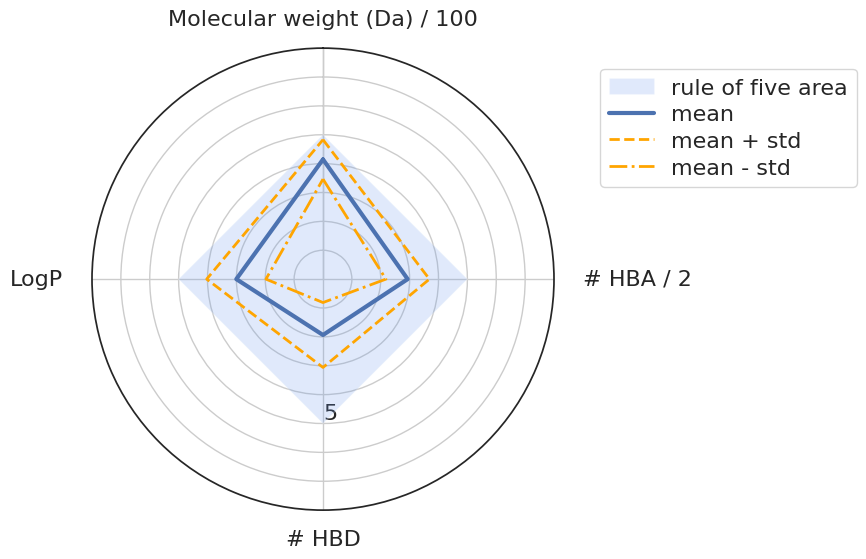

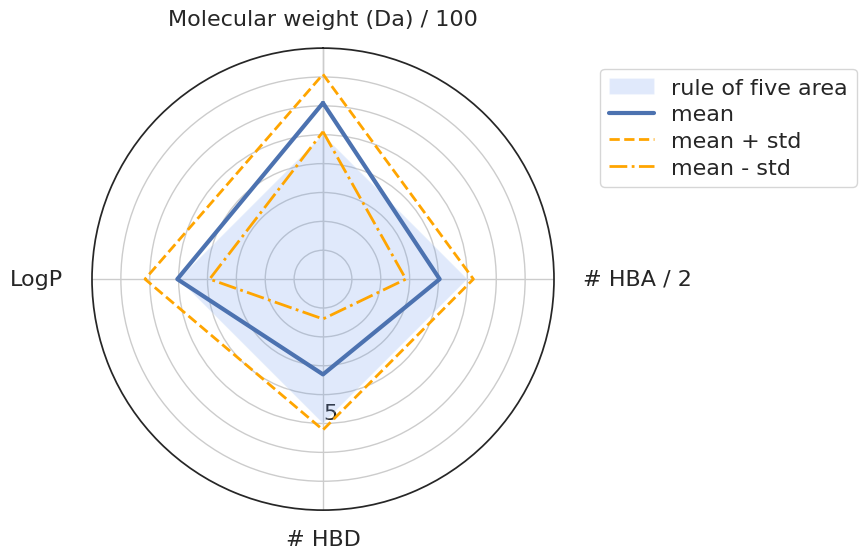

In [48]:
# generate radar plots
thresholds = {"molecular_weight": 500, "n_hba": 10, "n_hbd": 5, "logp": 5}
scaled_threshold = 5
properties_labels = [
    "Molecular weight (Da) / 100",
    "# HBA / 2",
    "# HBD",
    "LogP",
]
y_max = 8

molecules_ro5_fulfilled_stats = calculate_mean_std(
    molecules_ro5_fulfilled[["molecular_weight", "n_hba", "n_hbd", "logp"]]
)
molecules_ro5_violated_stats = calculate_mean_std(
    molecules_ro5_violated[["molecular_weight", "n_hba", "n_hbd", "logp"]]
)

plot_radar(molecules_ro5_fulfilled_stats, thresholds, scaled_threshold,
           properties_labels, y_max, output_path=os.path.join(BASE_DIR,f"radar_plot_ro5_fulfilled.png"))
plot_radar(molecules_ro5_violated_stats, thresholds, scaled_threshold,
           properties_labels, y_max, output_path=os.path.join(BASE_DIR,F"radar_plot_ro5_violated.png"))

Exploratory Data Analysis

In [49]:
import seaborn as sns
sns.set(style='ticks')
from rdkit.Chem import Draw, PandasTools

filtered_compounds = pd.read_csv(os.path.join(BASE_DIR,f'ro5_properties_filtered.csv'))
PandasTools.AddMoleculeColumnToFrame(filtered_compounds, "canonical_smiles")
filtered_compounds.head(5)

,molecule_chembl_id,bioactivity_class,pIC50,canonical_smiles,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled,ROMol
0,CHEMBL4242999,Active,8.318759,NC(=O)c1cnc2[nH]ccc2c1NC1C2CC3CC1CC(O)(C3)C2,326.174276,4,4,2.0133,True,<rdkit.Chem.rdchem.Mol object at 0x7be3ff43fae0>
1,CHEMBL3918308,Inactive,6.550162,BrC[C@H]1CC[C@H](c2nnn3cnc4[nH]ccc4c23)CC1,333.058908,3,1,3.2743,True,<rdkit.Chem.rdchem.Mol object at 0x7be3ff43fa70>
2,CHEMBL3927649,Inactive,6.823909,Brc1ccc(CN2CCC(c3nnn4cnc5[nH]ccc5c34)CC2)cc1,410.085457,4,1,3.7477,True,<rdkit.Chem.rdchem.Mol object at 0x7be3fe4c02e0>
3,CHEMBL3979340,Active,7.008774,Brc1ccc(CN2CCC(c3nnn4cnc5[nH]ccc5c34)CC2)o1,400.064721,5,1,3.3407,True,<rdkit.Chem.rdchem.Mol object at 0x7be419b59e70>
4,CHEMBL3967749,Inactive,6.958607,Brc1ccc(CN2CCC(c3nnn4cnc5[nH]ccc5c34)CC2)s1,416.041878,5,1,3.8092,True,<rdkit.Chem.rdchem.Mol object at 0x7be419b59ee0>


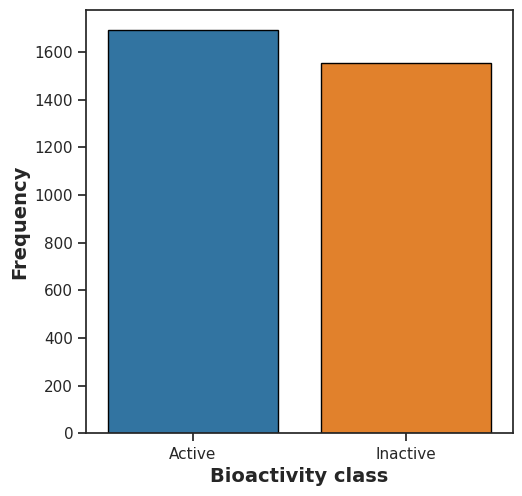

In [50]:
# Bioactivity class count
plt.figure(figsize=(5.5, 5.5))
sns.countplot(x='bioactivity_class', data=filtered_compounds,
              hue='bioactivity_class', edgecolor='black',
              palette=['#1f77b4', '#ff7f0e'])
plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('Frequency', fontsize=14, fontweight='bold')
plt.savefig(os.path.join(BASE_DIR,f'plot_bioactivity_class.png'))
plt.show()

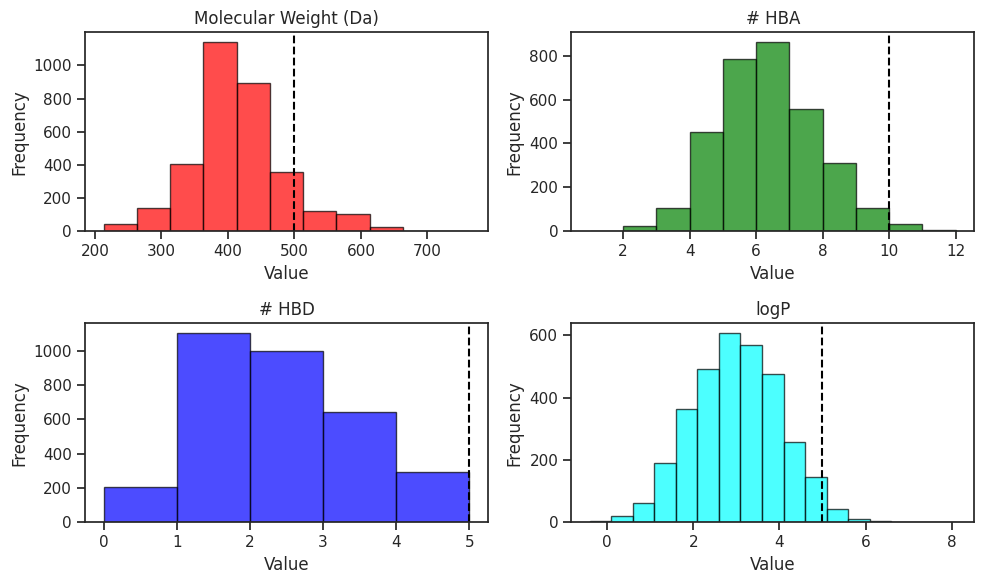

In [51]:
# Ro5 histograms
ro5_properties1 = {
    "molecular_weight": (500, "Molecular Weight (Da)", 50),
    "n_hba": (10, "# HBA", 1),
    "n_hbd": (5, "# HBD", 1),
    "logp": (5, "logP", 0.5),
}

fig, axes = plt.subplots(figsize=(10, 6), nrows=2, ncols=2)
axes = axes.flatten()
colors = ["red", "green", "blue", "cyan"]

for index, (key, (threshold, title, bin_size)) in enumerate(ro5_properties1.items()):
    ax = axes[index]
    bins = np.arange(filtered_compounds[key].min(),
                     filtered_compounds[key].max() + bin_size, bin_size)
    ax.hist(filtered_compounds[key], bins=bins, color=colors[index],
            alpha=0.7, edgecolor="black")
    ax.axvline(x=threshold, color="black", linestyle="dashed",
               linewidth=1.5, label="Threshold")
    ax.set_title(title)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR,f"ro5_histograms_filtered.png"), dpi=300, bbox_inches="tight")
plt.show()

In [52]:
filtered_compounds.head()

,molecule_chembl_id,bioactivity_class,pIC50,canonical_smiles,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled,ROMol
0,CHEMBL4242999,Active,8.318759,NC(=O)c1cnc2[nH]ccc2c1NC1C2CC3CC1CC(O)(C3)C2,326.174276,4,4,2.0133,True,<rdkit.Chem.rdchem.Mol object at 0x7be3ff43fae0>
1,CHEMBL3918308,Inactive,6.550162,BrC[C@H]1CC[C@H](c2nnn3cnc4[nH]ccc4c23)CC1,333.058908,3,1,3.2743,True,<rdkit.Chem.rdchem.Mol object at 0x7be3ff43fa70>
2,CHEMBL3927649,Inactive,6.823909,Brc1ccc(CN2CCC(c3nnn4cnc5[nH]ccc5c34)CC2)cc1,410.085457,4,1,3.7477,True,<rdkit.Chem.rdchem.Mol object at 0x7be3fe4c02e0>
3,CHEMBL3979340,Active,7.008774,Brc1ccc(CN2CCC(c3nnn4cnc5[nH]ccc5c34)CC2)o1,400.064721,5,1,3.3407,True,<rdkit.Chem.rdchem.Mol object at 0x7be419b59e70>
4,CHEMBL3967749,Inactive,6.958607,Brc1ccc(CN2CCC(c3nnn4cnc5[nH]ccc5c34)CC2)s1,416.041878,5,1,3.8092,True,<rdkit.Chem.rdchem.Mol object at 0x7be419b59ee0>


In [53]:
print(filtered_compounds["pIC50"].dtype)

float64


In [54]:
import numpy as np

print("Infinite values:", np.isinf(filtered_compounds["pIC50"]).sum())
print("NaN values:", filtered_compounds["pIC50"].isna().sum())

print(filtered_compounds.loc[
    np.isinf(filtered_compounds["pIC50"]),
    ["pIC50"]
])

Infinite values: 0
NaN values: 0
Empty DataFrame
Columns: [pIC50]
Index: []


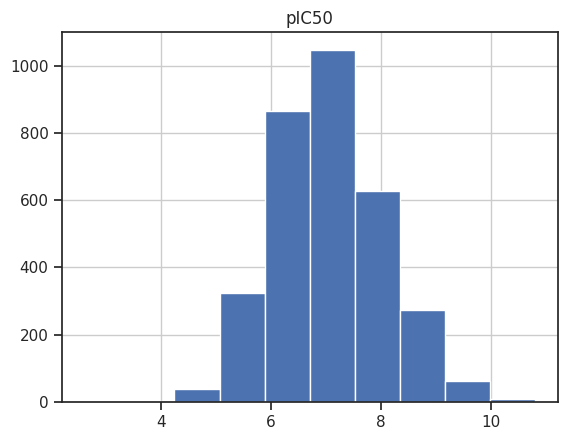

In [55]:
# pIC50 histogram
filtered_compounds.hist(column="pIC50")
plt.savefig(os.path.join(BASE_DIR,f"pIC50_histogram_Ro5_filtered.png"), dpi=300, bbox_inches="tight")
plt.show()

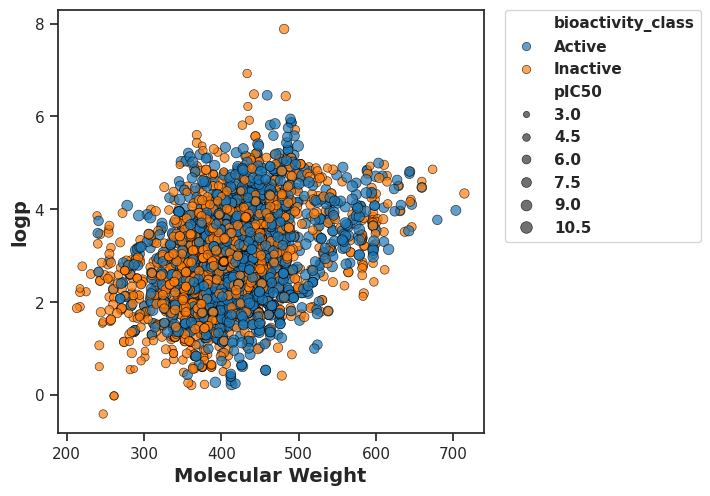

In [56]:
# Scatter plot
plt.figure(figsize=(5.5, 5.5))
sns.scatterplot(x='molecular_weight', y='logp', data=filtered_compounds,
                hue='bioactivity_class', size='pIC50', edgecolor='black',
                alpha=0.7, palette=['#1f77b4', '#ff7f0e'])
plt.xlabel('Molecular Weight', fontsize=14, fontweight='bold')
plt.ylabel('logp', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0, prop={'weight': 'bold'})
plt.savefig(os.path.join(BASE_DIR,f'plot_molecular_weight_vs_logp.png'), bbox_inches='tight', dpi=300)
plt.show()

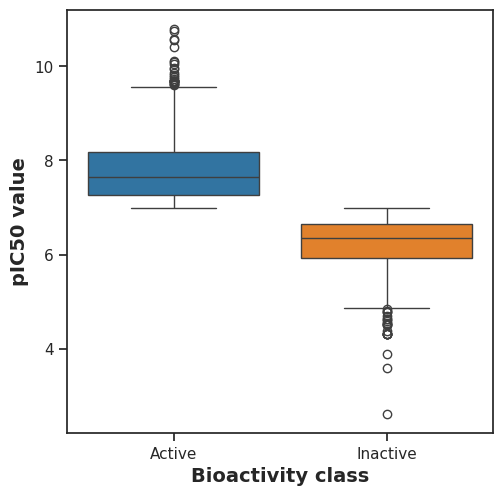

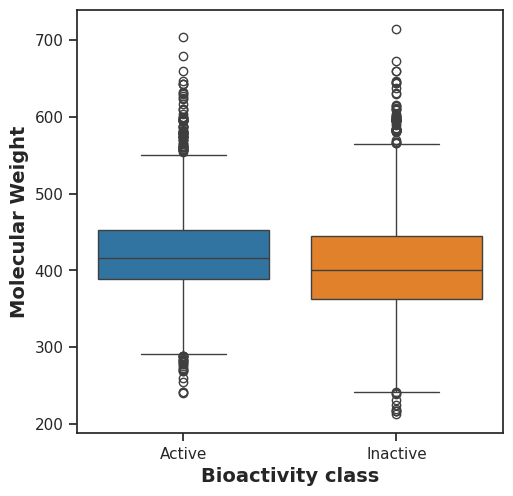

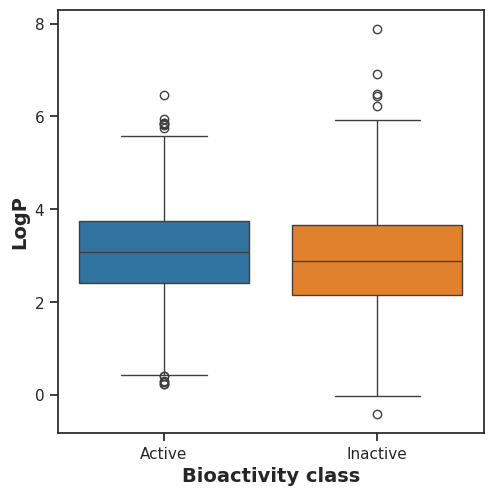

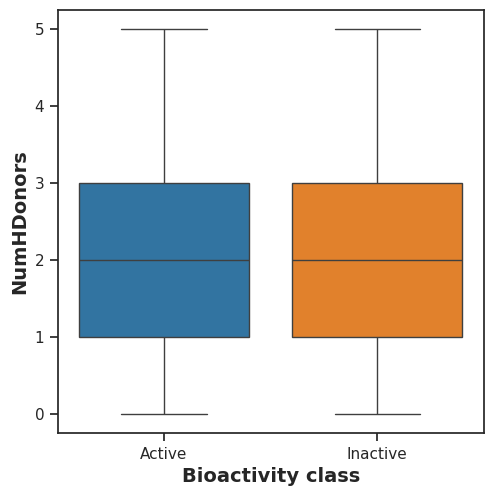

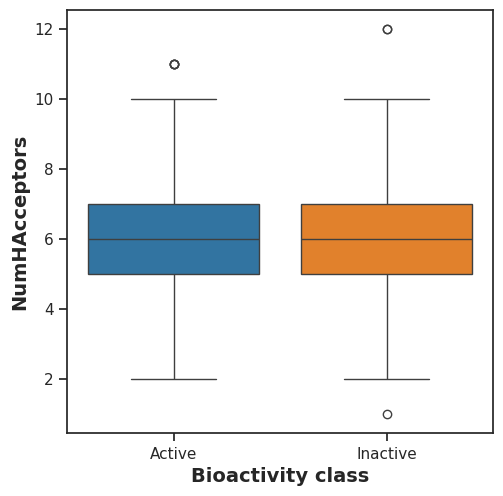

In [57]:
def boxplot_helper(ycol, ylabel, fname):
    plt.figure(figsize=(5.5, 5.5))
    sns.boxplot(x='bioactivity_class', y=ycol, hue='bioactivity_class',
                data=filtered_compounds, palette=['#1f77b4', '#ff7f0e'])
    plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
    plt.ylabel(ylabel, fontsize=14, fontweight='bold')
    plt.savefig(fname)
    plt.show()

boxplot_helper('pIC50', 'pIC50 value', 'box_plot_pic50.png')
boxplot_helper('molecular_weight', 'Molecular Weight', 'plot_MW.png')
boxplot_helper('logp', 'LogP', 'plot_LogP.png')
boxplot_helper('n_hbd', 'NumHDonors', 'plot_NumHDonors.png')
boxplot_helper('n_hba', 'NumHAcceptors', 'plot_NumHAcceptors.png')

In [58]:
# Mann Whitney U Test
def mannwhitney(descriptor, verbose=False):
    from numpy.random import seed
    from scipy.stats import mannwhitneyu
    seed(1)

    selection = [descriptor, 'bioactivity_class']
    df_temp = filtered_compounds[selection]
    active = df_temp[df_temp['bioactivity_class'] == 'Active'][descriptor]
    inactive = df_temp[df_temp['bioactivity_class'] == 'Inactive'][descriptor]

    stat, p = mannwhitneyu(active, inactive)

    alpha = 0.05
    interpretation = ('Same distribution (fail to reject H0)' if p > alpha
                      else 'Different distribution (reject H0)')

    results = pd.DataFrame({'Descriptor': descriptor, 'Statistics': stat,
                            'p': p, 'alpha': alpha,
                            'Interpretation': interpretation}, index=[0])
    results.to_csv('mannwhitneyu_' + descriptor + '.csv')
    return results

for d in ['pIC50', 'molecular_weight', 'logp', 'n_hbd', 'n_hba']:
    print(mannwhitney(d))
    print()

  Descriptor  Statistics    p  alpha                      Interpretation
0      pIC50   2629368.0  0.0   0.05  Different distribution (reject H0)

         Descriptor  Statistics             p  alpha  \
0  molecular_weight   1542937.0  1.154841e-17   0.05   

                       Interpretation  
0  Different distribution (reject H0)  

  Descriptor  Statistics         p  alpha                      Interpretation
0       logp   1443186.0  0.000001   0.05  Different distribution (reject H0)

  Descriptor  Statistics         p  alpha                      Interpretation
0      n_hbd   1396218.5  0.001464   0.05  Different distribution (reject H0)

  Descriptor  Statistics             p  alpha  \
0      n_hba   1545788.0  8.715014e-19   0.05   

                       Interpretation  
0  Different distribution (reject H0)  



MACCS FINGERPRINTS

In [59]:
from rdkit.Chem import MACCSkeys, AllChem, rdFingerprintGenerator
from rdkit.DataStructs import ConvertToNumpyArray
from rdkit import DataStructs

df = pd.read_csv(os.path.join(BASE_DIR,f'ro5_properties_filtered.csv'))
df1 = df[['canonical_smiles']].copy()
PandasTools.AddMoleculeColumnToFrame(df1, 'canonical_smiles', 'mol')
df1.head()

,canonical_smiles,mol
0,NC(=O)c1cnc2[nH]ccc2c1NC1C2CC3CC1CC(O)(C3)C2,<rdkit.Chem.rdchem.Mol object at 0x7be4198c1b60>
1,BrC[C@H]1CC[C@H](c2nnn3cnc4[nH]ccc4c23)CC1,<rdkit.Chem.rdchem.Mol object at 0x7be419342b90>
2,Brc1ccc(CN2CCC(c3nnn4cnc5[nH]ccc5c34)CC2)cc1,<rdkit.Chem.rdchem.Mol object at 0x7be4193428f0>
3,Brc1ccc(CN2CCC(c3nnn4cnc5[nH]ccc5c34)CC2)o1,<rdkit.Chem.rdchem.Mol object at 0x7be419342650>
4,Brc1ccc(CN2CCC(c3nnn4cnc5[nH]ccc5c34)CC2)s1,<rdkit.Chem.rdchem.Mol object at 0x7be4193425e0>


In [60]:
maccs = [MACCSkeys.GenMACCSKeys(x) for x in df1['mol']]
maccs_lists = [list(l) for l in maccs]
maccs_name = [f'MACCS_{i}' for i in range(167)]
maccs_df = pd.DataFrame(maccs_lists, index=df1.index, columns=maccs_name)
print(maccs_df.shape)

MACCS = pd.concat([df1, maccs_df], axis=1)
MACCS.drop(columns=['MACCS_0'], inplace=True)

MACCS_final = pd.concat([df[['pIC50', 'bioactivity_class']],
                         MACCS.drop(columns=['mol'])], axis=1)
MACCS_final.to_csv(os.path.join(BASE_DIR,f'maccs_final.csv'), index=False)

(3246, 167)


MORGAN FINGERPRINTS

In [61]:
radius = 3
nBits = 512
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=nBits)
Morgan = [morgan_gen.GetFingerprint(x) for x in df1['mol']]
morgan_lists = [list(l) for l in Morgan]
morgan_name = [f'morgan_{i}' for i in range(nBits)]
morgan_df = pd.DataFrame(morgan_lists, index=df.index, columns=morgan_name)
print(morgan_df.shape)

MF = pd.concat([df1, morgan_df], axis=1)

MF_final = pd.concat([df[['pIC50', 'bioactivity_class']],
                      MF.drop(columns=['mol'])], axis=1)
MF_final.to_csv(os.path.join(BASE_DIR,f'morgan_3_512.csv'), index=False)

# Inspect first two molecules
morgan_df.to_csv(os.path.join(BASE_DIR,f"morgan_features.csv"), index=False)

(3246, 512)


Tanimoto Similarity Matrix

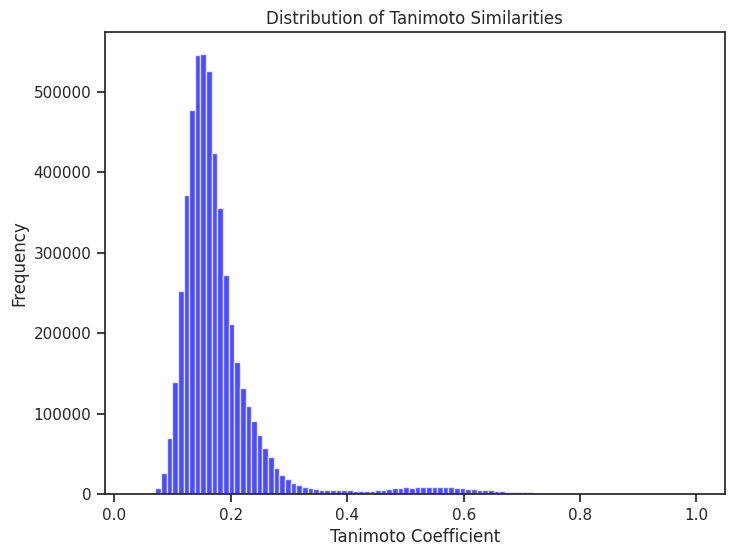

In [62]:
morgan_df = pd.read_csv(os.path.join(BASE_DIR,f"morgan_3_512.csv"))
morgan_features = morgan_df.drop(columns=["canonical_smiles", "pIC50", "bioactivity_class"])

morgan_fps = [DataStructs.CreateFromBitString("".join(map(str, row)))
              for row in morgan_features.values]

# ⚠️ This is O(n²) - 3951² ≈ 15.6M comparisons. On Colab it took ~56s.
tanimoto_matrix = np.array(
    [[DataStructs.TanimotoSimilarity(fp1, fp2) for fp2 in morgan_fps]
     for fp1 in morgan_fps]
)

np.savetxt(os.path.join(BASE_DIR,f"tanimoto_matrix.csv"), tanimoto_matrix, delimiter=",",
           fmt="%.4f",
           header=",".join(map(str, range(len(morgan_fps)))),
           comments="")

tanimoto_values = tanimoto_matrix[np.triu_indices_from(tanimoto_matrix, k=1)]
plt.figure(figsize=(8, 6))
plt.hist(tanimoto_values, bins=100, color="blue", alpha=0.7)
plt.xlabel("Tanimoto Coefficient")
plt.ylabel("Frequency")
plt.title("Distribution of Tanimoto Similarities")
plt.savefig(os.path.join(BASE_DIR,f"tanimoto_histogram.png"))
plt.show()

# MACCS CODE

In [63]:
# %% CELL 1 — Setup paths
import os
from pathlib import Path

          # <-- string, clearly named
WORK_DIR  = output_dir
print(WORK_DIR)


/content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project


In [64]:
import sys
!{sys.executable} -m pip install xgboost lightgbm catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.1 MB/s eta 0:00:00


In [65]:
# CELL 2 — Import all required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import time
import warnings
warnings.filterwarnings("ignore")

# --- Focused model set ---
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# --- Evaluation ---
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     cross_val_score, cross_validate, RandomizedSearchCV,
                                     StratifiedKFold)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             matthews_corrcoef, balanced_accuracy_score,
                             confusion_matrix, roc_curve, auc,
                             precision_recall_curve)
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from scipy.stats import loguniform, uniform

# Reproducibility
RANDOM_STATE = 57
N_JOBS = -1
print("✅ Setup complete. RANDOM_STATE =", RANDOM_STATE)

✅ Setup complete. RANDOM_STATE = 57


In [66]:
# CELL 3 — Load data, split, and build NumPy arrays
df = pd.read_csv(os.path.join(BASE_DIR,f'maccs_final.csv'))

df['Activity'] = df['bioactivity_class'].apply(lambda x: 1 if x == 'Active' else 0)
df1 = df.drop(columns=['pIC50', 'canonical_smiles', 'bioactivity_class'])

X = df1.drop(columns=['Activity'])
y = df1['Activity']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# ---- NumPy conversions (HUGELY faster for tree models and CV) ----
X_train_np = X_train.values.astype(np.float32)
X_test_np  = X_test.values.astype(np.float32)
y_train_np = y_train.values.astype(np.int32)
y_test_np  = y_test.values.astype(np.int32)

print(f"✅ X_train: {X_train_np.shape}  y_train: {y_train_np.shape}")
print(f"✅ X_test : {X_test_np.shape}  y_test : {y_test_np.shape}")
print(f"✅ Class balance (train): {y_train_np.mean():.3f} positive")

✅ X_train: (2596, 166)  y_train: (2596,)
✅ X_test : (650, 166)  y_test : (650,)
✅ Class balance (train): 0.521 positive


New Three Gradient Models

In [67]:
# CELL 4 — Fast CV evaluation (one pass, 15 repeats)
def evaluate_model(model, X_train, y_train):
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)

    scoring = {
        "ROC-AUC":     "roc_auc",
        "F1-score":    "f1",
        "MCC":         "matthews_corrcoef",
        "Accuracy":    "accuracy",
        "Precision":   "precision",
        "Sensitivity": "recall",
    }

    cv_results = cross_validate(
        model, X_train, y_train,
        scoring=scoring, cv=cv,
        n_jobs=N_JOBS, return_train_score=False
    )

    results = {}
    for metric_name in scoring:
        vals = cv_results[f"test_{metric_name}"]
        results[metric_name] = f"{round(np.mean(vals), 3)} ± {round(np.std(vals), 3)}"
    return results

print("✅ evaluate_model defined (fast mode).")

✅ evaluate_model defined (fast mode).


In [68]:
# CELL 5 — Baseline evaluation of the 5 focused models
scale_pos = (y_train_np == 0).sum() / (y_train_np == 1).sum()
print(f"scale_pos_weight = {scale_pos:.3f}\n")

print("Evaluating XGBoost ...")
xgb_results = evaluate_model(
    XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                  subsample=0.8, colsample_bytree=0.8,
                  scale_pos_weight=scale_pos,
                  tree_method='hist',
                  random_state=RANDOM_STATE, n_jobs=N_JOBS,
                  verbosity=0, eval_metric='logloss'),
    X_train_np, y_train_np
)
print("✓ XGBoost:", xgb_results["ROC-AUC"])

print("\nEvaluating LightGBM ...")
lgbm_results = evaluate_model(
    LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                   max_depth=-1, class_weight='balanced',
                   force_col_wise=True,
                   random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1),
    X_train_np, y_train_np
)
print("✓ LightGBM:", lgbm_results["ROC-AUC"])

print("\nEvaluating CatBoost ...")
cat_results = evaluate_model(
    CatBoostClassifier(iterations=300, learning_rate=0.05, depth=6,
                       rsm=0.8, border_count=32,
                       verbose=0, random_state=RANDOM_STATE,
                       thread_count=N_JOBS),
    X_train_np, y_train_np
)
print("✓ CatBoost:", cat_results["ROC-AUC"])

print("\nEvaluating RandomForest ...")
rf_results = evaluate_model(
    RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=N_JOBS),
    X_train_np, y_train_np
)
print("✓ RandomForest:", rf_results["ROC-AUC"])

print("\nEvaluating ExtraTrees ...")
et_results = evaluate_model(
    ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=N_JOBS),
    X_train_np, y_train_np
)
print("✓ ExtraTrees:", et_results["ROC-AUC"])

print("\n✅ All 5 models evaluated.")

scale_pos_weight = 0.919

Evaluating XGBoost ...
✓ XGBoost: 0.839 ± 0.014

Evaluating LightGBM ...
✓ LightGBM: 0.836 ± 0.015

Evaluating CatBoost ...
✓ CatBoost: 0.838 ± 0.014

Evaluating RandomForest ...
✓ RandomForest: 0.827 ± 0.017

Evaluating ExtraTrees ...
✓ ExtraTrees: 0.803 ± 0.019

✅ All 5 models evaluated.


In [69]:
# CELL 6 — Build results table and save
results_df = pd.DataFrame({
    "XGBoost": xgb_results,
    "LightGBM": lgbm_results,
    "CatBoost": cat_results,
    "RandomForestClassifier": rf_results,
    "ExtraTreesClassifier": et_results,
}).T

results_df['Model'] = results_df.index
results_df.to_csv(os.path.join(BASE_DIR,f'performance_maccs_focused.csv'), index=False)
print("✅ Saved performance_maccs_focused.csv")
display(results_df)

✅ Saved performance_maccs_focused.csv


,ROC-AUC,F1-score,MCC,Accuracy,Precision,Sensitivity,Model
XGBoost,0.839 ± 0.014,0.767 ± 0.016,0.514 ± 0.032,0.757 ± 0.016,0.769 ± 0.02,0.765 ± 0.025,XGBoost
LightGBM,0.836 ± 0.015,0.762 ± 0.018,0.504 ± 0.037,0.752 ± 0.019,0.764 ± 0.022,0.761 ± 0.024,LightGBM
CatBoost,0.838 ± 0.014,0.771 ± 0.015,0.516 ± 0.032,0.758 ± 0.016,0.761 ± 0.019,0.782 ± 0.024,CatBoost
RandomForestClassifier,0.827 ± 0.017,0.768 ± 0.018,0.509 ± 0.037,0.755 ± 0.019,0.758 ± 0.021,0.779 ± 0.024,RandomForestClassifier
ExtraTreesClassifier,0.803 ± 0.019,0.761 ± 0.02,0.5 ± 0.041,0.751 ± 0.02,0.759 ± 0.022,0.764 ± 0.027,ExtraTreesClassifier


In [70]:
# CELL 7 — Rank by overall score
def extract_mean(value):
    return float(str(value).split("±")[0].strip())

metrics = ["ROC-AUC", "F1-score", "MCC", "Accuracy", "Precision", "Sensitivity"]
for metric in metrics:
    results_df[f"{metric}_mean"] = results_df[metric].apply(extract_mean)

results_df["Overall_Score"] = (
    results_df["ROC-AUC_mean"] + results_df["F1-score_mean"] +
    results_df["MCC_mean"] + results_df["Accuracy_mean"] +
    results_df["Precision_mean"] + results_df["Sensitivity_mean"]
) / 6

results_df = results_df.sort_values(by="Overall_Score", ascending=False).reset_index(drop=True)

display(results_df[["Model","ROC-AUC_mean","F1-score_mean","MCC_mean",
                    "Accuracy_mean","Precision_mean","Sensitivity_mean",
                    "Overall_Score"]])

TOP_N = 5
top5_df = results_df.head(TOP_N).copy()
top5_models = top5_df["Model"].tolist()
print("\n🏆 Top models:")
for i, m in enumerate(top5_models, 1):
    print(f"  {i}. {m}  (Overall Score = {top5_df.iloc[i-1]['Overall_Score']:.4f})")

,Model,ROC-AUC_mean,F1-score_mean,MCC_mean,Accuracy_mean,Precision_mean,Sensitivity_mean,Overall_Score
0,CatBoost,0.838,0.771,0.516,0.758,0.761,0.782,0.737667
1,XGBoost,0.839,0.767,0.514,0.757,0.769,0.765,0.735167
2,RandomForestClassifier,0.827,0.768,0.509,0.755,0.758,0.779,0.732667
3,LightGBM,0.836,0.762,0.504,0.752,0.764,0.761,0.729833
4,ExtraTreesClassifier,0.803,0.761,0.500,0.751,0.759,0.764,0.723000



🏆 Top models:
  1. CatBoost  (Overall Score = 0.7377)
  2. XGBoost  (Overall Score = 0.7352)
  3. RandomForestClassifier  (Overall Score = 0.7327)
  4. LightGBM  (Overall Score = 0.7298)
  5. ExtraTreesClassifier  (Overall Score = 0.7230)


MODEL FACTORIES

In [71]:
# CELL 8 — Model factories (fast defaults)
RANDOM_STATE = 57
N_JOBS = -1
scale_pos = (y_train_np == 0).sum() / (y_train_np == 1).sum()

MODEL_FACTORIES = {
    "XGBoost": lambda: XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=scale_pos,
        tree_method='hist',
        random_state=RANDOM_STATE, n_jobs=N_JOBS,
        verbosity=0, eval_metric='logloss'
    ),
    "LightGBM": lambda: LGBMClassifier(
        n_estimators=300, learning_rate=0.05, num_leaves=31,
        class_weight='balanced', force_col_wise=True,
        random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1
    ),
    "CatBoost": lambda: CatBoostClassifier(
        iterations=300, learning_rate=0.05, depth=6,
        rsm=0.8, border_count=32,
        verbose=0, random_state=RANDOM_STATE, thread_count=N_JOBS
    ),
    "RandomForestClassifier": lambda: RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=N_JOBS
    ),
    "ExtraTreesClassifier": lambda: ExtraTreesClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=N_JOBS
    ),
}
print("✅ MODEL_FACTORIES defined for", len(MODEL_FACTORIES), "models.")

✅ MODEL_FACTORIES defined for 5 models.


HYPERPARAMETER SEARCH SPACES

In [72]:
# CELL 9 — Slim search spaces (fast tuning, minimal quality loss)
all_param_distributions = {

    "XGBoost": {
        "n_estimators":     [200, 300, 500],
        "learning_rate":    [0.03, 0.05, 0.1],
        "max_depth":        [4, 6, 8],
        "subsample":        [0.7, 0.8, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "min_child_weight": [1, 3, 5],
        "reg_lambda":       [0.1, 1, 5],
    },

    "LightGBM": {
        "n_estimators":      [200, 300, 500],
        "learning_rate":     [0.03, 0.05, 0.1],
        "num_leaves":        [15, 31, 63],
        "max_depth":         [-1, 5, 10],
        "min_child_samples": [10, 20, 40],
        "subsample":         [0.7, 0.8, 1.0],
        "reg_lambda":        [0, 1, 5],
    },

    "CatBoost": {
        "iterations":    [150, 300],
        "learning_rate": [0.03, 0.05, 0.1],
        "depth":         [4, 6, 8],
        "l2_leaf_reg":   [1, 3, 5],
        "border_count":  [32, 64],
    },

    "RandomForestClassifier": {
        "n_estimators":      [200, 400, 600],
        "max_depth":         [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf":  [1, 2, 4],
        "max_features":      ["sqrt", 0.3, 0.5],
        "class_weight":      [None, "balanced"],
    },

    "ExtraTreesClassifier": {
        "n_estimators":      [200, 400, 600],
        "max_depth":         [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf":  [1, 2, 4],
        "max_features":      ["sqrt", 0.3, 0.5],
        "class_weight":      [None, "balanced"],
    },
}
print("✅ Search spaces ready for", len(all_param_distributions), "models.")

✅ Search spaces ready for 5 models.


In [73]:
# CELL 10 — Verify all models have factories and search spaces
print("=" * 80)
print("VERIFYING HYPERPARAMETER SETUP")
print("=" * 80)

for model_name in top5_models:
    assert model_name in MODEL_FACTORIES, f"❌ Missing factory: {model_name}"
    assert model_name in all_param_distributions, f"❌ Missing params: {model_name}"
    print(f"✅ {model_name}")

print("\n✅ All models verified.")

VERIFYING HYPERPARAMETER SETUP
✅ CatBoost
✅ XGBoost
✅ RandomForestClassifier
✅ LightGBM
✅ ExtraTreesClassifier

✅ All models verified.


HYPERPARAMETER TUNING

In [74]:
# CELL 11 — Tuning Part 1 (first 3 models)
cv_tuning = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
N_ITER_SEARCH = 15

tuned_models = {}
tuning_results = []

for rank, model_name in enumerate(top5_models[:3], 1):
    print("\n" + "=" * 80)
    print(f"TUNING {rank}/5: {model_name}")
    print("=" * 80)

    model = MODEL_FACTORIES[model_name]()
    param_space = all_param_distributions[model_name]

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_space,
        n_iter=N_ITER_SEARCH,
        scoring="roc_auc",
        cv=cv_tuning,
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
        refit=True,
        verbose=1,
        error_score='raise'
    )

    t0 = time.time()
    search.fit(X_train_np, y_train_np)          # ← NumPy!
    dt = time.time() - t0

    tuned_models[model_name] = search.best_estimator_
    tuning_results.append({
        "Rank_Baseline": rank,
        "Model": model_name,
        "Best_CV_ROC_AUC": search.best_score_,
        "Best_Params": search.best_params_
    })

    print(f"\n✅ {model_name} done in {dt/60:.2f} min")
    print(f"   Best CV ROC-AUC: {search.best_score_:.4f}")

print("\n✅ Part 1 tuning done.")


TUNING 1/5: CatBoost
Fitting 5 folds for each of 15 candidates, totalling 75 fits

✅ CatBoost done in 4.51 min
   Best CV ROC-AUC: 0.8446

TUNING 2/5: XGBoost
Fitting 5 folds for each of 15 candidates, totalling 75 fits

✅ XGBoost done in 0.77 min
   Best CV ROC-AUC: 0.8420

TUNING 3/5: RandomForestClassifier
Fitting 5 folds for each of 15 candidates, totalling 75 fits

✅ RandomForestClassifier done in 5.05 min
   Best CV ROC-AUC: 0.8419

✅ Part 1 tuning done.


In [75]:
# CELL 12 — Tuning Part 2 (last 2 models)
for rank, model_name in enumerate(top5_models[3:], 4):
    print("\n" + "=" * 80)
    print(f"TUNING {rank}/5: {model_name}")
    print("=" * 80)

    model = MODEL_FACTORIES[model_name]()
    param_space = all_param_distributions[model_name]

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_space,
        n_iter=N_ITER_SEARCH,
        scoring="roc_auc",
        cv=cv_tuning,
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
        refit=True,
        verbose=1,
        error_score='raise'
    )

    t0 = time.time()
    search.fit(X_train_np, y_train_np)          # ← NumPy!
    dt = time.time() - t0

    tuned_models[model_name] = search.best_estimator_
    tuning_results.append({
        "Rank_Baseline": rank,
        "Model": model_name,
        "Best_CV_ROC_AUC": search.best_score_,
        "Best_Params": search.best_params_
    })

    print(f"\n✅ {model_name} done in {dt/60:.2f} min")
    print(f"   Best CV ROC-AUC: {search.best_score_:.4f}")

print("\n🎉 All 5 models tuned.")


TUNING 4/5: LightGBM
Fitting 5 folds for each of 15 candidates, totalling 75 fits

✅ LightGBM done in 2.23 min
   Best CV ROC-AUC: 0.8364

TUNING 5/5: ExtraTreesClassifier
Fitting 5 folds for each of 15 candidates, totalling 75 fits

✅ ExtraTreesClassifier done in 5.94 min
   Best CV ROC-AUC: 0.8432

🎉 All 5 models tuned.


In [76]:
# CELL 13 — Save tuning results and tuned models
maccs_tuning_df = pd.DataFrame(tuning_results).sort_values(
    by="Best_CV_ROC_AUC", ascending=False
).reset_index(drop=True)

display(maccs_tuning_df[["Model", "Best_CV_ROC_AUC"]])

MODEL_SAVE_DIR = os.path.join(WORK_DIR, "maccs_hyperparameter_tuning")
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

maccs_tuning_df.to_csv(
    os.path.join(MODEL_SAVE_DIR, "maccs_hyperparameter_tuning_results.csv"),
    index=False
)

for model_name, model in tuned_models.items():
    fn = os.path.join(MODEL_SAVE_DIR, f"{model_name}_tuned.joblib")
    joblib.dump(model, fn)
    print(f"💾 Saved: {fn}")

,Model,Best_CV_ROC_AUC
0,CatBoost,0.844626
1,ExtraTreesClassifier,0.843229
2,XGBoost,0.841965
3,RandomForestClassifier,0.841871
4,LightGBM,0.836431


💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/maccs_hyperparameter_tuning/CatBoost_tuned.joblib
💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/maccs_hyperparameter_tuning/XGBoost_tuned.joblib
💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/maccs_hyperparameter_tuning/RandomForestClassifier_tuned.joblib
💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/maccs_hyperparameter_tuning/LightGBM_tuned.joblib
💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/maccs_hyperparameter_tuning/ExtraTreesClassifier_tuned.joblib


In [77]:
# CELL 13 — Save tuning results and tuned models
maccs_tuning_df = pd.DataFrame(tuning_results).sort_values(
    by="Best_CV_ROC_AUC", ascending=False
).reset_index(drop=True)

display(maccs_tuning_df[["Model", "Best_CV_ROC_AUC"]])

MODEL_SAVE_DIR = os.path.join(WORK_DIR, "maccs_hyperparameter_tuning")
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

maccs_tuning_df.to_csv(
    os.path.join(MODEL_SAVE_DIR, "maccs_hyperparameter_tuning_results.csv"),
    index=False
)

for model_name, model in tuned_models.items():
    fn = os.path.join(MODEL_SAVE_DIR, f"{model_name}_tuned.joblib")
    joblib.dump(model, fn)
    print(f"💾 Saved: {fn}")

,Model,Best_CV_ROC_AUC
0,CatBoost,0.844626
1,ExtraTreesClassifier,0.843229
2,XGBoost,0.841965
3,RandomForestClassifier,0.841871
4,LightGBM,0.836431


💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/maccs_hyperparameter_tuning/CatBoost_tuned.joblib
💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/maccs_hyperparameter_tuning/XGBoost_tuned.joblib
💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/maccs_hyperparameter_tuning/RandomForestClassifier_tuned.joblib
💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/maccs_hyperparameter_tuning/LightGBM_tuned.joblib
💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/maccs_hyperparameter_tuning/ExtraTreesClassifier_tuned.joblib


In [78]:
# CELL 14 — Select the best individual tuned model
FINAL_FOLDER_MACCS = os.path.join(WORK_DIR, "grand_final_selection")
os.makedirs(FINAL_FOLDER_MACCS, exist_ok=True)

TUNING_RESULTS_FILE = os.path.join(MODEL_SAVE_DIR, "maccs_hyperparameter_tuning_results.csv")

tuning_df = (pd.read_csv(TUNING_RESULTS_FILE)
             .sort_values(by="Best_CV_ROC_AUC", ascending=False)
             .reset_index(drop=True))

best_model_name = tuning_df.iloc[0]["Model"]
best_model_auc  = float(tuning_df.iloc[0]["Best_CV_ROC_AUC"])

print("🏆 Final model selection (best individual, no ensemble):")
print(tuning_df[["Model", "Best_CV_ROC_AUC"]].to_string(index=False))
print(f"\n✅ Selected: {best_model_name}  (CV ROC-AUC = {best_model_auc:.4f})")

# Load the tuned model from disk
FINAL_MODEL_FILE_MACCS = os.path.join(MODEL_SAVE_DIR, f"{best_model_name}_tuned.joblib")
final_model = joblib.load(FINAL_MODEL_FILE_MACCS)
print(f"   Model type: {type(final_model).__name__}")

# Save the final model into the final folder
final_model_output = os.path.join(FINAL_FOLDER_MACCS, "final_maccs_model.joblib")
joblib.dump(final_model, final_model_output)
print(f"💾 Saved: {final_model_output}")

# Save final selection summary
pd.DataFrame({
    "Fingerprint": ["MACCS"],
    "Final_Model_Type": ["Best Individual Tuned Model"],
    "Final_Model": [best_model_name],
    "Final_CV_ROC_AUC": [best_model_auc],
    "Test_Set_Used_For_Selection": [False]
}).to_csv(os.path.join(FINAL_FOLDER_MACCS, "maccs_final_model_selection.csv"), index=False)

print("\n✅ Final model selection complete.")

🏆 Final model selection (best individual, no ensemble):
                 Model  Best_CV_ROC_AUC
              CatBoost         0.844626
  ExtraTreesClassifier         0.843229
               XGBoost         0.841965
RandomForestClassifier         0.841871
              LightGBM         0.836431

✅ Selected: CatBoost  (CV ROC-AUC = 0.8446)
   Model type: CatBoostClassifier
💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/grand_final_selection/final_maccs_model.joblib

✅ Final model selection complete.


In [79]:
# CELL 15 — Final test-set evaluation (test set used ONCE)
FINAL_MODEL_FILE_MACCS = os.path.join(FINAL_FOLDER_MACCS, "final_maccs_model.joblib")
final_model = joblib.load(FINAL_MODEL_FILE_MACCS)
print("Loaded final model:", type(final_model).__name__)

y_pred = final_model.predict(X_test_np)

if hasattr(final_model, "predict_proba"):
    proba = final_model.predict_proba(X_test_np)
    classes = list(final_model.classes_)
    pos_idx = classes.index(1) if 1 in classes else 1
    y_prob = proba[:, pos_idx]
else:
    scores = final_model.decision_function(X_test_np)
    y_prob = 1 / (1 + np.exp(-scores))

roc_auc = roc_auc_score(y_test_np, y_prob)
pr_auc  = average_precision_score(y_test_np, y_prob)
acc     = accuracy_score(y_test_np, y_pred)
bal_acc = balanced_accuracy_score(y_test_np, y_pred)
prec    = precision_score(y_test_np, y_pred, zero_division=0)
sens    = recall_score(y_test_np, y_pred, zero_division=0)
f1      = f1_score(y_test_np, y_pred, zero_division=0)
mcc     = matthews_corrcoef(y_test_np, y_pred)
tn, fp, fn, tp = confusion_matrix(y_test_np, y_pred, labels=[0, 1]).ravel()
spec = tn / (tn + fp) if (tn + fp) else 0

print("\n" + "=" * 60)
print("FINAL MACCS MODEL — TEST-SET PERFORMANCE")
print("=" * 60)
print(f"ROC-AUC              : {roc_auc:.4f}")
print(f"PR-AUC               : {pr_auc:.4f}")
print(f"Accuracy             : {acc:.4f}")
print(f"Balanced Accuracy    : {bal_acc:.4f}")
print(f"Precision            : {prec:.4f}")
print(f"Sensitivity (Recall) : {sens:.4f}")
print(f"Specificity          : {spec:.4f}")
print(f"F1-score             : {f1:.4f}")
print(f"MCC                  : {mcc:.4f}")
print(f"\nTN={tn}  FP={fp}  FN={fn}  TP={tp}")

pd.DataFrame({
    "Model": ["Final MACCS Model"],
    "Model_Type": [type(final_model).__name__],
    "ROC_AUC": [roc_auc], "PR_AUC": [pr_auc],
    "Accuracy": [acc], "Balanced_Accuracy": [bal_acc],
    "Precision": [prec], "Sensitivity": [sens],
    "Specificity": [spec], "MCC": [mcc], "F1_Score": [f1],
    "TN": [tn], "FP": [fp], "FN": [fn], "TP": [tp],
    "Test_Samples": [len(X_test_np)]
}).to_csv(os.path.join(FINAL_FOLDER_MACCS, "final_maccs_test_metrics.csv"), index=False)

print(f"\n💾 Saved: {FINAL_FOLDER_MACCS}/final_maccs_test_metrics.csv")

Loaded final model: CatBoostClassifier

FINAL MACCS MODEL — TEST-SET PERFORMANCE
ROC-AUC              : 0.8464
PR-AUC               : 0.8418
Accuracy             : 0.7538
Balanced Accuracy    : 0.7522
Precision            : 0.7507
Sensitivity (Recall) : 0.7906
Specificity          : 0.7138
F1-score             : 0.7701
MCC                  : 0.5064

TN=222  FP=89  FN=71  TP=268

💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/grand_final_selection/final_maccs_test_metrics.csv


Confusion Matrix

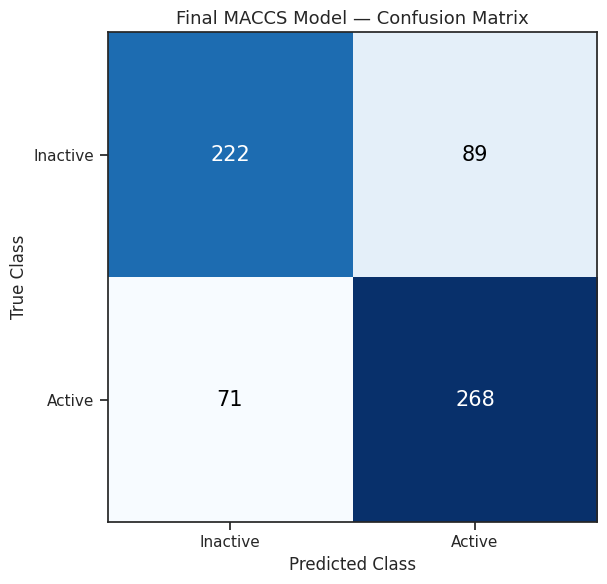

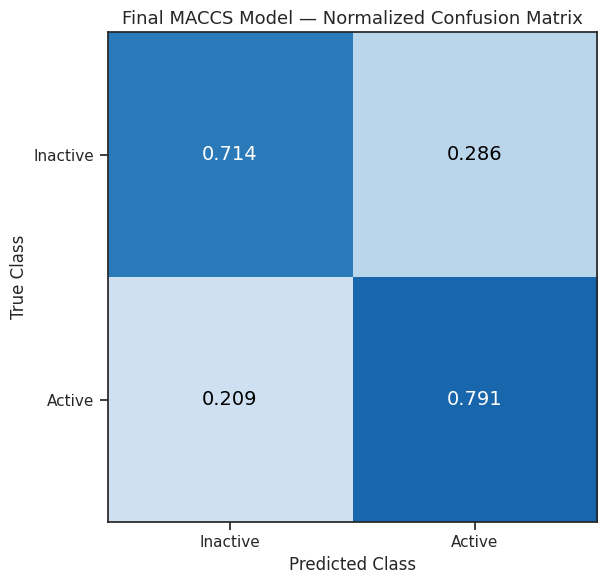

💾 Confusion matrix figures saved.


In [80]:
# CELL 16 — Confusion matrix (numbered + normalized)
cm = np.array([[tn, fp], [fn, tp]])

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm, cmap="Blues")
ax.set_title("Final MACCS Model — Confusion Matrix", fontsize=13)
ax.set_xlabel("Predicted Class"); ax.set_ylabel("True Class")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Inactive", "Active"])
ax.set_yticklabels(["Inactive", "Active"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                fontsize=15, color="white" if cm[i, j] > cm.max()/2 else "black")
plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MACCS, "final_maccs_confusion_matrix_numbered.png"),
            dpi=300, bbox_inches="tight")
plt.show()

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_title("Final MACCS Model — Normalized Confusion Matrix", fontsize=13)
ax.set_xlabel("Predicted Class"); ax.set_ylabel("True Class")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Inactive", "Active"])
ax.set_yticklabels(["Inactive", "Active"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm_norm[i, j]:.3f}", ha="center", va="center",
                fontsize=14, color="white" if cm_norm[i, j] > 0.5 else "black")
plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MACCS, "final_maccs_normalized_confusion_matrix.png"),
            dpi=300, bbox_inches="tight")
plt.show()
print("💾 Confusion matrix figures saved.")

ROC_AUC & Precision Recall Curves

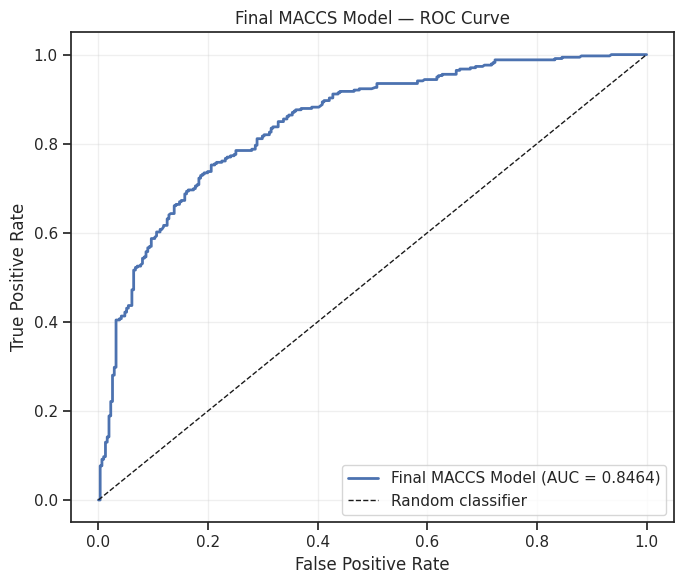

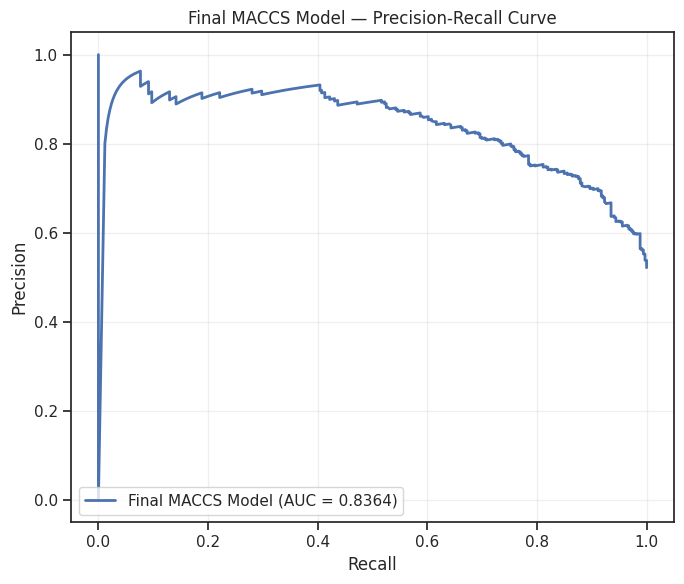

💾 ROC and PR curves saved.


In [81]:
# CELL 17 — ROC and Precision-Recall curves
fpr, tpr, _ = roc_curve(y_test_np, y_prob)
roc_auc_curve = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, lw=2, label=f"Final MACCS Model (AUC = {roc_auc_curve:.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random classifier")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Final MACCS Model — ROC Curve")
plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MACCS, "final_maccs_roc_curve.png"), dpi=300, bbox_inches="tight")
plt.show()

precision_vals, recall_vals, _ = precision_recall_curve(y_test_np, y_prob)
pr_auc_curve = auc(recall_vals, precision_vals)

plt.figure(figsize=(7, 6))
plt.plot(recall_vals, precision_vals, lw=2, label=f"Final MACCS Model (AUC = {pr_auc_curve:.4f})")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Final MACCS Model — Precision-Recall Curve")
plt.legend(loc="lower left"); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MACCS, "final_maccs_precision_recall_curve.png"),
            dpi=300, bbox_inches="tight")
plt.show()
print("💾 ROC and PR curves saved.")

Y scambling

Scramble model: CatBoostClassifier

Computing true-label CV ROC-AUC ...
  ✅ True-label CV ROC-AUC: 0.8446 ± 0.0097 (61.4s)

  5/30 | mean = 0.4979 | 265s
  10/30 | mean = 0.4962 | 528s
  15/30 | mean = 0.4962 | 791s
  20/30 | mean = 0.4999 | 1076s
  25/30 | mean = 0.5011 | 1382s
  30/30 | mean = 0.5017 | 1653s

             Parameter     Value
       True_CV_ROC_AUC  0.844626
    True_CV_ROC_AUC_SD  0.009672
Scrambled_Mean_ROC_AUC  0.501657
  Scrambled_SD_ROC_AUC  0.013281
  Y_Scrambling_Z_Score 25.824793
     Empirical_P_Value  0.000000
   Number_of_Scrambles 30.000000
              CV_Folds  5.000000


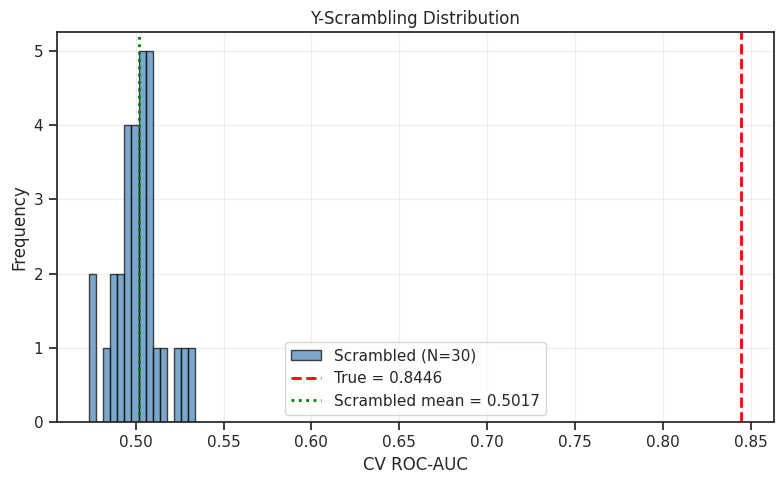


💾 Y-scrambling results and figure saved.


In [85]:
# CELL 18 — Y-scrambling (fast, train set only)
# NOTE: since final_model is a single model (not an ensemble),
# each scramble is ~1.5-3 s.
import time

N_SCRAMBLES = 30
CV_FOLDS = 5
scramble_cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True,
                              random_state=RANDOM_STATE)

# Force single-threaded to avoid contention
scramble_model = clone(final_model)
try:
    scramble_model.set_params()
except ValueError:
    pass
if hasattr(scramble_model, "thread_count"):
    scramble_model.set_params(thread_count=1)

print("Scramble model:", type(scramble_model).__name__)

# Reference: true-label CV ROC-AUC on the same model
print("\nComputing true-label CV ROC-AUC ...")
t0 = time.time()
true_scores = cross_val_score(scramble_model, X_train_np, y_train_np,
                              cv=scramble_cv, scoring="roc_auc", n_jobs=-1)
true_mean, true_std = true_scores.mean(), true_scores.std()
print(f"  ✅ True-label CV ROC-AUC: {true_mean:.4f} ± {true_std:.4f} "
      f"({time.time()-t0:.1f}s)\n")

# Scrambled loop
scrambled_scores = []
rng = np.random.RandomState(RANDOM_STATE)
t0 = time.time()

for i in range(N_SCRAMBLES):
    y_perm = rng.permutation(y_train_np)
    s = cross_val_score(scramble_model, X_train_np, y_perm,
                        cv=scramble_cv, scoring="roc_auc", n_jobs=-1)
    scrambled_scores.append(s.mean())
    if (i + 1) % 5 == 0:
        print(f"  {i+1}/{N_SCRAMBLES} | mean = {np.mean(scrambled_scores):.4f} "
              f"| {time.time()-t0:.0f}s")

scrambled_scores = np.array(scrambled_scores)
scram_mean, scram_std = scrambled_scores.mean(), scrambled_scores.std()
z_score = (true_mean - scram_mean) / scram_std
emp_p = (scrambled_scores >= true_mean).mean()

# Summary table
summary = pd.DataFrame({
    "Parameter": ["True_CV_ROC_AUC", "True_CV_ROC_AUC_SD",
                  "Scrambled_Mean_ROC_AUC", "Scrambled_SD_ROC_AUC",
                  "Y_Scrambling_Z_Score", "Empirical_P_Value",
                  "Number_of_Scrambles", "CV_Folds"],
    "Value": [true_mean, true_std, scram_mean, scram_std,
              z_score, emp_p, N_SCRAMBLES, CV_FOLDS]
})

pd.DataFrame({"Scrambled_CV_ROC_AUC": scrambled_scores}).to_csv(
    os.path.join(FINAL_FOLDER_MACCS, "final_maccs_y_scrambling_results.csv"), index=False)
summary.to_csv(os.path.join(FINAL_FOLDER_MACCS, "final_maccs_y_scrambling_summary.csv"), index=False)
print("\n" + summary.to_string(index=False))

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(scrambled_scores, bins=15, color="steelblue", alpha=0.7,
        edgecolor="black", label=f"Scrambled (N={N_SCRAMBLES})")
ax.axvline(true_mean, color="red", linestyle="--", lw=2,
           label="True = {:.4f}".format(true_mean))
ax.axvline(scram_mean, color="green", linestyle=":", lw=2,
           label="Scrambled mean = {:.4f}".format(scram_mean))
ax.set_xlabel("CV ROC-AUC"); ax.set_ylabel("Frequency")
ax.set_title("Y-Scrambling Distribution")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MACCS, "final_maccs_y_scrambling_distribution.png"),
            dpi=300, bbox_inches="tight")
plt.show()

print("\n💾 Y-scrambling results and figure saved.")

Prediction Probability Distribution

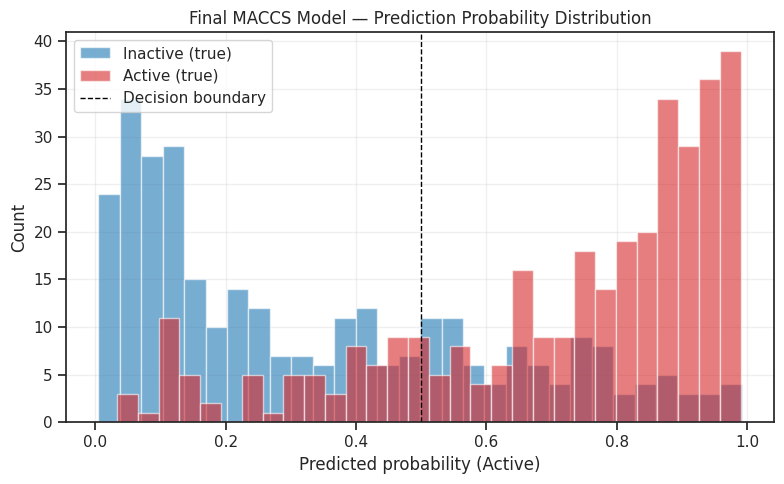

💾 Probability distribution figure saved.


In [86]:
# CELL 19 — Prediction probability distribution by true class
plt.figure(figsize=(8, 5))
plt.hist(y_prob[y_test_np == 0], bins=30, alpha=0.6,
         label="Inactive (true)", color="tab:blue")
plt.hist(y_prob[y_test_np == 1], bins=30, alpha=0.6,
         label="Active (true)", color="tab:red")
plt.axvline(0.5, color="black", linestyle="--", lw=1, label="Decision boundary")
plt.xlabel("Predicted probability (Active)")
plt.ylabel("Count")
plt.title("Final MACCS Model — Prediction Probability Distribution")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MACCS,
                        "final_maccs_prediction_probability_distribution.png"),
            dpi=300, bbox_inches="tight")
plt.show()
print("💾 Probability distribution figure saved.")

Calibration Curve

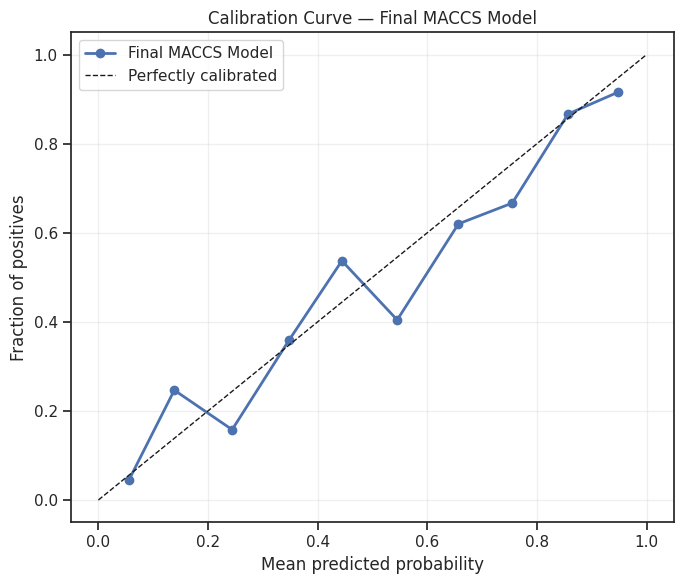

💾 Calibration curve saved.


In [87]:
# CELL 20 — Calibration curve
prob_true, prob_pred = calibration_curve(y_test_np, y_prob, n_bins=10,
                                         strategy="uniform")

plt.figure(figsize=(7, 6))
plt.plot(prob_pred, prob_true, marker="o", lw=2, label="Final MACCS Model")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Perfectly calibrated")
plt.xlabel("Mean predicted probability"); plt.ylabel("Fraction of positives")
plt.title("Calibration Curve — Final MACCS Model")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MACCS, "final_maccs_calibration_curve.png"),
            dpi=300, bbox_inches="tight")
plt.show()
print("💾 Calibration curve saved.")

Cumulative Gain Curve

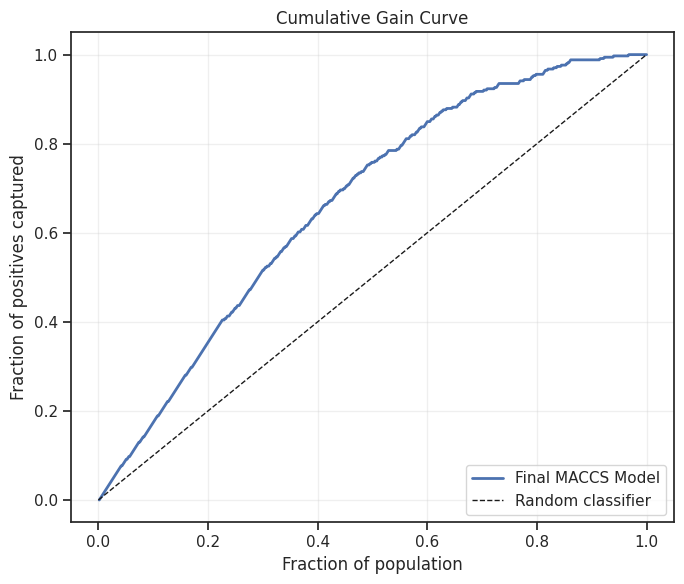

💾 Cumulative gain curve saved.


In [88]:
# CELL 21 — Cumulative gain curve
order = np.argsort(-y_prob)
y_sorted = y_test_np[order]
cum_positives = np.cumsum(y_sorted)
total_positives = y_sorted.sum()
fraction_population = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
fraction_positives = cum_positives / total_positives

plt.figure(figsize=(7, 6))
plt.plot(fraction_population, fraction_positives, lw=2, label="Final MACCS Model")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random classifier")
plt.xlabel("Fraction of population"); plt.ylabel("Fraction of positives captured")
plt.title("Cumulative Gain Curve")
plt.legend(loc="lower right"); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MACCS, "final_maccs_cumulative_gain.png"),
            dpi=300, bbox_inches="tight")
plt.show()
print("💾 Cumulative gain curve saved.")

Metric Summary Figure

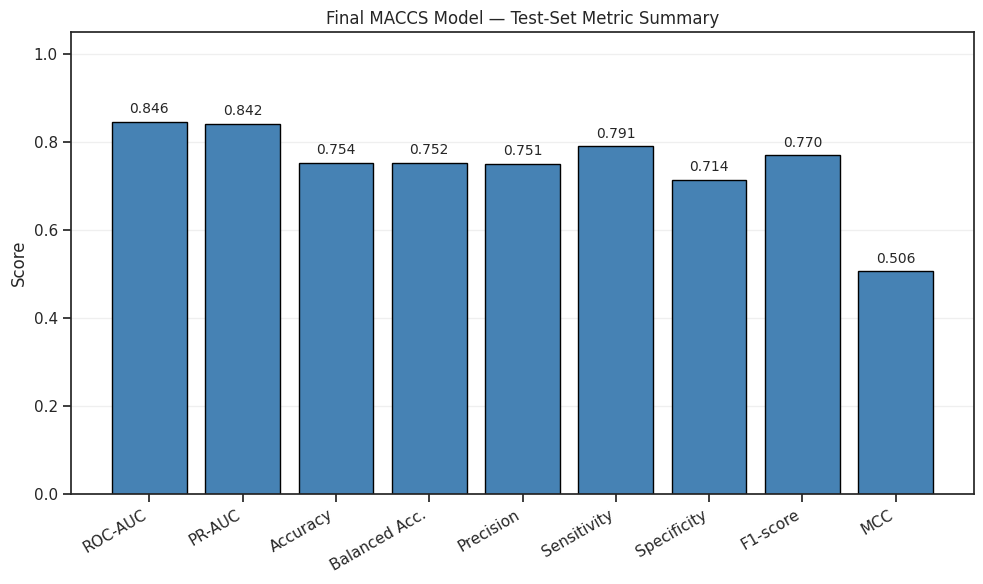

💾 Metric summary figure saved.


In [89]:
# CELL 22 — Metric summary bar chart
metric_names = ["ROC-AUC", "PR-AUC", "Accuracy", "Balanced Acc.",
                "Precision", "Sensitivity", "Specificity", "F1-score", "MCC"]
metric_values = [roc_auc, pr_auc, acc, bal_acc, prec, sens, spec, f1, mcc]

plt.figure(figsize=(10, 6))
bars = plt.bar(metric_names, metric_values, color="steelblue", edgecolor="black")
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Final MACCS Model — Test-Set Metric Summary")
plt.xticks(rotation=30, ha="right")
for bar, val in zip(bars, metric_values):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.3f}",
             ha="center", fontsize=10)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MACCS, "final_maccs_metric_summary.png"),
            dpi=300, bbox_inches="tight")
plt.show()
print("💾 Metric summary figure saved.")

Master Publication Figure

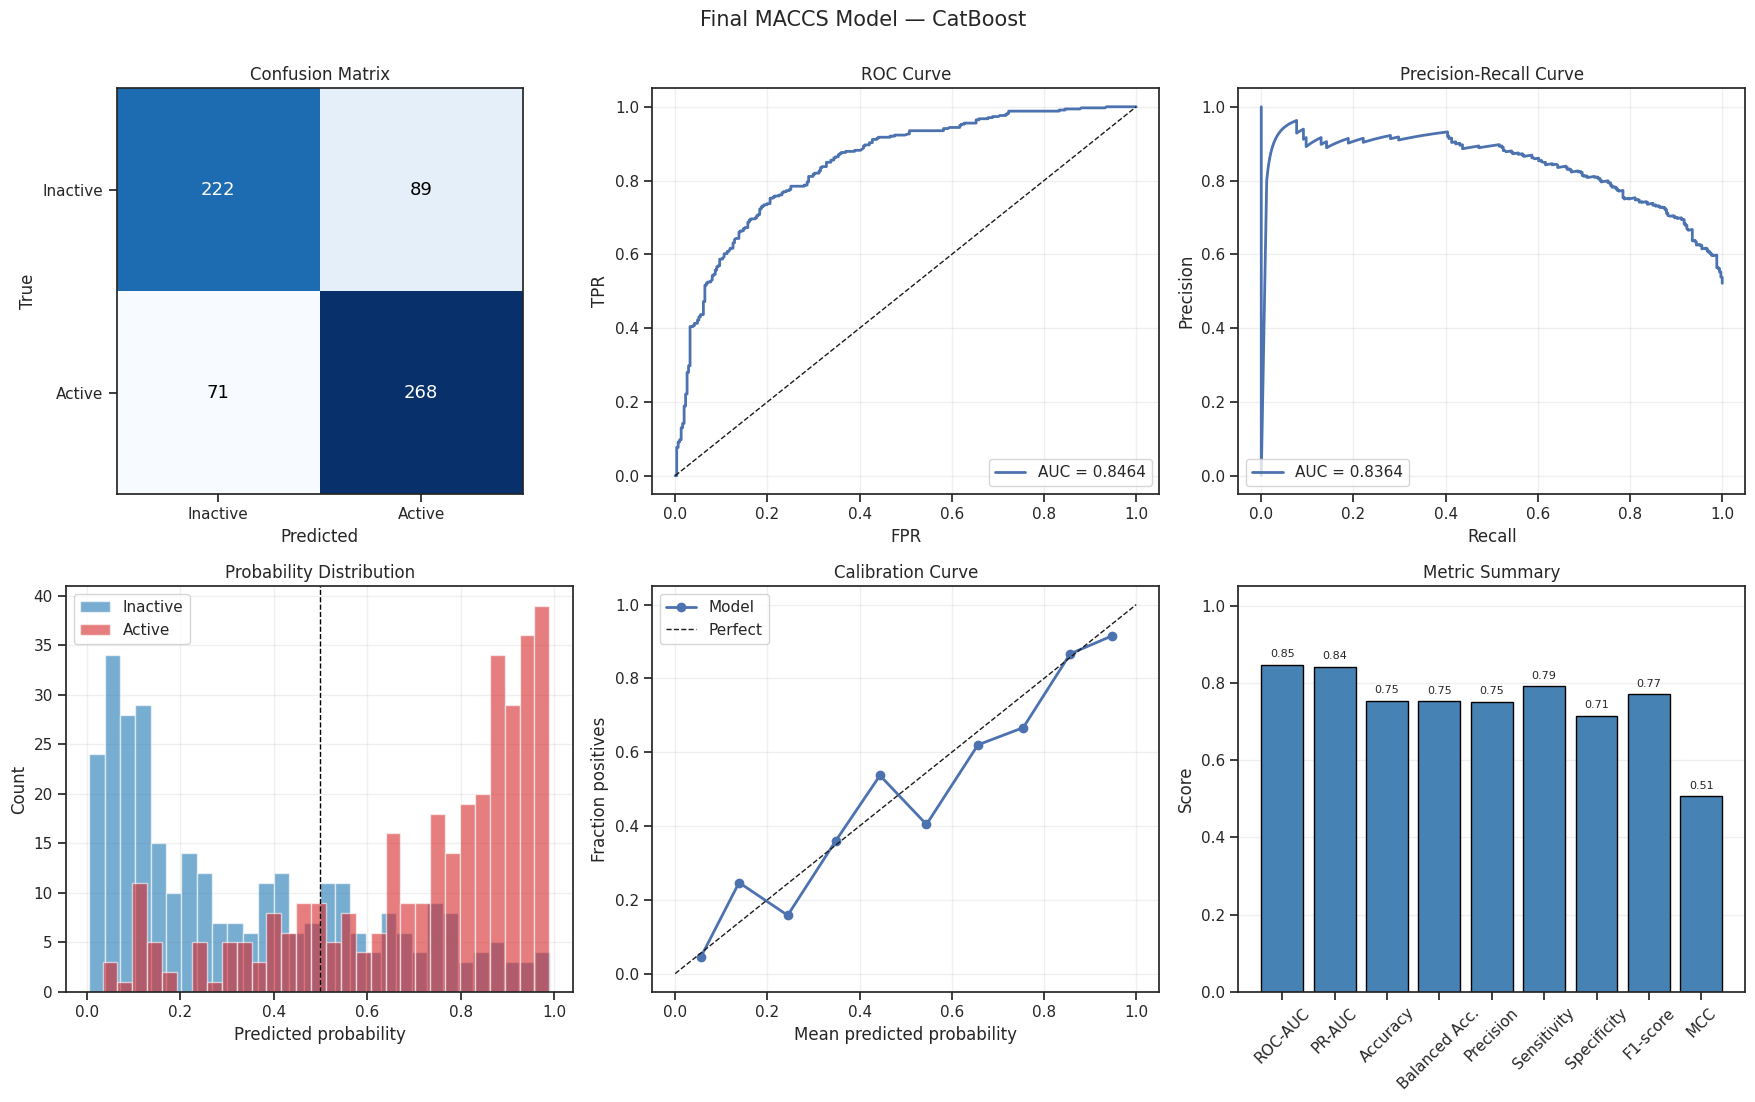

💾 Master publication figure saved.


In [90]:
# CELL 23 — Master publication figure (6 panels)
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# (1) Confusion matrix
ax = axes[0, 0]
ax.imshow(cm, cmap="Blues")
ax.set_title("Confusion Matrix")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Inactive", "Active"])
ax.set_yticklabels(["Inactive", "Active"])
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                color="white" if cm[i, j] > cm.max()/2 else "black")

# (2) ROC curve
ax = axes[0, 1]
ax.plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_curve:.4f}")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
ax.set_title("ROC Curve"); ax.legend(loc="lower right"); ax.grid(alpha=0.3)

# (3) PR curve
ax = axes[0, 2]
ax.plot(recall_vals, precision_vals, lw=2, label=f"AUC = {pr_auc_curve:.4f}")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve"); ax.legend(loc="lower left"); ax.grid(alpha=0.3)

# (4) Probability distribution
ax = axes[1, 0]
ax.hist(y_prob[y_test_np == 0], bins=30, alpha=0.6,
        label="Inactive", color="tab:blue")
ax.hist(y_prob[y_test_np == 1], bins=30, alpha=0.6,
        label="Active", color="tab:red")
ax.axvline(0.5, color="black", linestyle="--", lw=1)
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Count")
ax.set_title("Probability Distribution"); ax.legend(); ax.grid(alpha=0.3)

# (5) Calibration curve
ax = axes[1, 1]
ax.plot(prob_pred, prob_true, marker="o", lw=2, label="Model")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Fraction positives")
ax.set_title("Calibration Curve"); ax.legend(); ax.grid(alpha=0.3)

# (6) Metric summary
ax = axes[1, 2]
ax.bar(metric_names, metric_values, color="steelblue", edgecolor="black")
ax.set_ylim(0, 1.05); ax.set_ylabel("Score")
ax.set_title("Metric Summary")
ax.tick_params(axis="x", rotation=45)
for i, val in enumerate(metric_values):
    ax.text(i, val + 0.02, f"{val:.2f}", ha="center", fontsize=8)
ax.grid(axis="y", alpha=0.3)

plt.suptitle(f"Final MACCS Model — {best_model_name}", fontsize=15, y=1.00)
plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MACCS, "final_maccs_master_publication_figure.png"),
            dpi=300, bbox_inches="tight")
plt.show()
print("💾 Master publication figure saved.")

Final Summmary

In [91]:
# CELL 24 — Final summary
print("=" * 80)
print("PIPELINE COMPLETED")
print("=" * 80)

print(f"\n🏆 FINAL MODEL: {best_model_name}")
print(f"   Type       : Best Individual Tuned Model")
print(f"   CV ROC-AUC : {best_model_auc:.4f}")

print("\n📊 FINAL TEST-SET PERFORMANCE")
print("-" * 50)
print(f"ROC-AUC       : {roc_auc:.4f}")
print(f"PR-AUC        : {pr_auc:.4f}")
print(f"Accuracy      : {acc:.4f}")
print(f"Balanced Acc  : {bal_acc:.4f}")
print(f"Precision     : {prec:.4f}")
print(f"Sensitivity   : {sens:.4f}")
print(f"Specificity   : {spec:.4f}")
print(f"F1-score      : {f1:.4f}")
print(f"MCC           : {mcc:.4f}")

print(f"\n📉 Y-SCRAMBLING")
print("-" * 50)
print(f"True CV ROC-AUC     : {true_mean:.4f} ± {true_std:.4f}")
print(f"Scrambled mean      : {scram_mean:.4f} ± {scram_std:.4f}")
print(f"Z-score             : {z_score:.3f}")
print(f"Empirical p-value   : {emp_p:.4f}")

print("\n📁 OUTPUT FILES")
print("-" * 50)
print(f"Base folder   : {WORK_DIR}")
print(f"Tuned models  : {MODEL_SAVE_DIR}/")
print(f"Final outputs : {FINAL_FOLDER_MACCS}/")

print("\n✅ Pipeline completed successfully.")

PIPELINE COMPLETED

🏆 FINAL MODEL: CatBoost
   Type       : Best Individual Tuned Model
   CV ROC-AUC : 0.8446

📊 FINAL TEST-SET PERFORMANCE
--------------------------------------------------
ROC-AUC       : 0.8464
PR-AUC        : 0.8418
Accuracy      : 0.7538
Balanced Acc  : 0.7522
Precision     : 0.7507
Sensitivity   : 0.7906
Specificity   : 0.7138
F1-score      : 0.7701
MCC           : 0.5064

📉 Y-SCRAMBLING
--------------------------------------------------
True CV ROC-AUC     : 0.8446 ± 0.0097
Scrambled mean      : 0.5017 ± 0.0133
Z-score             : 25.825
Empirical p-value   : 0.0000

📁 OUTPUT FILES
--------------------------------------------------
Base folder   : /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project
Tuned models  : /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/maccs_hyperparameter_tuning/
Final outputs : /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/grand_final_selection/

✅ Pipeline complete

Feature Importance Analysis

# MORGAN CODE

In [92]:
print(WORK_DIR)

/content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project


In [93]:
import sys
!{sys.executable} -m pip install xgboost lightgbm catboost

In [94]:
# CELL 2 — Import all required libraries (focused 5-model setup)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import time
import warnings
warnings.filterwarnings("ignore")

# --- The 5 focused models ---
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# --- Model evaluation ---
from sklearn.model_selection import (
    train_test_split, RepeatedStratifiedKFold,
    cross_val_score, cross_validate,
    RandomizedSearchCV, StratifiedKFold
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    matthews_corrcoef, balanced_accuracy_score,
    confusion_matrix, roc_curve, auc,
    precision_recall_curve
)
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from scipy.stats import loguniform, uniform

# Reproducibility
RANDOM_STATE = 57
N_JOBS = -1   # Colab has 2 vCPUs
print("✅ Setup complete. RANDOM_STATE =", RANDOM_STATE)

✅ Setup complete. RANDOM_STATE = 57


In [96]:
# CELL 3 — Load data, split, build NumPy arrays
df = pd.read_csv(os.path.join(BASE_DIR,f'morgan_3_512.csv'))
df['Activity'] = df['bioactivity_class'].apply(lambda x: 1 if x == 'Active' else 0)
df1 = df.drop(columns=['pIC50', 'canonical_smiles', 'bioactivity_class'])

X = df1.drop(columns=['Activity'])
y = df1['Activity']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

X_train_np = X_train.values.astype(np.float32)
X_test_np  = X_test.values.astype(np.float32)
y_train_np = y_train.values.astype(np.int32)
y_test_np  = y_test.values.astype(np.int32)

print(f"✅ X_train: {X_train_np.shape}  y_train: {y_train_np.shape}")
print(f"✅ X_test : {X_test_np.shape}  y_test : {y_test_np.shape}")

✅ X_train: (2596, 512)  y_train: (2596,)
✅ X_test : (650, 512)  y_test : (650,)


New Gradient Model

In [97]:
# CELL 4 — Fast CV evaluation (one pass, 15 repeats)
def evaluate_model(model, X_train, y_train):
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=15, random_state=RANDOM_STATE)

    scoring = {
        "ROC-AUC":     "roc_auc",
        "F1-score":    "f1",
        "MCC":         "matthews_corrcoef",
        "Accuracy":    "accuracy",
        "Precision":   "precision",
        "Sensitivity": "recall",
    }

    cv_results = cross_validate(
        model, X_train, y_train,
        scoring=scoring, cv=cv,
        n_jobs=N_JOBS, return_train_score=False
    )

    results = {}
    for metric_name in scoring:
        vals = cv_results[f"test_{metric_name}"]
        results[metric_name] = f"{round(np.mean(vals), 3)} ± {round(np.std(vals), 3)}"
    return results

print("✅ evaluate_model defined (fast mode).")

✅ evaluate_model defined (fast mode).


In [98]:
# CELL 5 — Baseline evaluation of the 5 focused models
scale_pos = (y_train_np == 0).sum() / (y_train_np == 1).sum()
print(f"scale_pos_weight = {scale_pos:.3f}\n")

print("Evaluating XGBoost ...")
xgb_results = evaluate_model(
    XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                  subsample=0.8, colsample_bytree=0.8,
                  scale_pos_weight=scale_pos, tree_method='hist',
                  random_state=RANDOM_STATE, n_jobs=N_JOBS,
                  verbosity=0, eval_metric='logloss'),
    X_train_np, y_train_np
)
print("✓ XGBoost:", xgb_results["ROC-AUC"])

print("\nEvaluating LightGBM ...")
lgbm_results = evaluate_model(
    LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                   max_depth=-1, class_weight='balanced',
                   force_col_wise=True,
                   random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1),
    X_train_np, y_train_np
)
print("✓ LightGBM:", lgbm_results["ROC-AUC"])

print("\nEvaluating CatBoost ...")
cat_results = evaluate_model(
    CatBoostClassifier(iterations=300, learning_rate=0.05, depth=6,
                       rsm=0.8, border_count=32, verbose=0,
                       random_state=RANDOM_STATE, thread_count=N_JOBS),
    X_train_np, y_train_np
)
print("✓ CatBoost:", cat_results["ROC-AUC"])

print("\nEvaluating RandomForest ...")
rf_results = evaluate_model(
    RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=N_JOBS),
    X_train_np, y_train_np
)
print("✓ RandomForest:", rf_results["ROC-AUC"])

print("\nEvaluating ExtraTrees ...")
et_results = evaluate_model(
    ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=N_JOBS),
    X_train_np, y_train_np
)
print("✓ ExtraTrees:", et_results["ROC-AUC"])

print("\n✅ All 5 models evaluated.")

scale_pos_weight = 0.919

Evaluating XGBoost ...
✓ XGBoost: 0.869 ± 0.014

Evaluating LightGBM ...
✓ LightGBM: 0.866 ± 0.015

Evaluating CatBoost ...
✓ CatBoost: 0.868 ± 0.014

Evaluating RandomForest ...
✓ RandomForest: 0.867 ± 0.014

Evaluating ExtraTrees ...
✓ ExtraTrees: 0.857 ± 0.016

✅ All 5 models evaluated.


In [99]:
# CELL 6 — Results table
results_df = pd.DataFrame({
    "XGBoost": xgb_results,
    "LightGBM": lgbm_results,
    "CatBoost": cat_results,
    "RandomForestClassifier": rf_results,
    "ExtraTreesClassifier": et_results,
}).T
results_df['Model'] = results_df.index
results_df.to_csv('performance_morgan_focused.csv', index=False)
print("✅ Saved performance_morgan_focused.csv")
display(results_df)

✅ Saved performance_morgan_focused.csv


,ROC-AUC,F1-score,MCC,Accuracy,Precision,Sensitivity,Model
XGBoost,0.869 ± 0.014,0.801 ± 0.015,0.586 ± 0.031,0.793 ± 0.015,0.802 ± 0.018,0.801 ± 0.024,XGBoost
LightGBM,0.866 ± 0.015,0.797 ± 0.017,0.577 ± 0.033,0.789 ± 0.017,0.798 ± 0.017,0.798 ± 0.025,LightGBM
CatBoost,0.868 ± 0.014,0.802 ± 0.016,0.585 ± 0.033,0.793 ± 0.017,0.798 ± 0.019,0.807 ± 0.023,CatBoost
RandomForestClassifier,0.867 ± 0.014,0.804 ± 0.015,0.587 ± 0.031,0.794 ± 0.015,0.798 ± 0.017,0.811 ± 0.023,RandomForestClassifier
ExtraTreesClassifier,0.857 ± 0.016,0.803 ± 0.016,0.588 ± 0.031,0.794 ± 0.016,0.799 ± 0.017,0.808 ± 0.024,ExtraTreesClassifier


In [100]:
# CELL 7 — Rank the 5 focused models by overall score
def extract_mean(value):
    return float(str(value).split("±")[0].strip())

metrics = ["ROC-AUC", "F1-score", "MCC", "Accuracy", "Precision", "Sensitivity"]
for metric in metrics:
    results_df[f"{metric}_mean"] = results_df[metric].apply(extract_mean)

results_df["Overall_Score"] = (
    results_df["ROC-AUC_mean"] + results_df["F1-score_mean"] +
    results_df["MCC_mean"] + results_df["Accuracy_mean"] +
    results_df["Precision_mean"] + results_df["Sensitivity_mean"]
) / 6

results_df = results_df.sort_values(by="Overall_Score", ascending=False).reset_index(drop=True)

display(results_df[["Model", "ROC-AUC_mean", "F1-score_mean", "MCC_mean",
                    "Accuracy_mean", "Precision_mean", "Sensitivity_mean",
                    "Overall_Score"]])

TOP_N = 5
top5_df = results_df.head(TOP_N).copy()
top5_models = top5_df["Model"].tolist()

print("\n🏆 Top models:")
for i, m in enumerate(top5_models, 1):
    print(f"  {i}. {m}  (Overall Score = {top5_df.iloc[i-1]['Overall_Score']:.4f})")

,Model,ROC-AUC_mean,F1-score_mean,MCC_mean,Accuracy_mean,Precision_mean,Sensitivity_mean,Overall_Score
0,RandomForestClassifier,0.867,0.804,0.587,0.794,0.798,0.811,0.776833
1,CatBoost,0.868,0.802,0.585,0.793,0.798,0.807,0.775500
2,XGBoost,0.869,0.801,0.586,0.793,0.802,0.801,0.775333
3,ExtraTreesClassifier,0.857,0.803,0.588,0.794,0.799,0.808,0.774833
4,LightGBM,0.866,0.797,0.577,0.789,0.798,0.798,0.770833



🏆 Top models:
  1. RandomForestClassifier  (Overall Score = 0.7768)
  2. CatBoost  (Overall Score = 0.7755)
  3. XGBoost  (Overall Score = 0.7753)
  4. ExtraTreesClassifier  (Overall Score = 0.7748)
  5. LightGBM  (Overall Score = 0.7708)


In [101]:
# CELL 8 — Model factories for the 5 focused models
RANDOM_STATE = 57
N_JOBS = -1
scale_pos = (y_train_np == 0).sum() / (y_train_np == 1).sum()

MODEL_FACTORIES = {
    "XGBoost": lambda: XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=scale_pos,
        tree_method='hist',
        random_state=RANDOM_STATE, n_jobs=N_JOBS,
        verbosity=0, eval_metric='logloss'
    ),
    "LightGBM": lambda: LGBMClassifier(
        n_estimators=300, learning_rate=0.05, num_leaves=31,
        class_weight='balanced', force_col_wise=True,
        random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1
    ),
    "CatBoost": lambda: CatBoostClassifier(
        iterations=300, learning_rate=0.05, depth=6,
        rsm=0.8, border_count=32,
        verbose=0, random_state=RANDOM_STATE, thread_count=N_JOBS
    ),
    "RandomForestClassifier": lambda: RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=N_JOBS
    ),
    "ExtraTreesClassifier": lambda: ExtraTreesClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=N_JOBS
    ),
}
print("✅ MODEL_FACTORIES defined for", len(MODEL_FACTORIES), "models.")

✅ MODEL_FACTORIES defined for 5 models.


In [102]:
# CELL 9 — Slim search spaces for the 5 focused models
all_param_distributions = {

    "XGBoost": {
        "n_estimators":     [200, 300, 500],
        "learning_rate":    [0.03, 0.05, 0.1],
        "max_depth":        [4, 6, 8],
        "subsample":        [0.7, 0.8, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0],
        "min_child_weight": [1, 3, 5],
        "reg_lambda":       [0.1, 1, 5],
    },

    "LightGBM": {
        "n_estimators":      [200, 300, 500],
        "learning_rate":     [0.03, 0.05, 0.1],
        "num_leaves":        [15, 31, 63],
        "max_depth":         [-1, 5, 10],
        "min_child_samples": [10, 20, 40],
        "subsample":         [0.7, 0.8, 1.0],
        "reg_lambda":        [0, 1, 5],
    },

    "CatBoost": {
        "iterations":    [150, 300],
        "learning_rate": [0.03, 0.05, 0.1],
        "depth":         [4, 6, 8],
        "l2_leaf_reg":   [1, 3, 5],
        "border_count":  [32, 64],
    },

    "RandomForestClassifier": {
        "n_estimators":      [200, 400, 600],
        "max_depth":         [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf":  [1, 2, 4],
        "max_features":      ["sqrt", 0.3, 0.5],
        "class_weight":      [None, "balanced"],
    },

    "ExtraTreesClassifier": {
        "n_estimators":      [200, 400, 600],
        "max_depth":         [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf":  [1, 2, 4],
        "max_features":      ["sqrt", 0.3, 0.5],
        "class_weight":      [None, "balanced"],
    },
}
print("✅ Search spaces ready for", len(all_param_distributions), "models.")

✅ Search spaces ready for 5 models.


In [103]:
# CELL 10 — Verify all models have factories and search spaces
print("=" * 80)
print("VERIFYING HYPERPARAMETER SETUP")
print("=" * 80)

for model_name in top5_models:
    assert model_name in MODEL_FACTORIES, f"❌ Missing factory: {model_name}"
    assert model_name in all_param_distributions, f"❌ Missing params: {model_name}"
    print(f"✅ {model_name}")

print("\n✅ All models verified.")

VERIFYING HYPERPARAMETER SETUP
✅ RandomForestClassifier
✅ CatBoost
✅ XGBoost
✅ ExtraTreesClassifier
✅ LightGBM

✅ All models verified.


In [105]:
# CELL 11 — Hyperparameter tuning for the 5 focused models
cv_tuning = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
N_ITER_SEARCH = 15   # Colab-friendly (was 50 locally)

tuned_models = {}
tuning_results = []

for rank, model_name in enumerate(top5_models, 1):
    print("\n" + "=" * 80)
    print(f"TUNING {rank}/5: {model_name}")
    print("=" * 80)

    model = MODEL_FACTORIES[model_name]()
    param_space = all_param_distributions[model_name]

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_space,
        n_iter=N_ITER_SEARCH,
        scoring="roc_auc",
        cv=cv_tuning,
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
        refit=True,
        verbose=1,
        error_score='raise'
    )

    t0 = time.time()
    search.fit(X_train_np, y_train_np)   # NumPy arrays
    dt = time.time() - t0

    tuned_models[model_name] = search.best_estimator_
    tuning_results.append({
        "Rank_Baseline": rank,
        "Model": model_name,
        "Best_CV_ROC_AUC": search.best_score_,
        "Best_Params": search.best_params_
    })

    print(f"\n✅ {model_name} done in {dt/60:.2f} min")
    print(f"   Best CV ROC-AUC: {search.best_score_:.4f}")

print("\n🎉 All 5 models tuned.")


TUNING 1/5: RandomForestClassifier
Fitting 5 folds for each of 15 candidates, totalling 75 fits

✅ RandomForestClassifier done in 14.38 min
   Best CV ROC-AUC: 0.8714

TUNING 2/5: CatBoost
Fitting 5 folds for each of 15 candidates, totalling 75 fits

✅ CatBoost done in 19.48 min
   Best CV ROC-AUC: 0.8771

TUNING 3/5: XGBoost
Fitting 5 folds for each of 15 candidates, totalling 75 fits

✅ XGBoost done in 1.59 min
   Best CV ROC-AUC: 0.8743

TUNING 4/5: ExtraTreesClassifier
Fitting 5 folds for each of 15 candidates, totalling 75 fits

✅ ExtraTreesClassifier done in 19.53 min
   Best CV ROC-AUC: 0.8747

TUNING 5/5: LightGBM
Fitting 5 folds for each of 15 candidates, totalling 75 fits

✅ LightGBM done in 2.85 min
   Best CV ROC-AUC: 0.8712

🎉 All 5 models tuned.


In [106]:
# CELL 12 — Save tuning results and tuned models (to Drive)
morgan_tuning_df = pd.DataFrame(tuning_results).sort_values(
    by="Best_CV_ROC_AUC", ascending=False
).reset_index(drop=True)

display(morgan_tuning_df[["Model", "Best_CV_ROC_AUC"]])

MODEL_SAVE_DIR = os.path.join(WORK_DIR, "morgan_hyperparameter_tuning")
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

morgan_tuning_df.to_csv(
    os.path.join(MODEL_SAVE_DIR, "morgan_hyperparameter_tuning_results.csv"),
    index=False
)

for model_name, model in tuned_models.items():
    fn = os.path.join(MODEL_SAVE_DIR, f"{model_name}_tuned.joblib")
    joblib.dump(model, fn)
    print(f"💾 Saved: {fn}")

,Model,Best_CV_ROC_AUC
0,CatBoost,0.877096
1,ExtraTreesClassifier,0.874701
2,XGBoost,0.874317
3,RandomForestClassifier,0.871386
4,LightGBM,0.871230


💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/morgan_hyperparameter_tuning/RandomForestClassifier_tuned.joblib
💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/morgan_hyperparameter_tuning/CatBoost_tuned.joblib
💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/morgan_hyperparameter_tuning/XGBoost_tuned.joblib
💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/morgan_hyperparameter_tuning/ExtraTreesClassifier_tuned.joblib
💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/morgan_hyperparameter_tuning/LightGBM_tuned.joblib


In [107]:
# CELL 13 — Select the best individual tuned model
FINAL_FOLDER_MORGAN = os.path.join(WORK_DIR, "grand_final_selection")
os.makedirs(FINAL_FOLDER_MORGAN, exist_ok=True)

TUNING_RESULTS_FILE = os.path.join(MODEL_SAVE_DIR, "morgan_hyperparameter_tuning_results.csv")

tuning_df = (pd.read_csv(TUNING_RESULTS_FILE)
             .sort_values(by="Best_CV_ROC_AUC", ascending=False)
             .reset_index(drop=True))

best_model_name = tuning_df.iloc[0]["Model"]
best_model_auc  = float(tuning_df.iloc[0]["Best_CV_ROC_AUC"])

print("🏆 Final model selection (best individual, no ensemble):")
print(tuning_df[["Model", "Best_CV_ROC_AUC"]].to_string(index=False))
print(f"\n✅ Selected: {best_model_name}  (CV ROC-AUC = {best_model_auc:.4f})")

# Load the tuned model from disk
FINAL_MODEL_FILE_MORGAN = os.path.join(MODEL_SAVE_DIR, f"{best_model_name}_tuned.joblib")
final_model = joblib.load(FINAL_MODEL_FILE_MORGAN)
print(f"   Model type: {type(final_model).__name__}")

# Save the final model into the final folder
final_model_output = os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_model.joblib")
joblib.dump(final_model, final_model_output)
print(f"💾 Saved: {final_model_output}")

# Save final selection summary
pd.DataFrame({
    "Fingerprint": ["Morgan (R=3, 512 bits)"],
    "Final_Model_Type": ["Best Individual Tuned Model"],
    "Final_Model": [best_model_name],
    "Final_CV_ROC_AUC": [best_model_auc],
    "Test_Set_Used_For_Selection": [False]
}).to_csv(os.path.join(FINAL_FOLDER_MORGAN, "morgan_final_model_selection.csv"), index=False)

print("\n✅ Final model selection complete.")

🏆 Final model selection (best individual, no ensemble):
                 Model  Best_CV_ROC_AUC
              CatBoost         0.877096
  ExtraTreesClassifier         0.874701
               XGBoost         0.874317
RandomForestClassifier         0.871386
              LightGBM         0.871230

✅ Selected: CatBoost  (CV ROC-AUC = 0.8771)
   Model type: CatBoostClassifier
💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/grand_final_selection/final_morgan_model.joblib

✅ Final model selection complete.


In [108]:
# CELL 14 — Final test-set evaluation (test set used ONCE)
FINAL_MODEL_FILE_MORGAN = os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_model.joblib")
final_model = joblib.load(FINAL_MODEL_FILE_MORGAN)
print("Loaded final model:", type(final_model).__name__)

y_pred = final_model.predict(X_test_np)

if hasattr(final_model, "predict_proba"):
    proba = final_model.predict_proba(X_test_np)
    classes = list(final_model.classes_)
    pos_idx = classes.index(1) if 1 in classes else 1
    y_prob = proba[:, pos_idx]
else:
    scores = final_model.decision_function(X_test_np)
    y_prob = 1 / (1 + np.exp(-scores))

roc_auc = roc_auc_score(y_test_np, y_prob)
pr_auc  = average_precision_score(y_test_np, y_prob)
acc     = accuracy_score(y_test_np, y_pred)
bal_acc = balanced_accuracy_score(y_test_np, y_pred)
prec    = precision_score(y_test_np, y_pred, zero_division=0)
sens    = recall_score(y_test_np, y_pred, zero_division=0)
f1      = f1_score(y_test_np, y_pred, zero_division=0)
mcc     = matthews_corrcoef(y_test_np, y_pred)
tn, fp, fn, tp = confusion_matrix(y_test_np, y_pred, labels=[0, 1]).ravel()
spec = tn / (tn + fp) if (tn + fp) else 0

print("\n" + "=" * 60)
print("FINAL MORGAN MODEL — TEST-SET PERFORMANCE")
print("=" * 60)
print(f"ROC-AUC              : {roc_auc:.4f}")
print(f"PR-AUC               : {pr_auc:.4f}")
print(f"Accuracy             : {acc:.4f}")
print(f"Balanced Accuracy    : {bal_acc:.4f}")
print(f"Precision            : {prec:.4f}")
print(f"Sensitivity (Recall) : {sens:.4f}")
print(f"Specificity          : {spec:.4f}")
print(f"F1-score             : {f1:.4f}")
print(f"MCC                  : {mcc:.4f}")
print(f"\nTN={tn}  FP={fp}  FN={fn}  TP={tp}")

pd.DataFrame({
    "Model": ["Final Morgan Model"],
    "Model_Type": [type(final_model).__name__],
    "ROC_AUC": [roc_auc], "PR_AUC": [pr_auc],
    "Accuracy": [acc], "Balanced_Accuracy": [bal_acc],
    "Precision": [prec], "Sensitivity": [sens],
    "Specificity": [spec], "MCC": [mcc], "F1_Score": [f1],
    "TN": [tn], "FP": [fp], "FN": [fn], "TP": [tp],
    "Test_Samples": [len(X_test_np)]
}).to_csv(os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_test_metrics.csv"), index=False)

print(f"\n💾 Saved: {FINAL_FOLDER_MORGAN}/final_morgan_test_metrics.csv")

Loaded final model: CatBoostClassifier

FINAL MORGAN MODEL — TEST-SET PERFORMANCE
ROC-AUC              : 0.8654
PR-AUC               : 0.8686
Accuracy             : 0.8000
Balanced Accuracy    : 0.7990
Precision            : 0.7994
Sensitivity (Recall) : 0.8230
Specificity          : 0.7749
F1-score             : 0.8110
MCC                  : 0.5990

TN=241  FP=70  FN=60  TP=279

💾 Saved: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/grand_final_selection/final_morgan_test_metrics.csv


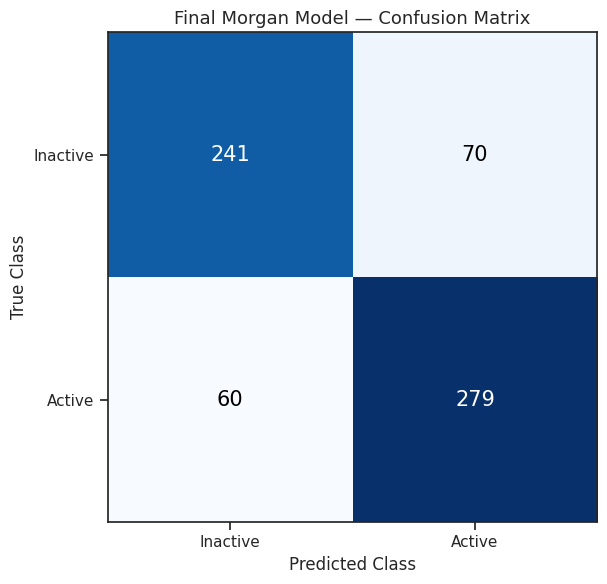

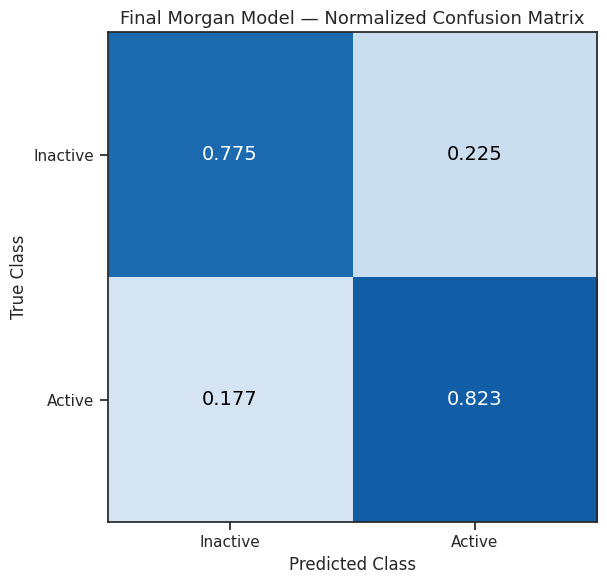

💾 Confusion matrix figures saved.


In [109]:
# CELL 15 — Confusion matrix (numbered + normalized)
cm = np.array([[tn, fp], [fn, tp]])

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm, cmap="Blues")
ax.set_title("Final Morgan Model — Confusion Matrix", fontsize=13)
ax.set_xlabel("Predicted Class"); ax.set_ylabel("True Class")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Inactive", "Active"])
ax.set_yticklabels(["Inactive", "Active"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                fontsize=15, color="white" if cm[i, j] > cm.max()/2 else "black")
plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_confusion_matrix_numbered.png"),
            dpi=300, bbox_inches="tight")
plt.show()

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_title("Final Morgan Model — Normalized Confusion Matrix", fontsize=13)
ax.set_xlabel("Predicted Class"); ax.set_ylabel("True Class")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["Inactive", "Active"])
ax.set_yticklabels(["Inactive", "Active"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm_norm[i, j]:.3f}", ha="center", va="center",
                fontsize=14, color="white" if cm_norm[i, j] > 0.5 else "black")
plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_normalized_confusion_matrix.png"),
            dpi=300, bbox_inches="tight")
plt.show()
print("💾 Confusion matrix figures saved.")

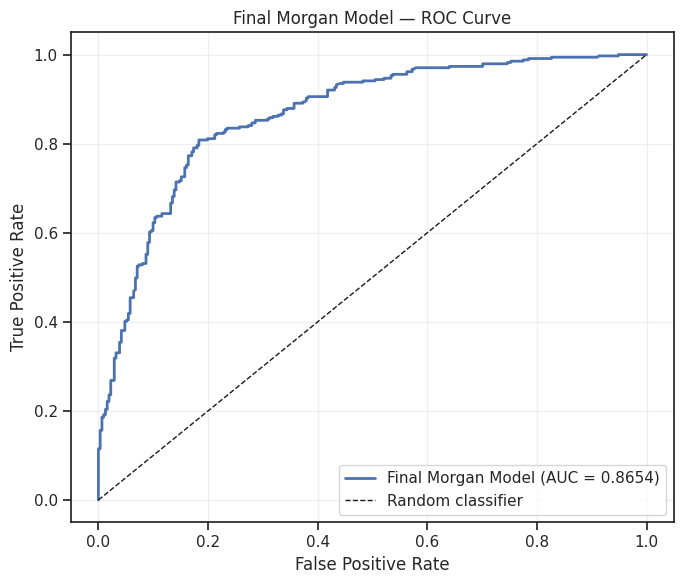

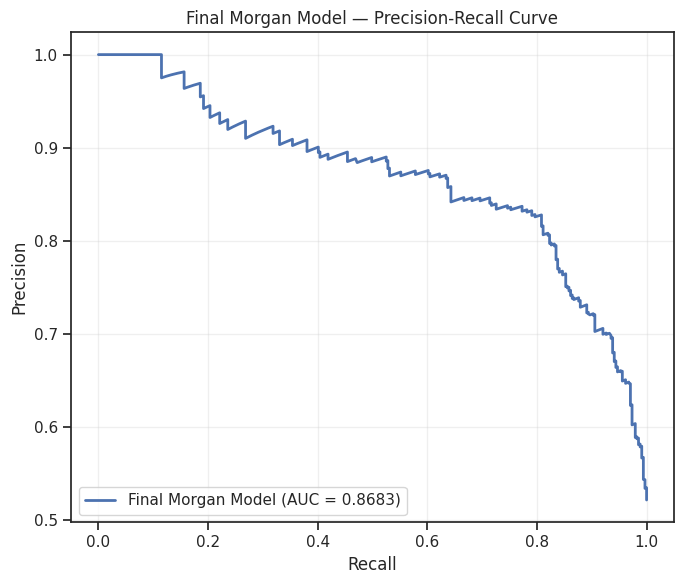

💾 ROC and PR curves saved.


In [110]:
# CELL 16 — ROC and Precision-Recall curves
fpr, tpr, _ = roc_curve(y_test_np, y_prob)
roc_auc_curve = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, lw=2, label=f"Final Morgan Model (AUC = {roc_auc_curve:.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random classifier")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Final Morgan Model — ROC Curve")
plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_roc_curve.png"), dpi=300, bbox_inches="tight")
plt.show()

precision_vals, recall_vals, _ = precision_recall_curve(y_test_np, y_prob)
pr_auc_curve = auc(recall_vals, precision_vals)

plt.figure(figsize=(7, 6))
plt.plot(recall_vals, precision_vals, lw=2, label=f"Final Morgan Model (AUC = {pr_auc_curve:.4f})")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Final Morgan Model — Precision-Recall Curve")
plt.legend(loc="lower left"); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_precision_recall_curve.png"),
            dpi=300, bbox_inches="tight")
plt.show()
print("💾 ROC and PR curves saved.")

Scramble model: CatBoostClassifier

Computing true-label CV ROC-AUC ...
  ✅ True-label CV ROC-AUC: 0.8771 ± 0.0112 (243.5s)

  5/20 | mean = 0.4935 | 1185s
  10/20 | mean = 0.4957 | 2379s
  15/20 | mean = 0.4990 | 3554s
  20/20 | mean = 0.5033 | 4739s

             Parameter     Value
       True_CV_ROC_AUC  0.877096
    True_CV_ROC_AUC_SD  0.011228
Scrambled_Mean_ROC_AUC  0.503345
  Scrambled_SD_ROC_AUC  0.015361
  Y_Scrambling_Z_Score 24.330761
     Empirical_P_Value  0.000000
   Number_of_Scrambles 20.000000
              CV_Folds  5.000000


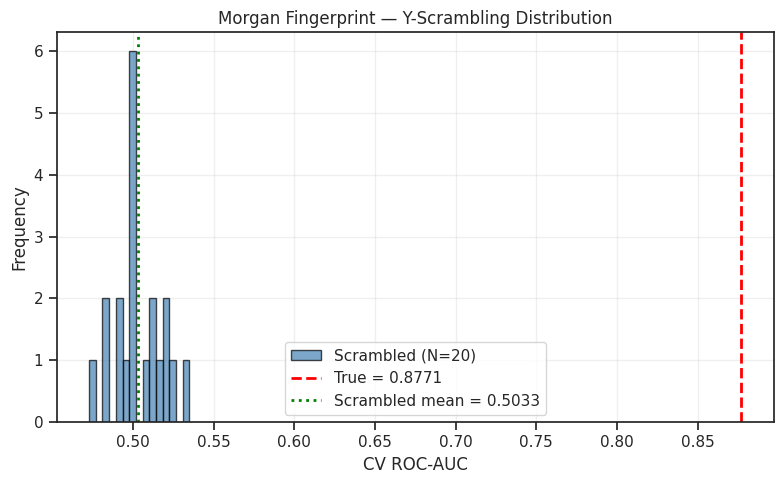


💾 Y-scrambling results and figure saved.


In [171]:
# CELL 17 — Y-scrambling (fast, train set only)
N_SCRAMBLES = 20
CV_FOLDS = 5
scramble_cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Force single-threaded to avoid contention
scramble_model = clone(final_model)
try:
    scramble_model.set_params()
except ValueError:
    pass
if hasattr(scramble_model, "thread_count"):
    scramble_model.set_params(thread_count=1)

print("Scramble model:", type(scramble_model).__name__)

# Reference: true-label CV ROC-AUC on the same model
print("\nComputing true-label CV ROC-AUC ...")
t0 = time.time()
true_scores = cross_val_score(scramble_model, X_train_np, y_train_np,
                              cv=scramble_cv, scoring="roc_auc", n_jobs=-1)
true_mean, true_std = true_scores.mean(), true_scores.std()
print(f"  ✅ True-label CV ROC-AUC: {true_mean:.4f} ± {true_std:.4f} "
      f"({time.time()-t0:.1f}s)\n")

# Scrambled loop
scrambled_scores = []
rng = np.random.RandomState(RANDOM_STATE)
t0 = time.time()

for i in range(N_SCRAMBLES):
    y_perm = rng.permutation(y_train_np)
    s = cross_val_score(scramble_model, X_train_np, y_perm,
                        cv=scramble_cv, scoring="roc_auc", n_jobs=-1)
    scrambled_scores.append(s.mean())
    if (i + 1) % 5 == 0:
        print(f"  {i+1}/{N_SCRAMBLES} | mean = {np.mean(scrambled_scores):.4f} "
              f"| {time.time()-t0:.0f}s")

scrambled_scores = np.array(scrambled_scores)
scram_mean, scram_std = scrambled_scores.mean(), scrambled_scores.std()
z_score = (true_mean - scram_mean) / scram_std
emp_p = (scrambled_scores >= true_mean).mean()

# Summary table
summary = pd.DataFrame({
    "Parameter": ["True_CV_ROC_AUC", "True_CV_ROC_AUC_SD",
                  "Scrambled_Mean_ROC_AUC", "Scrambled_SD_ROC_AUC",
                  "Y_Scrambling_Z_Score", "Empirical_P_Value",
                  "Number_of_Scrambles", "CV_Folds"],
    "Value": [true_mean, true_std, scram_mean, scram_std,
              z_score, emp_p, N_SCRAMBLES, CV_FOLDS]
})

pd.DataFrame({"Scrambled_CV_ROC_AUC": scrambled_scores}).to_csv(
    os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_y_scrambling_results.csv"), index=False)
summary.to_csv(os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_y_scrambling_summary.csv"), index=False)
print("\n" + summary.to_string(index=False))

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(scrambled_scores, bins=15, color="steelblue", alpha=0.7,
        edgecolor="black", label=f"Scrambled (N={N_SCRAMBLES})")
ax.axvline(true_mean, color="red", linestyle="--", lw=2,
           label="True = {:.4f}".format(true_mean))
ax.axvline(scram_mean, color="green", linestyle=":", lw=2,
           label="Scrambled mean = {:.4f}".format(scram_mean))
ax.set_xlabel("CV ROC-AUC"); ax.set_ylabel("Frequency")
ax.set_title("Morgan Fingerprint — Y-Scrambling Distribution")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_y_scrambling_distribution.png"),
            dpi=300, bbox_inches="tight")
plt.show()

print("\n💾 Y-scrambling results and figure saved.")

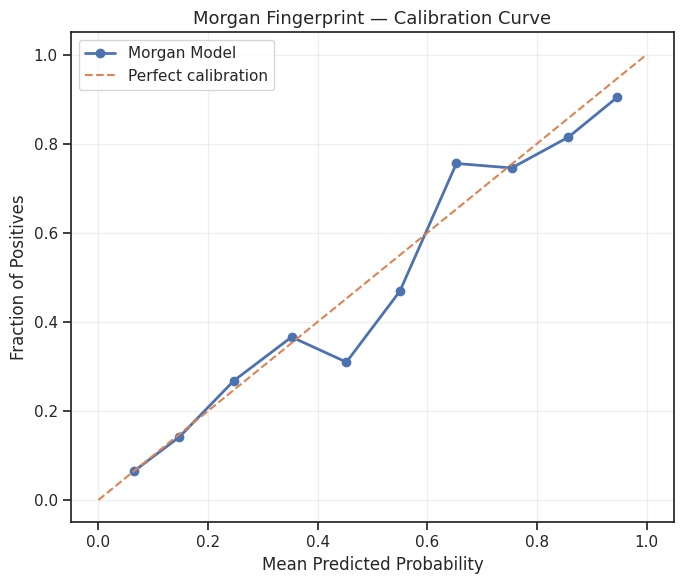

💾 Calibration curve saved.


In [172]:
# CELL 18 — Calibration curve (test set)
prob_true, prob_pred = calibration_curve(y_test_np, y_prob,
                                         n_bins=10, strategy="uniform")

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(prob_pred, prob_true, marker="o", linewidth=2, label="Morgan Model")
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1.5, label="Perfect calibration")
ax.set_xlabel("Mean Predicted Probability", fontsize=12)
ax.set_ylabel("Fraction of Positives", fontsize=12)
ax.set_title("Morgan Fingerprint — Calibration Curve", fontsize=13)
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_calibration_curve.png"),
            dpi=300, bbox_inches="tight")
plt.show()
print("💾 Calibration curve saved.")

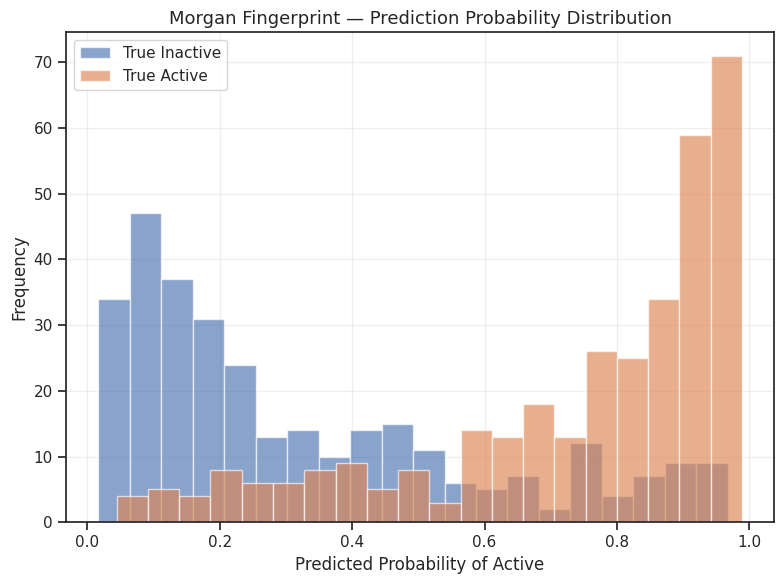

💾 Probability distribution saved.


In [173]:
# CELL 19 — Prediction probability distribution
active_probs   = y_prob[y_test_np == 1]
inactive_probs = y_prob[y_test_np == 0]

fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(inactive_probs, bins=20, alpha=0.65, label="True Inactive")
ax.hist(active_probs,   bins=20, alpha=0.65, label="True Active")
ax.set_xlabel("Predicted Probability of Active", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)
ax.set_title("Morgan Fingerprint — Prediction Probability Distribution", fontsize=13)
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_prediction_probability_distribution.png"),
            dpi=300, bbox_inches="tight")
plt.show()
print("💾 Probability distribution saved.")

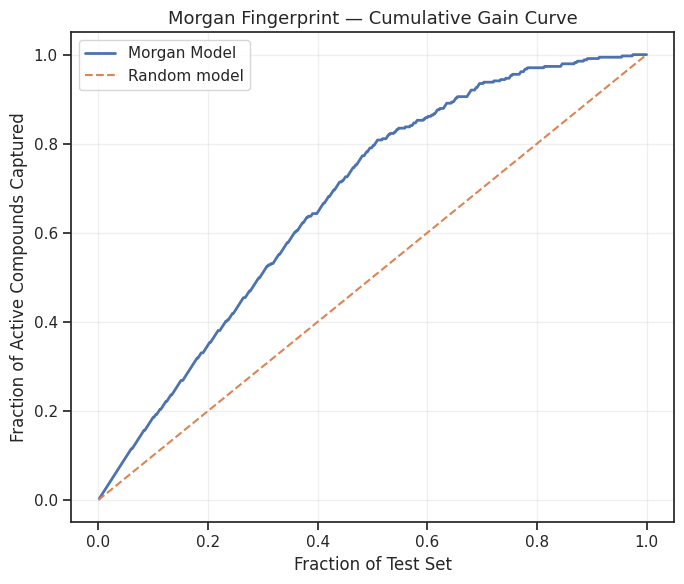

💾 Cumulative gain curve saved.


In [174]:
# CELL 20 — Cumulative gain curve
sorted_idx     = np.argsort(-y_prob)
sorted_labels  = y_test_np[sorted_idx]
total_pos      = np.sum(y_test_np)

if total_pos > 0:
    cumulative_gain = np.cumsum(sorted_labels) / total_pos
else:
    cumulative_gain = np.zeros(len(sorted_labels))

pop_fraction = np.arange(1, len(sorted_labels) + 1) / len(sorted_labels)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(pop_fraction, cumulative_gain, linewidth=2, label="Morgan Model")
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1.5, label="Random model")
ax.set_xlabel("Fraction of Test Set", fontsize=12)
ax.set_ylabel("Fraction of Active Compounds Captured", fontsize=12)
ax.set_title("Morgan Fingerprint — Cumulative Gain Curve", fontsize=13)
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_cumulative_gain.png"),
            dpi=300, bbox_inches="tight")
plt.show()
print("💾 Cumulative gain curve saved.")

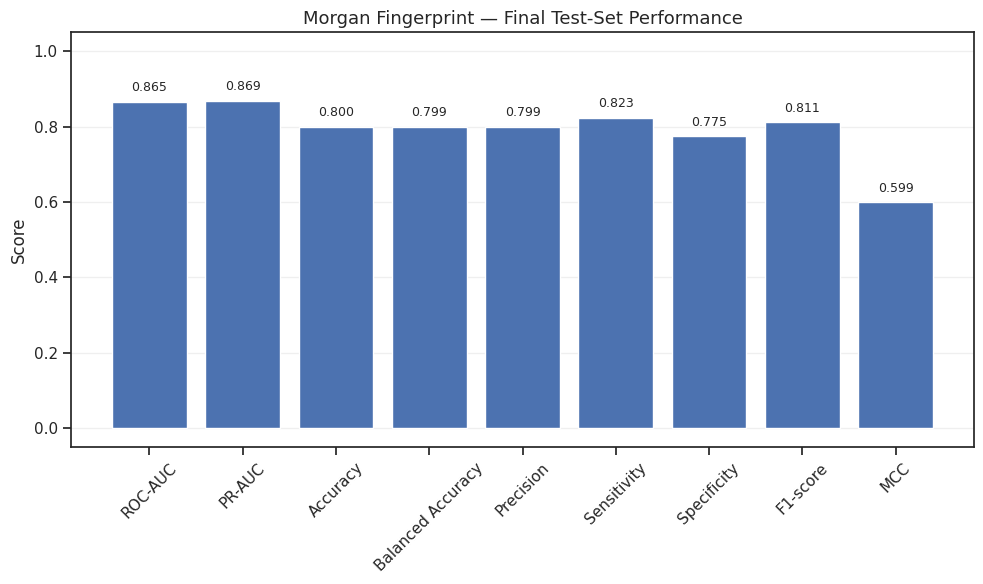

💾 Metric summary figure saved.


In [175]:
# CELL 21 — Final metric summary bar chart
metric_names = ["ROC-AUC", "PR-AUC", "Accuracy", "Balanced Accuracy",
                "Precision", "Sensitivity", "Specificity",
                "F1-score", "MCC"]
metric_values = [roc_auc, pr_auc, acc, bal_acc,
                 prec, sens, spec,
                 f1, mcc]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(metric_names, metric_values)
ax.set_ylim(min(-0.05, min(metric_values) - 0.05), 1.05)
ax.set_ylabel("Score", fontsize=12)
ax.set_title("Morgan Fingerprint — Final Test-Set Performance", fontsize=13)
ax.tick_params(axis="x", rotation=45)
for bar, value in zip(bars, metric_values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.02,
            f"{value:.3f}", ha="center", va="bottom", fontsize=9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_metric_summary.png"),
            dpi=300, bbox_inches="tight")
plt.show()
print("💾 Metric summary figure saved.")

In [176]:
# CELL 22 — Complete publication analysis table
complete_analysis = {
    "Model":                    ["Final Morgan Model"],
    "Fingerprint":              ["Morgan"],
    "Radius":                   [3],
    "Bits":                     [512],
    "Test_Samples":             [len(X_test_np)],
    "Features":                 [X_test_np.shape[1]],
    "ROC_AUC":                  [roc_auc],
    "PR_AUC":                   [pr_auc],
    "Accuracy":                 [acc],
    "Balanced_Accuracy":        [bal_acc],
    "Precision":                [prec],
    "Sensitivity":              [sens],
    "Specificity":              [spec],
    "F1_Score":                 [f1],
    "MCC":                      [mcc],
    "Overall_Score":            [(roc_auc + f1 + mcc + acc + prec + sens) / 6],
    "True_CV_ROC_AUC":          [true_mean],
    "True_CV_ROC_AUC_SD":       [true_std],
    "Y_Scrambled_Mean_ROC_AUC": [scram_mean],
    "Y_Scrambled_SD":           [scram_std],
    "Y_Scrambling_Z_Score":     [z_score],
    "Y_Scrambling_Empirical_P": [emp_p],
    "Number_of_Y_Scrambles":    [N_SCRAMBLES]
}

complete_analysis_df = pd.DataFrame(complete_analysis)
complete_analysis_df.to_csv(
    os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_complete_publication_analysis.csv"),
    index=False
)
print("💾 Complete publication analysis saved.")
display(complete_analysis_df.T)

💾 Complete publication analysis saved.


,0
Model,Final Morgan Model
Fingerprint,Morgan
Radius,3
Bits,512
Test_Samples,650
Features,512
ROC_AUC,0.865445
PR_AUC,0.868581
Accuracy,0.8
Balanced_Accuracy,0.798964


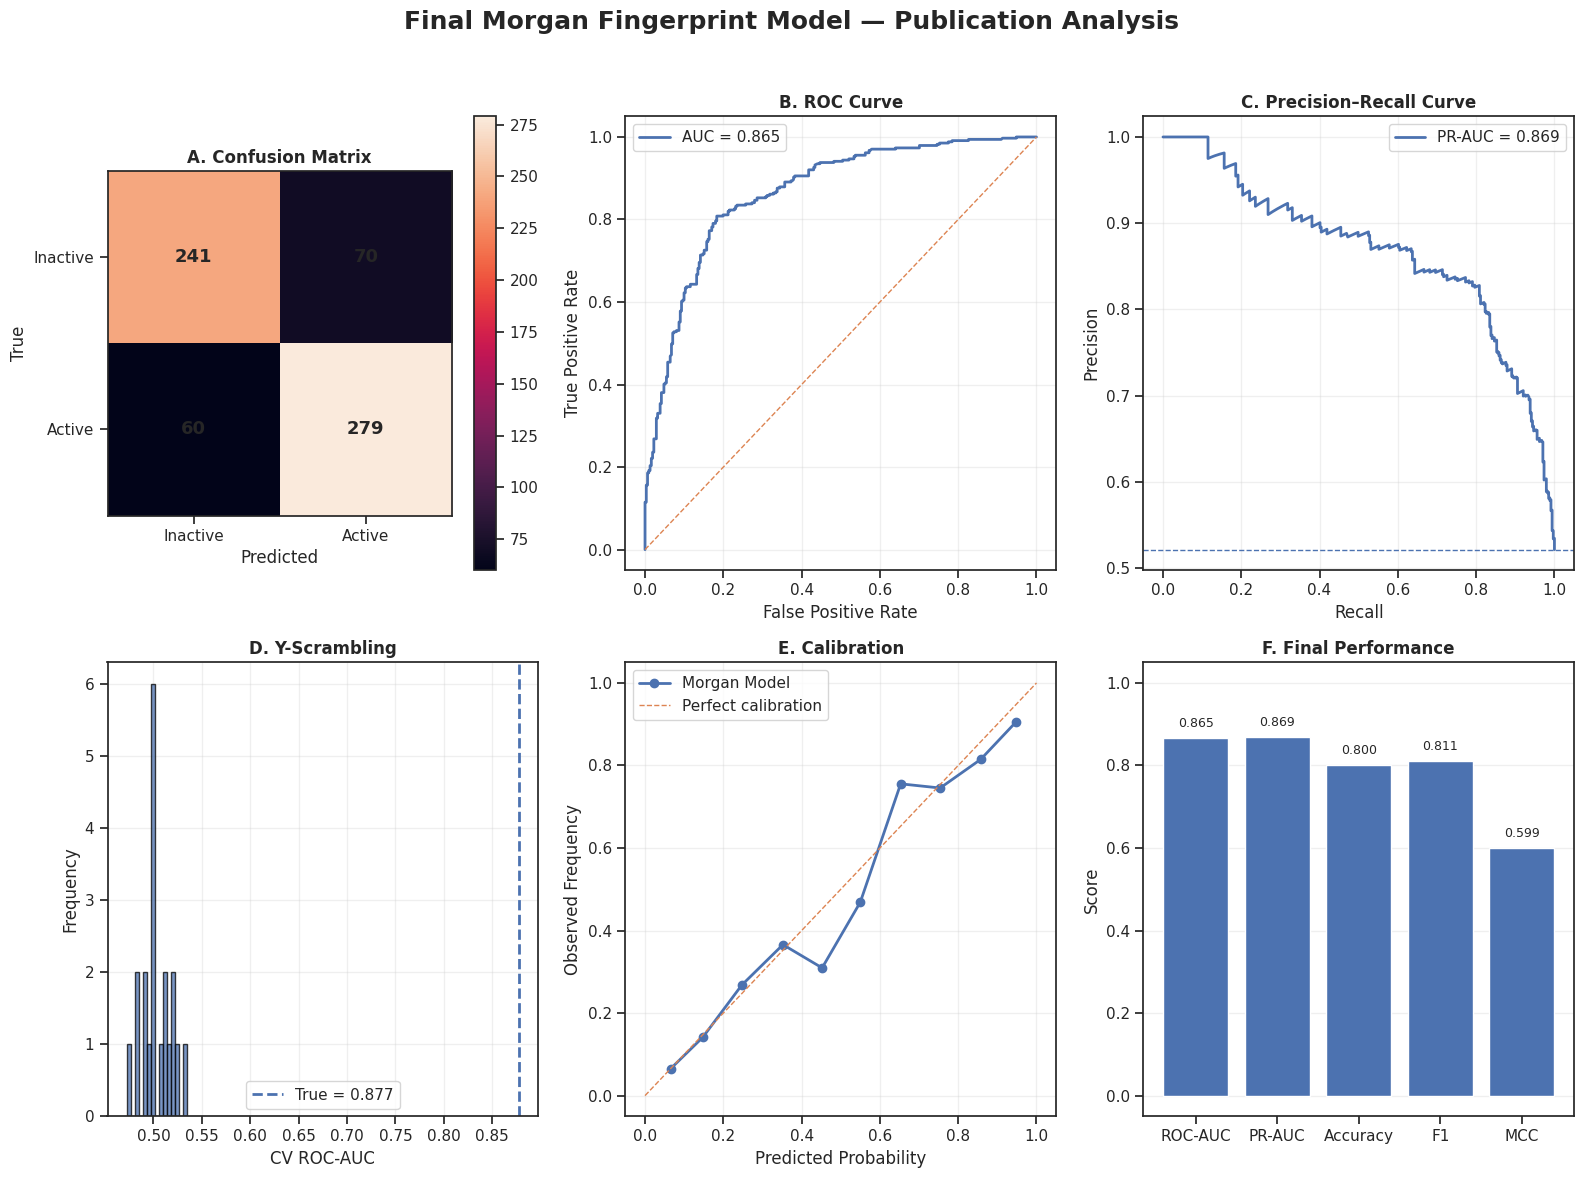

💾 Master publication figure saved.


In [177]:
# CELL 23 — Master publication figure (2×3 panels)
fig = plt.figure(figsize=(16, 12))

# Panel A — Confusion Matrix
ax1 = fig.add_subplot(2, 3, 1)
im1 = ax1.imshow(cm, interpolation="nearest")
ax1.set_title("A. Confusion Matrix", fontweight="bold")
ax1.set_xlabel("Predicted"); ax1.set_ylabel("True")
ax1.set_xticks([0, 1]); ax1.set_yticks([0, 1])
ax1.set_xticklabels(["Inactive", "Active"])
ax1.set_yticklabels(["Inactive", "Active"])
for i in range(2):
    for j in range(2):
        ax1.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                 fontsize=13, fontweight="bold")
fig.colorbar(im1, ax=ax1)

# Panel B — ROC
ax2 = fig.add_subplot(2, 3, 2)
ax2.plot(fpr, tpr, linewidth=2, label=f"AUC = {roc_auc:.3f}")
ax2.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
ax2.set_title("B. ROC Curve", fontweight="bold")
ax2.set_xlabel("False Positive Rate"); ax2.set_ylabel("True Positive Rate")
ax2.legend(); ax2.grid(alpha=0.3)

# Panel C — Precision-Recall
ax3 = fig.add_subplot(2, 3, 3)
ax3.plot(recall_vals, precision_vals, linewidth=2, label=f"PR-AUC = {pr_auc:.3f}")
baseline = np.mean(y_test_np)
ax3.axhline(baseline, linestyle="--", linewidth=1)
ax3.set_title("C. Precision–Recall Curve", fontweight="bold")
ax3.set_xlabel("Recall"); ax3.set_ylabel("Precision")
ax3.legend(); ax3.grid(alpha=0.3)

# Panel D — Y-Scrambling
ax4 = fig.add_subplot(2, 3, 4)
ax4.hist(scrambled_scores, bins=15, alpha=0.75, edgecolor="black")
ax4.axvline(true_mean, linestyle="--", linewidth=2,
            label=f"True = {true_mean:.3f}")
ax4.set_title("D. Y-Scrambling", fontweight="bold")
ax4.set_xlabel("CV ROC-AUC"); ax4.set_ylabel("Frequency")
ax4.legend(); ax4.grid(alpha=0.3)

# Panel E — Calibration
ax5 = fig.add_subplot(2, 3, 5)
ax5.plot(prob_pred, prob_true, marker="o", linewidth=2, label="Morgan Model")
ax5.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="Perfect calibration")
ax5.set_title("E. Calibration", fontweight="bold")
ax5.set_xlabel("Predicted Probability"); ax5.set_ylabel("Observed Frequency")
ax5.legend(); ax5.grid(alpha=0.3)

# Panel F — Final Metrics
ax6 = fig.add_subplot(2, 3, 6)
short_names  = ["ROC-AUC", "PR-AUC", "Accuracy", "F1", "MCC"]
short_values = [roc_auc, pr_auc, acc, f1, mcc]
bars = ax6.bar(short_names, short_values)
ax6.set_ylim(min(-0.05, min(short_values) - 0.05), 1.05)
ax6.set_title("F. Final Performance", fontweight="bold")
ax6.set_ylabel("Score")
for bar, value in zip(bars, short_values):
    ax6.text(bar.get_x() + bar.get_width() / 2, value + 0.02,
             f"{value:.3f}", ha="center", va="bottom", fontsize=9)
ax6.grid(axis="y", alpha=0.3)

fig.suptitle("Final Morgan Fingerprint Model — Publication Analysis",
             fontsize=18, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(os.path.join(FINAL_FOLDER_MORGAN, "final_morgan_master_publication_figure.png"),
            dpi=600, bbox_inches="tight")
plt.show()
print("💾 Master publication figure saved.")

In [178]:
# CELL 24 — Final summary
print("\n" + "=" * 80)
print("MORGAN WORKFLOW COMPLETED SUCCESSFULLY")
print("=" * 80)

print("\nFINAL TEST PERFORMANCE")
print("-" * 80)
print(f"ROC-AUC              : {roc_auc:.4f}")
print(f"PR-AUC               : {pr_auc:.4f}")
print(f"Accuracy             : {acc:.4f}")
print(f"Balanced Accuracy    : {bal_acc:.4f}")
print(f"Precision            : {prec:.4f}")
print(f"Sensitivity (Recall) : {sens:.4f}")
print(f"Specificity          : {spec:.4f}")
print(f"F1-score             : {f1:.4f}")
print(f"MCC                  : {mcc:.4f}")

print("\nY-SCRAMBLING")
print("-" * 80)
print(f"True CV ROC-AUC       : {true_mean:.4f} ± {true_std:.4f}")
print(f"Scrambled mean        : {scram_mean:.4f} ± {scram_std:.4f}")
print(f"Y-scrambling Z-score  : {z_score:.4f}")
print(f"Empirical p-value     : {emp_p:.4f}")
print(f"Number of scrambles   : {N_SCRAMBLES}")

print("\nFILES CREATED")
print("-" * 80)
for folder in [MODEL_SAVE_DIR, FINAL_FOLDER_MORGAN]:
    print(f"\n📁 {folder}")
    for f in sorted(os.listdir(folder)):
        size_mb = os.path.getsize(os.path.join(folder, f)) / (1024 ** 2)
        print(f"   ✓ {f:<55s} {size_mb:.2f} MB")

print("\n" + "=" * 80)
print("Next step: COCONUT screening with final_morgan_model.joblib")
print("=" * 80)


MORGAN WORKFLOW COMPLETED SUCCESSFULLY

FINAL TEST PERFORMANCE
--------------------------------------------------------------------------------
ROC-AUC              : 0.8654
PR-AUC               : 0.8686
Accuracy             : 0.8000
Balanced Accuracy    : 0.7990
Precision            : 0.7994
Sensitivity (Recall) : 0.8230
Specificity          : 0.7749
F1-score             : 0.8110
MCC                  : 0.5990

Y-SCRAMBLING
--------------------------------------------------------------------------------
True CV ROC-AUC       : 0.8771 ± 0.0112
Scrambled mean        : 0.5033 ± 0.0154
Y-scrambling Z-score  : 24.3308
Empirical p-value     : 0.0000
Number of scrambles   : 20

FILES CREATED
--------------------------------------------------------------------------------

📁 /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/morgan_hyperparameter_tuning
   ✓ CatBoost_tuned.joblib                                   1.23 MB
   ✓ ExtraTreesClassifier_tuned.joblib              

Feature Importantance Analysis of Best Morgan Model

#COCONUT DATA ANALYSIS

In [116]:
DRIVE_BASE = WORK_DIR
print(DRIVE_BASE)

/content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project


In [117]:
# COCONUT directory structure
COCONUT_DIR = DRIVE_BASE

folders = [
    "1_input_data",
    "2_models/Morgan",
    "2_models/MACCS",
    "3_filtering",
    "4_morgan_screening",
    "4_maccs_screening",
    "5_final_candidates",
    "logs"  # For progress tracking
]

for folder in folders:
    path = os.path.join(COCONUT_DIR, folder)
    os.makedirs(path, exist_ok=True)

print("=" * 80)
print("COCONUT ANALYSIS DIRECTORY CREATED")

COCONUT ANALYSIS DIRECTORY CREATED


In [118]:
# ============================================================================
# INSTALL REQUIRED PACKAGES
# ============================================================================

!pip install -q rdkit joblib pandas numpy tqdm

# Check RDKit version
import rdkit
print(f"RDKit version: {rdkit.__version__}")

RDKit version: 2026.03.6


In [119]:
# ============================================================================
# OPTION A: UPLOAD COCONUT SDF FROM LOCAL MACHINE
# ============================================================================
# Note: Colab upload limit is ~100MB per file for direct upload.
# For a 2.17 GB file, you need to:
#   1. Upload to Google Drive first (via browser)
#   2. Or use gdown for Google Drive files
#   3. Or stream from a URL

# ============================================================================
# OPTION B: DOWNLOAD FROM GOOGLE DRIVE (if already uploaded)
# ============================================================================

import os

COCONUT_SDF = os.path.join(COCONUT_DIR, "coconut_sdf_3d-09-2026.sdf")

# If file is already in Google Drive, it will be available at the path above.
# If not, upload it to Drive first, or use the code below to copy from another location.

if os.path.exists(COCONUT_SDF):
    size_gb = os.path.getsize(COCONUT_SDF) / (1024**3)
    print(f"✓ COCONUT SDF found: {COCONUT_SDF}")
    print(f"  Size: {size_gb:.2f} GB")
else:
    print(f"✗ COCONUT SDF NOT found at: {COCONUT_SDF}")
    print("\nPlease upload the COCONUT SDF file to Google Drive at:")
    print(f"  {os.path.join(COCONUT_DIR, '1_input_data')}")
    print("\nOr use gdown if the file is on Google Drive:")
    print("  !gdown --id YOUR_FILE_ID -O " + COCONUT_SDF)

# ============================================================================
# OPTION C: DOWNLOAD FROM COCONUT DATABASE (if you have a direct URL)
# ============================================================================

# Uncomment and modify if downloading directly:
# !wget -O {COCONUT_SDF} "https://coconut.naturalproducts.net/download/..."

✓ COCONUT SDF found: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/coconut_sdf_3d-09-2026.sdf
  Size: 2.17 GB


In [151]:
# ============================================================================
# COPY TRAINED MODELS TO COCONUT ANALYSIS FOLDER
# ============================================================================

import os
import shutil

# Source paths (adjust if your models are elsewhere in Drive)
MORGAN_SRC = os.path.join(COCONUT_DIR, "grand_final_selection", "final_morgan_model.joblib")
MACCS_SRC = os.path.join(COCONUT_DIR, "grand_final_selection", "final_maccs_model.joblib")

# Destination paths
MORGAN_DST = os.path.join(COCONUT_DIR, "2_models", "Morgan", "final_morgan_model.joblib")
MACCS_DST = os.path.join(COCONUT_DIR, "2_models", "MACCS", "final_maccs_model.joblib")

# Copy if source exists and destination doesn't
for src, dst, name in [
    (MORGAN_SRC, MORGAN_DST, "Morgan"),
    (MACCS_SRC, MACCS_DST, "MACCS")
]:
    if os.path.exists(src):
        shutil.copy2(src, dst)
        print(f"✓ {name} model copied to: {dst}")
    elif os.path.exists(dst):
        print(f"✓ {name} model already at: {dst}")
    else:
        print(f"✗ {name} model NOT found at: {src}")
        print(f"  Please upload it to: {dst}")

✓ Morgan model copied to: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/2_models/Morgan/final_morgan_model.joblib
✓ MACCS model copied to: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/2_models/MACCS/final_maccs_model.joblib


In [152]:
# ============================================================================
# VERIFY ALL INPUT FILES ARE READY
# ============================================================================

import os

expected_paths = {
    "COCONUT SDF": os.path.join(COCONUT_DIR, "coconut_sdf_3d-09-2026.sdf"),
    "Morgan model": os.path.join(COCONUT_DIR, "2_models", "Morgan", "final_morgan_model.joblib"),
    "MACCS model": os.path.join(COCONUT_DIR, "2_models", "MACCS", "final_maccs_model.joblib"),
}

print("=" * 90)
print("COCONUT ANALYSIS - INPUT VERIFICATION")
print("=" * 90)

all_ok = True
for name, path in expected_paths.items():
    if os.path.exists(path):
        if os.path.isfile(path):
            size = os.path.getsize(path)
            if size > 1024**3:
                size_str = f"{size / (1024**3):.2f} GB"
            elif size > 1024**2:
                size_str = f"{size / (1024**2):.2f} MB"
            else:
                size_str = f"{size / 1024:.2f} KB"
            print(f"✓ {name:<20} : FOUND ({size_str})")
            print(f"  Path: {os.path.abspath(path)}")
        else:
            print(f"✓ {name:<20} : FOUND (directory)")
            print(f"  Path: {os.path.abspath(path)}")
    else:
        print(f"✗ {name:<20} : NOT FOUND")
        print(f"  Expected: {os.path.abspath(path)}")
        all_ok = False

print("\n" + "=" * 90)
if all_ok:
    print("✓ ALL INPUTS READY - Ready to proceed with filtering")
else:
    print("⚠ SOME INPUTS MISSING - Please upload them before proceeding")
print("=" * 90)

COCONUT ANALYSIS - INPUT VERIFICATION
✓ COCONUT SDF          : FOUND (2.17 GB)
  Path: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/coconut_sdf_3d-09-2026.sdf
✓ Morgan model         : FOUND (1.23 MB)
  Path: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/2_models/Morgan/final_morgan_model.joblib
✓ MACCS model          : FOUND (1.20 MB)
  Path: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/2_models/MACCS/final_maccs_model.joblib

✓ ALL INPUTS READY - Ready to proceed with filtering


In [123]:
# ============================================================================
# COCONUT DATABASE FILTERING - COLAB OPTIMIZED WITH CHECKPOINTS
# DUPLICATE +NP score+ PAINS + BRENK + LIPINSKI FILTER
# ============================================================================

import os
import warnings
import numpy as np
import pandas as pd
import time
from tqdm import tqdm

from rdkit import Chem
from rdkit.Chem import FilterCatalog
from rdkit.Chem import Descriptors

# RDKit NP Score
try:
    from rdkit.Chem.rdNPScore import scoreNP
except ImportError:
    scoreNP = None
    print("⚠ rdNPScore not available - NP-Likeness filter will be skipped")

warnings.filterwarnings("ignore")

# ============================================================================
# SETTINGS
# ============================================================================

INPUT_SDF = os.path.join(COCONUT_DIR, "coconut_sdf_3d-09-2026.sdf")
FILTERING_DIR = os.path.join(COCONUT_DIR, "3_filtering")
OUTPUT_SDF = os.path.join(FILTERING_DIR, "coconut_filtered.sdf")

# Checkpoint files (for resume capability)
CHECKPOINT_FILE = os.path.join(FILTERING_DIR, "filtering_checkpoint.txt")
SEEN_SMILES_FILE = os.path.join(FILTERING_DIR, "seen_smiles.txt")

# Make sure filtering directory exists
os.makedirs(FILTERING_DIR, exist_ok=True)

# Filter settings
MIN_NP_LIKENESS_SCORE = 0.0
MAX_LIPINSKI_VIOLATIONS = 1

# ============================================================================
# CHECK INPUT FILE
# ============================================================================

if not os.path.exists(INPUT_SDF):
    raise FileNotFoundError(f"Input COCONUT SDF not found:\n{INPUT_SDF}")

print("=" * 90)
print("COCONUT DATABASE FILTERING - COLAB MODE")
print("=" * 90)
print(f"Input file              : {os.path.abspath(INPUT_SDF)}")
print(f"Output file             : {os.path.abspath(OUTPUT_SDF)}")
print(f"NP-Likeness threshold   : > {MIN_NP_LIKENESS_SCORE}")
print(f"Max Lipinski violations : {MAX_LIPINSKI_VIOLATIONS}")
print("=" * 90)

# ============================================================================
# CREATE PAINS & BRENK FILTERS
# ============================================================================

pains_params = FilterCatalog.FilterCatalogParams()
pains_params.AddCatalog(FilterCatalog.FilterCatalogParams.FilterCatalogs.PAINS)
pains_catalog = FilterCatalog.FilterCatalog(pains_params)

brenk_params = FilterCatalog.FilterCatalogParams()
brenk_params.AddCatalog(FilterCatalog.FilterCatalogParams.FilterCatalogs.BRENK)
brenk_catalog = FilterCatalog.FilterCatalog(brenk_params)

# ============================================================================
# HELPER FUNCTIONS
# ============================================================================

def get_np_likeness_score(mol):
    """Retrieve NP-Likeness score from SDF properties or calculate."""
    for prop in [
        "NP_LIKENESS_score", "NP_LIKENESS", "np_score", "npl_score",
        "natural_product_likeness", "natural_product_likeness_score",
        "coconut_np_score", "NP_SCORE"
    ]:
        if mol.HasProp(prop):
            try:
                return float(mol.GetProp(prop))
            except ValueError:
                pass
    if scoreNP is not None:
        try:
            return scoreNP(mol)
        except Exception:
            pass
    return None


def passes_lipinski(mol, max_violations=1):
    """Check Lipinski Rule of 5."""
    mw = Descriptors.MolWt(mol)
    logp = Descriptors.MolLogP(mol)
    hbd = Descriptors.NumHDonors(mol)
    hba = Descriptors.NumHAcceptors(mol)
    violations = sum([mw > 500, logp > 5, hbd > 5, hba > 10])
    return violations <= max_violations


# ============================================================================
# CHECKPOINT RESUME LOGIC
# ============================================================================

start_index = 0
if os.path.exists(CHECKPOINT_FILE):
    try:
        with open(CHECKPOINT_FILE, "r") as f:
            start_index = int(f.read().strip())
        print(f"\n⚠ Checkpoint found. Resuming from record {start_index:,}")
    except Exception as e:
        print(f"⚠ Could not read checkpoint: {e}. Starting from beginning.")
        start_index = 0

# Load seen SMILES if resuming
seen_smiles = set()
if start_index > 0 and os.path.exists(SEEN_SMILES_FILE):
    with open(SEEN_SMILES_FILE, "r") as f:
        seen_smiles = set(line.strip() for line in f)
    print(f"  Loaded {len(seen_smiles):,} seen SMILES from checkpoint")

# ============================================================================
# READ COCONUT SDF & CREATE WRITER
# ============================================================================

supplier = Chem.SDMolSupplier(INPUT_SDF, removeHs=False, sanitize=True)

# Open writer in append mode if resuming
if start_index > 0 and os.path.exists(OUTPUT_SDF):
    writer = Chem.SDWriter(OUTPUT_SDF)
    # Note: SDWriter doesn't support true append, so we rewrite.
    # For simplicity, we'll re-process and rewrite. For true append,
    # we'd need to track output counts separately.
    # Alternative: use a separate output file per checkpoint chunk.
    writer = Chem.SDWriter(OUTPUT_SDF + ".resume")
else:
    writer = Chem.SDWriter(OUTPUT_SDF)

# ============================================================================
# COUNTERS & TRACKING
# ============================================================================

total_records = 0
invalid_molecules = 0
duplicate_molecules = 0
low_np_score_molecules = 0
pains_molecules = 0
brenk_molecules = 0
lipinski_molecules = 0
final_molecules = 0

# ============================================================================
# PROCESS COCONUT MOLECULES WITH PROGRESS BAR
# ============================================================================

print(f"\nStarting filtering from record {start_index:,}...\n")

# Estimate total for progress bar (approximate)
TOTAL_ESTIMATE = 737_343

# Time tracking
start_time = time.time()

pbar = tqdm(total=TOTAL_ESTIMATE, initial=start_index,
            desc="Filtering", unit="mol", ncols=120)

for idx, mol in enumerate(supplier):
    # Skip already-processed records if resuming
    if idx < start_index:
        continue

    total_records = idx + 1

    # Checkpoint every 10,000 records
    if total_records % 10000 == 0:
        # Save checkpoint
        with open(CHECKPOINT_FILE, "w") as f:
            f.write(str(total_records))
        # Save seen SMILES
        with open(SEEN_SMILES_FILE, "w") as f:
            f.write("\n".join(seen_smiles))

        elapsed = time.time() - start_time
        rate = (total_records - start_index) / elapsed if elapsed > 0 else 0
        eta = (TOTAL_ESTIMATE - total_records) / rate if rate > 0 else 0

        pbar.set_postfix({
            "kept": f"{final_molecules:,}",
            "dup": f"{duplicate_molecules:,}",
            "pains": f"{pains_molecules:,}",
            "brenk": f"{brenk_molecules:,}",
            "rate": f"{rate:.0f}/s",
            "eta": f"{eta/60:.0f}m"
        })

    # ========================================================================
    # 1. VALIDITY CHECK
    # ========================================================================
    if mol is None:
        invalid_molecules += 1
        pbar.update(1)
        continue

    # ========================================================================
    # 2. CANONICAL SMILES
    # ========================================================================
    try:
        canonical_smiles = Chem.MolToSmiles(mol, canonical=True)
    except Exception:
        invalid_molecules += 1
        pbar.update(1)
        continue

    # ========================================================================
    # 3. DUPLICATE FILTER
    # ========================================================================
    if canonical_smiles in seen_smiles:
        duplicate_molecules += 1
        pbar.update(1)
        continue
    seen_smiles.add(canonical_smiles)

    # ========================================================================
    # 4. NP-LIKENESS FILTER
    # ========================================================================
    np_score = get_np_likeness_score(mol)
    if np_score is not None and np_score <= MIN_NP_LIKENESS_SCORE:
        low_np_score_molecules += 1
        pbar.update(1)
        continue

    # ========================================================================
    # 5. PAINS FILTER
    # ========================================================================
    if pains_catalog.HasMatch(mol):
        pains_molecules += 1
        pbar.update(1)
        continue

    # ========================================================================
    # 6. BRENK FILTER
    # ========================================================================
    if brenk_catalog.HasMatch(mol):
        brenk_molecules += 1
        pbar.update(1)
        continue

    # ========================================================================
    # 7. LIPINSKI FILTER
    # ========================================================================
    if not passes_lipinski(mol, max_violations=MAX_LIPINSKI_VIOLATIONS):
        lipinski_molecules += 1
        pbar.update(1)
        continue

    # ========================================================================
    # 8. PASSED ALL FILTERS
    # ========================================================================
    writer.write(mol)
    final_molecules += 1
    pbar.update(1)

pbar.close()
writer.close()

# Clean up checkpoint after successful completion
if os.path.exists(CHECKPOINT_FILE):
    os.remove(CHECKPOINT_FILE)
if os.path.exists(SEEN_SMILES_FILE):
    os.remove(SEEN_SMILES_FILE)

# ============================================================================
# FINAL SUMMARY
# ============================================================================

total_removed = (
    invalid_molecules + duplicate_molecules + low_np_score_molecules
    + pains_molecules + brenk_molecules + lipinski_molecules
)

print("\n" + "=" * 90)
print("COCONUT FILTERING COMPLETED")
print("=" * 90)
print(f"Original SDF records        : {total_records:,}")
print(f"Invalid/unreadable          : {invalid_molecules:,}")
print(f"Duplicate molecules         : {duplicate_molecules:,}")
print(f"Low NP score (<= {MIN_NP_LIKENESS_SCORE:.1f})   : {low_np_score_molecules:,}")
print(f"PAINS flagged               : {pains_molecules:,}")
print(f"BRENK flagged               : {brenk_molecules:,}")
print(f"Lipinski failed             : {lipinski_molecules:,}")
print("-" * 90)
print(f"Total removed               : {total_removed:,}")
print(f"Final filtered molecules    : {final_molecules:,}")
print("=" * 90)

calculated_final = total_records - total_removed
print(f"\nVerification calculated final : {calculated_final:,}")
if calculated_final == final_molecules:
    print("✓ Verification PASSED")
else:
    print("⚠ Verification FAILED — check counters")

print(f"\nFiltered SDF saved as:\n{os.path.abspath(OUTPUT_SDF)}")
print("=" * 90)

⚠ rdNPScore not available - NP-Likeness filter will be skipped
COCONUT DATABASE FILTERING - COLAB MODE
Input file              : /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/coconut_sdf_3d-09-2026.sdf
Output file             : /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/3_filtering/coconut_filtered.sdf
NP-Likeness threshold   : > 0.0
Max Lipinski violations : 1

Starting filtering from record 0...



Filtering:   7%| | 49983/737343 [05:21<1:06:55, 171.19mol/s, kept=10,901, dup=63, pains=3,169, brenk=24,223, rate=155/s,[06:13:42] Conflicting single bond directions around double bond at index 15.
[06:13:42]   BondStereo set to STEREONONE and single bond directions set to NONE.
Filtering:   7%| | 51074/737343 [05:28<1:28:58, 128.55mol/s, kept=13,618, dup=110, pains=3,882, brenk=30,212, rate=155/s[06:13:49] Conflicting single bond directions around double bond at index 15.
[06:13:49]   BondStereo set to STEREONONE and single bond directions set to NONE.
Filtering:   9%| | 64336/737343 [06:55<1:06:48, 167.91mol/s, kept=16,294, dup=163, pains=4,641, brenk=36,191, rate=156/s[06:15:16] Conflicting single bond directions around double bond at index 15.
[06:15:16]   BondStereo set to STEREONONE and single bond directions set to NONE.
Filtering:  17%|▏| 125329/737343 [13:11<1:01:50, 164.96mol/s, kept=31,001, dup=689, pains=9,427, brenk=73,980, rate=158/[06:21:32] Conflicting single bond direc


COCONUT FILTERING COMPLETED
Original SDF records        : 737,343
Invalid/unreadable          : 0
Duplicate molecules         : 24,143
Low NP score (<= 0.0)   : 0
PAINS flagged               : 56,119
BRENK flagged               : 443,381
Lipinski failed             : 30,684
------------------------------------------------------------------------------------------
Total removed               : 554,327
Final filtered molecules    : 183,016

Verification calculated final : 183,016
✓ Verification PASSED

Filtered SDF saved as:
/content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/3_filtering/coconut_filtered.sdf


In [153]:
# ============================================================================
# CHECK FIRST 5 MOLECULES IN FILTERED COCONUT SDF
# ============================================================================

from rdkit import Chem
from rdkit.Chem import rdMolDescriptors

FILTERED_SDF = os.path.join(COCONUT_DIR, "3_filtering", "coconut_filtered.sdf")

print("\n" + "=" * 110)
print("FIRST 5 MOLECULES IN FILTERED COCONUT SDF")
print("=" * 110)
print(f"\nSDF file:\n{FILTERED_SDF}")

supplier = Chem.SDMolSupplier(FILTERED_SDF, removeHs=False, sanitize=True)
count = 0

for mol in supplier:
    if mol is None:
        continue
    count += 1
    print("\n" + "-" * 110)
    print(f"Molecule {count}")
    print("-" * 110)

    name = mol.GetProp("_Name") if mol.HasProp("_Name") else "N/A"
    print(f"Name/ID : {name}")
    print(f"Atoms   : {mol.GetNumAtoms()}")
    print(f"Bonds   : {mol.GetNumBonds()}")
    print(f"Formula : {rdMolDescriptors.CalcMolFormula(mol)}")
    print(f"SMILES  : {Chem.MolToSmiles(mol, isomericSmiles=True)}")

    print("\nProperties:")
    props = mol.GetPropNames()
    if props:
        for prop in props:
            print(f"  {prop}: {mol.GetProp(prop)}")
    else:
        print("  No additional SDF properties found.")

    if count == 5:
        break

print("\n" + "=" * 110)
print(f"✓ Displayed first {count} valid molecules")
print("=" * 110)


FIRST 5 MOLECULES IN FILTERED COCONUT SDF

SDF file:
/content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/3_filtering/coconut_filtered.sdf

--------------------------------------------------------------------------------------------------------------
Molecule 1
--------------------------------------------------------------------------------------------------------------
Name/ID : 
Atoms   : 32
Bonds   : 36
Formula : C18H26N6O8
SMILES  : NC1=NC(=O)N([C@H]2C[C@H](O)[C@@H](CO)O2)[C@@H]2[C@H]1[C@@H]1C(N)=NC(=O)N([C@H]3C[C@H](O)[C@@H](CO)O3)[C@@H]12

Properties:
  IDENTIFIER: CNP0082109.1

--------------------------------------------------------------------------------------------------------------
Molecule 2
--------------------------------------------------------------------------------------------------------------
Name/ID : 
Atoms   : 22
Bonds   : 25
Formula : C19H30O3
SMILES  : C[C@]12CC[C@H]3[C@@H](CC[C@H]4CC(=O)CC[C@@]43CO)[C@@H]1CC[C@@H]2O

Properties:
  IDENTIFIE

In [154]:
# ============================================================================
# SCREENING SETTINGS
# ============================================================================

import os

SDF_FILE = os.path.join(
    COCONUT_DIR, "3_filtering", "coconut_filtered.sdf"
)

MORGAN_MODEL_FILE = os.path.join(
    COCONUT_DIR, "2_models", "Morgan", "final_morgan_model.joblib"
)

MACCS_MODEL_FILE = os.path.join(
    COCONUT_DIR, "2_models", "MACCS", "final_maccs_model.joblib"
)

MORGAN_OUTPUT_DIR = os.path.join(COCONUT_DIR, "4_morgan_screening")
MACCS_OUTPUT_DIR  = os.path.join(COCONUT_DIR, "4_maccs_screening")
FINAL_OUTPUT_DIR  = os.path.join(COCONUT_DIR, "5_final_candidates")

for d in [MORGAN_OUTPUT_DIR, MACCS_OUTPUT_DIR, FINAL_OUTPUT_DIR]:
    os.makedirs(d, exist_ok=True)

# Fingerprint settings
MORGAN_RADIUS = 3
MORGAN_NBITS  = 512
MACCS_NBITS   = 166

print("=" * 70)
print("COCONUT SCREENING SETTINGS")
print("=" * 70)
print(f"\nInput SDF      : {SDF_FILE}")
print(f"Morgan model   : {MORGAN_MODEL_FILE}")
print(f"MACCS model    : {MACCS_MODEL_FILE}")
print(f"Morgan output  : {MORGAN_OUTPUT_DIR}")
print(f"MACCS output   : {MACCS_OUTPUT_DIR}")
print(f"Final output   : {FINAL_OUTPUT_DIR}")

COCONUT SCREENING SETTINGS

Input SDF      : /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/3_filtering/coconut_filtered.sdf
Morgan model   : /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/2_models/Morgan/final_morgan_model.joblib
MACCS model    : /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/2_models/MACCS/final_maccs_model.joblib
Morgan output  : /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/4_morgan_screening
MACCS output   : /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/4_maccs_screening
Final output   : /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/5_final_candidates


In [155]:
# ============================================================================
# LOAD FINAL TRAINED MODELS
# ============================================================================

import joblib

print("\n" + "=" * 110)
print("LOADING FINAL TRAINED MODELS")
print("=" * 110)

best_morgan_model = joblib.load(MORGAN_MODEL_FILE)
best_maccs_model  = joblib.load(MACCS_MODEL_FILE)

print(
    f"\n✓ Morgan model loaded successfully:"
    f"\n  {MORGAN_MODEL_FILE}"
    f"\n  Model: {type(best_morgan_model).__name__}"
)

print(
    f"\n✓ MACCS model loaded successfully:"
    f"\n  {MACCS_MODEL_FILE}"
    f"\n  Model: {type(best_maccs_model).__name__}"
)


LOADING FINAL TRAINED MODELS

✓ Morgan model loaded successfully:
  /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/2_models/Morgan/final_morgan_model.joblib
  Model: CatBoostClassifier

✓ MACCS model loaded successfully:
  /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/2_models/MACCS/final_maccs_model.joblib
  Model: CatBoostClassifier


In [156]:
# ============================================================================
# 5. VERIFY MODEL CLASSES & CAPABILITIES
# ============================================================================

print("=" * 110)
print("MODEL CLASS & PREDICTION CAPABILITY VERIFICATION")
print("=" * 110)

if not hasattr(best_morgan_model, "classes_"):
    raise ValueError("Morgan model does not contain classes_.")

if not hasattr(best_maccs_model, "classes_"):
    raise ValueError("MACCS model does not contain classes_.")

print(
    f"\nMorgan classes: "
    f"{list(best_morgan_model.classes_)}"
)

print(
    f"MACCS classes: "
    f"{list(best_maccs_model.classes_)}"
)

for model_name, model in [
    ("Morgan", best_morgan_model),
    ("MACCS", best_maccs_model)
]:

    print(f"\n{model_name} model capabilities:")
    print(f"  predict()       : {hasattr(model, 'predict')}")
    print(f"  predict_proba() : {hasattr(model, 'predict_proba')}")

MODEL CLASS & PREDICTION CAPABILITY VERIFICATION

Morgan classes: [np.int64(0), np.int64(1)]
MACCS classes: [np.int64(0), np.int64(1)]

Morgan model capabilities:
  predict()       : True
  predict_proba() : True

MACCS model capabilities:
  predict()       : True
  predict_proba() : True


In [157]:
# ============================================================================
# 5. VERIFY MODEL FEATURE DIMENSIONS
# ============================================================================

print("\n" + "=" * 110)
print("MODEL FEATURE DIMENSION VERIFICATION")
print("=" * 110)

morgan_features = len(best_morgan_model.feature_names_)
maccs_features = len(best_maccs_model.feature_names_)

print(f"\nMorgan model expects : {morgan_features} features")
print(f"Expected Morgan     : {MORGAN_NBITS} features")

print(f"\nMACCS model expects  : {maccs_features} features")
print(f"Expected MACCS       : {MACCS_NBITS} features")


# ============================================================================
# VERIFY
# ============================================================================

if morgan_features != MORGAN_NBITS:
    raise ValueError(
        f"Morgan feature mismatch: model expects {morgan_features}, "
        f"but screening is configured for {MORGAN_NBITS}."
    )

if maccs_features != MACCS_NBITS:
    raise ValueError(
        f"MACCS feature mismatch: model expects {maccs_features}, "
        f"but screening is configured for {MACCS_NBITS}."
    )

print("\n✓ Morgan feature dimension verified")
print("✓ MACCS feature dimension verified")
print("\nAll model dimensions are correct.")


MODEL FEATURE DIMENSION VERIFICATION

Morgan model expects : 512 features
Expected Morgan     : 512 features

MACCS model expects  : 166 features
Expected MACCS       : 166 features

✓ Morgan feature dimension verified
✓ MACCS feature dimension verified

All model dimensions are correct.


In [158]:
# ============================================================================
# CHECK FIRST 5 MOLECULES IN FILTERED COCONUT SDF
# ============================================================================

from rdkit import Chem
from rdkit.Chem import rdMolDescriptors

print("\n" + "=" * 110)
print("FIRST 5 MOLECULES IN FILTERED COCONUT SDF")
print("=" * 110)
print(f"\nSDF file: {SDF_FILE}")

supplier = Chem.SDMolSupplier(SDF_FILE, removeHs=False, sanitize=True)

count = 0
for mol in supplier:
    if mol is None:
        continue
    count += 1

    print("\n" + "-" * 110)
    print(f"Molecule {count}")
    print("-" * 110)

    name = mol.GetProp("_Name") if mol.HasProp("_Name") else "N/A"
    print(f"Name/ID : {name}")
    print(f"Atoms   : {mol.GetNumAtoms()}")
    print(f"Bonds   : {mol.GetNumBonds()}")
    print(f"Formula : {rdMolDescriptors.CalcMolFormula(mol)}")
    print(f"SMILES  : {Chem.MolToSmiles(mol, isomericSmiles=True)}")

    props = mol.GetPropNames()
    if props:
        print("\nProperties:")
        for prop in props:
            print(f"  {prop}: {mol.GetProp(prop)}")

    if count == 5:
        break

print("\n" + "=" * 110)
print(f"✓ Displayed first {count} valid molecules")
print("=" * 110)


FIRST 5 MOLECULES IN FILTERED COCONUT SDF

SDF file: /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/3_filtering/coconut_filtered.sdf

--------------------------------------------------------------------------------------------------------------
Molecule 1
--------------------------------------------------------------------------------------------------------------
Name/ID : 
Atoms   : 32
Bonds   : 36
Formula : C18H26N6O8
SMILES  : NC1=NC(=O)N([C@H]2C[C@H](O)[C@@H](CO)O2)[C@@H]2[C@H]1[C@@H]1C(N)=NC(=O)N([C@H]3C[C@H](O)[C@@H](CO)O3)[C@@H]12

Properties:
  IDENTIFIER: CNP0082109.1

--------------------------------------------------------------------------------------------------------------
Molecule 2
--------------------------------------------------------------------------------------------------------------
Name/ID : 
Atoms   : 22
Bonds   : 25
Formula : C19H30O3
SMILES  : C[C@]12CC[C@H]3[C@@H](CC[C@H]4CC(=O)CC[C@@]43CO)[C@@H]1CC[C@@H]2O

Properties:
  IDENTIFIE

In [159]:
# ============================================================================
# COCONUT DATABASE SCREENING
# FINAL STRATEGY:
#
#   TOP 500 FROM MORGAN
#          +
#   TOP 500 FROM MACCS
#          ↓
#       COMBINE
#          ↓
#   REMOVE DUPLICATE SMILES
#          ↓
#   FINAL UNIQUE CANDIDATES
#
# IMPORTANT:
#   The final number does NOT have to be 100.
#
#   Example:
#       Morgan Top 500 = 500
#       MACCS Top 500  = 500
#       Overlap       = 200
#       Final unique  = 800
#
#   Selection is based on model ranking, not an arbitrary probability
#   threshold.
#
# DIRECTORY STRUCTURE:
#
#   coconut_analysis/
#       ├── 1_input_data/
#       ├── 2_models/
#       │   ├── Morgan/
#       │   └── MACCS/
#       ├── 3_filtering/
#       ├── 4_morgan_screening/
#       ├── 4_maccs_screening/
#       └── 5_final_candidates/
#
# ============================================================================

import os
import re
import numpy as np
import pandas as pd

from rdkit import Chem
from rdkit.Chem import AllChem, MACCSkeys
from rdkit.DataStructs import ConvertToNumpyArray


# ============================================================================
# 1. DIRECTORY CONFIGURATION
# ============================================================================
#
# These directories were created in your previous setup cell.
# We define them here as well so this screening section is self-contained.
# ============================================================================

MORGAN_SCREEN_DIR = os.path.join(
    COCONUT_DIR,
    "4_morgan_screening"
)

MACCS_SCREEN_DIR = os.path.join(
    COCONUT_DIR,
    "4_maccs_screening"
)

FINAL_CANDIDATES_DIR = os.path.join(
    COCONUT_DIR,
    "5_final_candidates"
)


# Make sure the directories exist

os.makedirs(
    MORGAN_SCREEN_DIR,
    exist_ok=True
)

os.makedirs(
    MACCS_SCREEN_DIR,
    exist_ok=True
)

os.makedirs(
    FINAL_CANDIDATES_DIR,
    exist_ok=True
)


# ============================================================================
# 7. LOAD COCONUT SDF
# ============================================================================

print("\n")
print("=" * 110)
print("LOADING COCONUT SDF")
print("=" * 110)

supplier = Chem.SDMolSupplier(
    SDF_FILE,
    removeHs=False,
    sanitize=True
)

# Call len() to obtain total number of SDF records
total_sdf_records = len(supplier)

print(
    f"Total SDF records: "
    f"{total_sdf_records:,}"
)

# Re-instantiate supplier so iteration starts from the beginning
supplier = Chem.SDMolSupplier(
    SDF_FILE,
    removeHs=False,
    sanitize=True
)


# ============================================================================
# 8. PREPARE MOLECULES
# ============================================================================

valid_molecules = []
invalid_count = 0

print("\nProcessing molecules...")


# ============================================================================
# Possible COCONUT ID fields
# ============================================================================

possible_id_fields = [

    "IDENTIFIER",
    "identifier",
    "Identifier",

    "CNP_ID",
    "cnp_id",

    "COCONUT_ID",
    "coconut_id",

    "ID",
    "id"

]


# ============================================================================
# Regex pattern for COCONUT CNP ID
#
# Examples:
#
#   CNP0082109
#   CNP0082109.1
#
# Stored final ID:
#
#   CNP0082109
# ============================================================================

cnp_regex = re.compile(
    r"CNP\d{7}(?:\.\d+)?",
    re.IGNORECASE
)


# ============================================================================
# PROCESS EVERY SDF RECORD
# ============================================================================

for sdf_index, mol in enumerate(supplier):

    # ------------------------------------------------------------------------
    # Skip invalid SDF records
    # ------------------------------------------------------------------------

    if mol is None:

        invalid_count += 1
        continue


    try:

        # ====================================================================
        # Generate canonical SMILES
        # ====================================================================

        smiles = Chem.MolToSmiles(
            mol,
            canonical=True
        )

        if not smiles:

            invalid_count += 1
            continue


        # ====================================================================
        # Collect SDF properties
        # ====================================================================

        properties = {}

        for prop_name in mol.GetPropNames():

            try:

                properties[prop_name] = (
                    mol.GetProp(prop_name)
                )

            except Exception:

                properties[prop_name] = ""


        # ====================================================================
        # Identify COCONUT / CNP ID
        # ====================================================================

        cnp_id = ""


        # --------------------------------------------------------------------
        # Step 1:
        # Check preferred identifier fields
        # --------------------------------------------------------------------

        for field in possible_id_fields:

            if field in properties:

                val = str(
                    properties[field]
                ).strip()

                match = cnp_regex.search(val)

                if match:

                    # Example:
                    # CNP0082109.1 → CNP0082109

                    raw_cnp = (
                        match.group(0)
                        .upper()
                    )

                    cnp_id = (
                        raw_cnp
                        .split(".")[0]
                    )

                    break

                elif val and not cnp_id:

                    cnp_id = val


        # --------------------------------------------------------------------
        # Step 2:
        # Check RDKit molecule title (_Name)
        # --------------------------------------------------------------------

        if not cnp_id and mol.HasProp("_Name"):

            title = (
                mol.GetProp("_Name")
                .strip()
            )

            if title:

                match = cnp_regex.search(title)

                if match:

                    cnp_id = (
                        match.group(0)
                        .upper()
                        .split(".")[0]
                    )

                else:

                    cnp_id = title


        # --------------------------------------------------------------------
        # Step 3:
        # Scan all property values as fallback
        # --------------------------------------------------------------------

        if not cnp_id:

            for val in properties.values():

                match = cnp_regex.search(
                    str(val)
                )

                if match:

                    cnp_id = (
                        match.group(0)
                        .upper()
                        .split(".")[0]
                    )

                    break


        # --------------------------------------------------------------------
        # Step 4:
        # Final fallback ID
        # --------------------------------------------------------------------

        if not cnp_id:

            cnp_id = (
                f"COCONUT_SDF_{sdf_index + 1}"
            )


        # ====================================================================
        # Store molecule
        # ====================================================================

        valid_molecules.append({

            "SDF_Index":
                sdf_index + 1,

            "CNP_ID":
                cnp_id,

            "COCONUT_ID":
                cnp_id,

            "SMILES":
                smiles,

            "Molecule":
                mol,

            "SDF_Properties":
                properties

        })


    except Exception:

        invalid_count += 1


# ============================================================================
# PREPARATION SUMMARY
# ============================================================================

print(
    f"\nValid molecules   : "
    f"{len(valid_molecules):,}"
)

print(
    f"Invalid molecules : "
    f"{invalid_count:,}"
)


if len(valid_molecules) == 0:

    raise ValueError(
        "No valid molecules were found in the SDF file."
    )


# ============================================================================
# 9. GENERATE MORGAN FINGERPRINTS
# ============================================================================
#
# EXACT TRAINING SETTINGS:
#
#   Radius = 3
#   nBits  = 512
#
# IMPORTANT:
#
#   morgan_valid_indices stores the position of each fingerprint
#   in valid_molecules.
#
# ============================================================================

print("\n")
print("=" * 110)
print("GENERATING MORGAN FINGERPRINTS")
print("=" * 110)


morgan_fingerprints = []

morgan_valid_indices = []

morgan_failed = 0


# ============================================================================
# Generate fingerprints
# ============================================================================

for i, item in enumerate(valid_molecules):

    mol = item["Molecule"]

    try:

        # --------------------------------------------------------------------
        # EXACT Morgan fingerprint settings used during model training
        # --------------------------------------------------------------------

        fp = AllChem.GetMorganFingerprintAsBitVect(

            mol,

            radius=3,

            nBits=512

        )


        # --------------------------------------------------------------------
        # Convert RDKit fingerprint to NumPy array
        # --------------------------------------------------------------------

        arr = np.zeros(

            (512,),

            dtype=np.int8

        )

        ConvertToNumpyArray(

            fp,

            arr

        )


        # --------------------------------------------------------------------
        # Store fingerprint
        # --------------------------------------------------------------------

        morgan_fingerprints.append(
            arr
        )

        # Store index linking fingerprint → valid_molecules
        morgan_valid_indices.append(
            i
        )


    except Exception:

        morgan_failed += 1


# ============================================================================
# Convert Morgan fingerprints to matrix
# ============================================================================

X_morgan_screen = np.asarray(

    morgan_fingerprints,

    dtype=np.int8

)


# ============================================================================
# Morgan summary
# ============================================================================

print(
    f"Morgan fingerprint matrix shape: "
    f"{X_morgan_screen.shape}"
)

print(
    f"Morgan fingerprint failures: "
    f"{morgan_failed:,}"
)


if len(X_morgan_screen) == 0:

    raise ValueError(
        "No valid Morgan fingerprints were generated."
    )


# ============================================================================
# Verify Morgan feature dimension
# ============================================================================

if X_morgan_screen.shape[1] != 512:

    raise ValueError(

        f"Morgan fingerprint dimension mismatch. "
        f"Expected 512, "
        f"got {X_morgan_screen.shape[1]}"

    )


# ============================================================================
# 10. GENERATE MACCS FINGERPRINTS
# ============================================================================
#
# RDKit produces 167 bits.
#
# Bit 0 is removed to reproduce the exact 166-feature representation
# used during MACCS model training.
#
# ============================================================================

print("\n")
print("=" * 110)
print("GENERATING MACCS FINGERPRINTS")
print("=" * 110)


maccs_fingerprints = []

maccs_valid_indices = []

maccs_failed = 0


# ============================================================================
# Generate MACCS fingerprints
# ============================================================================

for i, item in enumerate(valid_molecules):

    mol = item["Molecule"]

    try:

        # --------------------------------------------------------------------
        # Generate RDKit MACCS fingerprint
        # --------------------------------------------------------------------

        fp = MACCSkeys.GenMACCSKeys(
            mol
        )


        # --------------------------------------------------------------------
        # RDKit MACCS = 167 bits
        # --------------------------------------------------------------------

        arr = np.zeros(

            (167,),

            dtype=np.int8

        )

        ConvertToNumpyArray(

            fp,

            arr

        )


        # --------------------------------------------------------------------
        # Remove RDKit bit 0
        #
        # Result = 166 features
        # --------------------------------------------------------------------

        arr_166 = arr[1:]


        if len(arr_166) != 166:

            raise ValueError(

                f"Expected 166 MACCS features, "
                f"got {len(arr_166)}"

            )


        # --------------------------------------------------------------------
        # Store fingerprint
        # --------------------------------------------------------------------

        maccs_fingerprints.append(

            arr_166

        )

        # Store index linking fingerprint → valid_molecules
        maccs_valid_indices.append(

            i

        )


    except Exception:

        maccs_failed += 1


# ============================================================================
# Convert MACCS fingerprints to matrix
# ============================================================================

X_maccs_screen = np.asarray(

    maccs_fingerprints,

    dtype=np.int8

)


# ============================================================================
# MACCS summary
# ============================================================================

print(
    f"MACCS fingerprint matrix shape: "
    f"{X_maccs_screen.shape}"
)

print(
    f"MACCS fingerprint failures: "
    f"{maccs_failed:,}"
)


if len(X_maccs_screen) == 0:

    raise ValueError(
        "No valid MACCS fingerprints were generated."
    )


# ============================================================================
# Verify MACCS feature dimension
# ============================================================================

if X_maccs_screen.shape[1] != 166:

    raise ValueError(

        f"MACCS fingerprint dimension mismatch. "
        f"Expected 166, "
        f"got {X_maccs_screen.shape[1]}"

    )


# ============================================================================
# 11. FINAL PREPARATION SUMMARY
# ============================================================================

print("\n")
print("=" * 110)
print("COCONUT SCREENING PREPARATION COMPLETE")
print("=" * 110)

print(
    f"Total SDF records       : "
    f"{total_sdf_records:,}"
)

print(
    f"Valid molecules         : "
    f"{len(valid_molecules):,}"
)

print(
    f"Morgan fingerprints     : "
    f"{len(morgan_valid_indices):,}"
)

print(
    f"MACCS fingerprints      : "
    f"{len(maccs_valid_indices):,}"
)

print(
    f"Morgan features         : "
    f"{X_morgan_screen.shape[1]}"
)

print(
    f"MACCS features          : "
    f"{X_maccs_screen.shape[1]}"
)

print("\nOutput directories:")

print(
    f"Morgan screening : "
    f"{MORGAN_SCREEN_DIR}"
)

print(
    f"MACCS screening  : "
    f"{MACCS_SCREEN_DIR}"
)

print(
    f"Final candidates : "
    f"{FINAL_CANDIDATES_DIR}"
)

print("\n")
print("=" * 110)
print("READY FOR MODEL PREDICTION AND TOP-500 RANKING")
print("=" * 110)



LOADING COCONUT SDF
Total SDF records: 183,016

Processing molecules...

Valid molecules   : 183,016
Invalid molecules : 0


GENERATING MORGAN FINGERPRINTS


Streaming output truncated to the last 5000 lines.
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:13:29] DEPRECATION WARNING: please use MorganGenerator
[09:1

Morgan fingerprint matrix shape: (183016, 512)
Morgan fingerprint failures: 0


GENERATING MACCS FINGERPRINTS
MACCS fingerprint matrix shape: (183016, 166)
MACCS fingerprint failures: 0


COCONUT SCREENING PREPARATION COMPLETE
Total SDF records       : 183,016
Valid molecules         : 183,016
Morgan fingerprints     : 183,016
MACCS fingerprints      : 183,016
Morgan features         : 512
MACCS features          : 166

Output directories:
Morgan screening : /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/4_morgan_screening
MACCS screening  : /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/4_maccs_screening
Final candidates : /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/5_final_candidates


READY FOR MODEL PREDICTION AND TOP-500 RANKING


In [160]:
# ============================================================================
# 11. CHECK FINGERPRINT DIMENSIONS
# ============================================================================

print("\n")
print("=" * 110)
print("CHECKING FINGERPRINT DIMENSIONS")
print("=" * 110)

print(
    f"Morgan screening features : "
    f"{X_morgan_screen.shape[1]}"
)

print(
    f"Expected Morgan features  : "
    f"512"
)

print(
    f"MACCS screening features  : "
    f"{X_maccs_screen.shape[1]}"
)

print(
    f"Expected MACCS features   : "
    f"166"
)


# ----------------------------------------------------------------------------
# Verify Morgan dimensions
# ----------------------------------------------------------------------------

if X_morgan_screen.shape[1] != 512:

    raise ValueError(
        "Morgan fingerprint dimension is incorrect."
    )


# ----------------------------------------------------------------------------
# Verify MACCS dimensions
# ----------------------------------------------------------------------------

if X_maccs_screen.shape[1] != 166:

    raise ValueError(
        "MACCS fingerprint dimension is incorrect."
    )


print("\n✓ Fingerprint dimensions are correct.")


# ============================================================================
# 11A. IDENTIFY ACTIVE CLASS INDEX
# ============================================================================

print("\n")
print("=" * 110)
print("IDENTIFYING ACTIVE CLASS INDEX")
print("=" * 110)


# ----------------------------------------------------------------------------
# Morgan
# ----------------------------------------------------------------------------

if not hasattr(
    best_morgan_model,
    "classes_"
):

    raise ValueError(
        "Morgan model does not have classes_."
    )


print(
    f"Morgan model classes: "
    f"{best_morgan_model.classes_}"
)


if 1 not in best_morgan_model.classes_:

    raise ValueError(
        "Active class (1) was not found in Morgan model classes."
    )


morgan_active_index = list(
    best_morgan_model.classes_
).index(1)


print(
    f"Morgan Active class index: "
    f"{morgan_active_index}"
)


# ----------------------------------------------------------------------------
# MACCS
# ----------------------------------------------------------------------------

if not hasattr(
    best_maccs_model,
    "classes_"
):

    raise ValueError(
        "MACCS model does not have classes_."
    )


print(
    f"MACCS model classes: "
    f"{best_maccs_model.classes_}"
)


if 1 not in best_maccs_model.classes_:

    raise ValueError(
        "Active class (1) was not found in MACCS model classes."
    )


maccs_active_index = list(
    best_maccs_model.classes_
).index(1)


print(
    f"MACCS Active class index: "
    f"{maccs_active_index}"
)


# ============================================================================
# 12. MORGAN PREDICTION
# ============================================================================

print("\n")
print("=" * 110)
print("PREDICTING COCONUT MOLECULES — MORGAN")
print("=" * 110)


# ----------------------------------------------------------------------------
# Check probability support
# ----------------------------------------------------------------------------

if not hasattr(
    best_morgan_model,
    "predict_proba"
):

    raise ValueError(
        "Morgan model does not provide predict_proba()."
    )


# ----------------------------------------------------------------------------
# Predict classes
# ----------------------------------------------------------------------------

morgan_predictions = (
    best_morgan_model.predict(
        X_morgan_screen
    )
)


# ----------------------------------------------------------------------------
# Predict Active probabilities
# ----------------------------------------------------------------------------

morgan_probabilities = (
    best_morgan_model.predict_proba(
        X_morgan_screen
    )[
        :,
        morgan_active_index
    ]
)


print(
    f"Morgan predictions completed: "
    f"{len(morgan_predictions):,}"
)

print(
    f"Morgan Active probability range: "
    f"{morgan_probabilities.min():.6f} "
    f"to "
    f"{morgan_probabilities.max():.6f}"
)


# ============================================================================
# 13. MACCS PREDICTION
# ============================================================================

print("\n")
print("=" * 110)
print("PREDICTING COCONUT MOLECULES — MACCS")
print("=" * 110)


# ----------------------------------------------------------------------------
# Check probability support
# ----------------------------------------------------------------------------

if not hasattr(
    best_maccs_model,
    "predict_proba"
):

    raise ValueError(
        "MACCS model does not provide predict_proba()."
    )


# ----------------------------------------------------------------------------
# Predict classes
# ----------------------------------------------------------------------------

maccs_predictions = (
    best_maccs_model.predict(
        X_maccs_screen
    )
)


# ----------------------------------------------------------------------------
# Predict Active probabilities
# ----------------------------------------------------------------------------

maccs_probabilities = (
    best_maccs_model
    .predict_proba(
        X_maccs_screen
    )[
        :,
        maccs_active_index
    ]
)


print(
    f"MACCS predictions completed: "
    f"{len(maccs_predictions):,}"
)

print(
    f"MACCS Active probability range: "
    f"{maccs_probabilities.min():.6f} "
    f"to "
    f"{maccs_probabilities.max():.6f}"
)


# ============================================================================
# FINAL PREDICTION CHECK
# ============================================================================

print("\n")
print("=" * 110)
print("PREDICTION CHECK")
print("=" * 110)

print(
    f"Number of COCONUT molecules : "
    f"{len(valid_molecules):,}"
)

print(
    f"Morgan predictions          : "
    f"{len(morgan_predictions):,}"
)

print(
    f"Morgan probabilities        : "
    f"{len(morgan_probabilities):,}"
)

print(
    f"MACCS predictions           : "
    f"{len(maccs_predictions):,}"
)

print(
    f"MACCS probabilities         : "
    f"{len(maccs_probabilities):,}"
)


# ----------------------------------------------------------------------------
# Verify that every molecule received a prediction
# ----------------------------------------------------------------------------

if len(morgan_predictions) != len(valid_molecules):

    raise ValueError(
        "Morgan prediction count does not match the number "
        "of valid COCONUT molecules."
    )


if len(maccs_predictions) != len(valid_molecules):

    raise ValueError(
        "MACCS prediction count does not match the number "
        "of valid COCONUT molecules."
    )


if len(morgan_probabilities) != len(valid_molecules):

    raise ValueError(
        "Morgan probability count does not match the number "
        "of valid COCONUT molecules."
    )


if len(maccs_probabilities) != len(valid_molecules):

    raise ValueError(
        "MACCS probability count does not match the number "
        "of valid COCONUT molecules."
    )


print("\n✓ All prediction counts are correct.")
print("✓ Morgan and MACCS predictions are ready for ranking.")



CHECKING FINGERPRINT DIMENSIONS
Morgan screening features : 512
Expected Morgan features  : 512
MACCS screening features  : 166
Expected MACCS features   : 166

✓ Fingerprint dimensions are correct.


IDENTIFYING ACTIVE CLASS INDEX
Morgan model classes: [0 1]
Morgan Active class index: 1
MACCS model classes: [0 1]
MACCS Active class index: 1


PREDICTING COCONUT MOLECULES — MORGAN
Morgan predictions completed: 183,016
Morgan Active probability range: 0.037362 to 0.917654


PREDICTING COCONUT MOLECULES — MACCS
MACCS predictions completed: 183,016
MACCS Active probability range: 0.007422 to 0.985556


PREDICTION CHECK
Number of COCONUT molecules : 183,016
Morgan predictions          : 183,016
Morgan probabilities        : 183,016
MACCS predictions           : 183,016
MACCS probabilities         : 183,016

✓ All prediction counts are correct.
✓ Morgan and MACCS predictions are ready for ranking.


In [161]:
# ============================================================================
# 14. CREATE MORGAN RESULTS TABLE
# ============================================================================

print("\n")
print("=" * 110)
print("CREATING MORGAN RESULTS TABLE")
print("=" * 110)

morgan_results = []

for position, original_index in enumerate(
    morgan_valid_indices
):

    item = valid_molecules[
        original_index
    ]

    prediction = morgan_predictions[
        position
    ]

    probability = morgan_probabilities[
        position
    ]

    morgan_results.append({

        "SDF_Index":
            item["SDF_Index"],

        "CNP_ID":
            item["CNP_ID"],

        "COCONUT_ID":
            item["COCONUT_ID"],

        "SMILES":
            item["SMILES"],

        "Morgan_Prediction":
            str(prediction),

        "Morgan_Active_Probability":
            float(probability)

    })


morgan_results_df = pd.DataFrame(
    morgan_results
)


print(
    f"Morgan results created: "
    f"{len(morgan_results_df):,}"
)


# ============================================================================
# 15. RANK ALL MOLECULES BY MORGAN
# ============================================================================

morgan_results_df = (
    morgan_results_df
    .sort_values(
        by="Morgan_Active_Probability",
        ascending=False
    )
    .reset_index(drop=True)
)


morgan_results_df[
    "Morgan_Rank"
] = np.arange(
    1,
    len(morgan_results_df) + 1
)


print(
    f"Morgan molecules ranked: "
    f"{len(morgan_results_df):,}"
)


# ----------------------------------------------------------------------------
# SAVE COMPLETE MORGAN SCREENING RESULTS
# ----------------------------------------------------------------------------

morgan_ranked_file = os.path.join(
    MORGAN_SCREEN_DIR,
    "coconut_morgan_ranked.csv"
)

morgan_results_df.to_csv(
    morgan_ranked_file,
    index=False
)

print(
    f"Morgan ranked results saved to:\n"
    f"{morgan_ranked_file}"
)


# ============================================================================
# 16. CREATE MACCS RESULTS TABLE
# ============================================================================

print("\n")
print("=" * 110)
print("CREATING MACCS RESULTS TABLE")
print("=" * 110)

maccs_results = []

for position, original_index in enumerate(
    maccs_valid_indices
):

    item = valid_molecules[
        original_index
    ]

    prediction = maccs_predictions[
        position
    ]

    probability = maccs_probabilities[
        position
    ]

    maccs_results.append({

        "SDF_Index":
            item["SDF_Index"],

        "CNP_ID":
            item["CNP_ID"],

        "COCONUT_ID":
            item["COCONUT_ID"],

        "SMILES":
            item["SMILES"],

        "MACCS_Prediction":
            str(prediction),

        "MACCS_Active_Probability":
            float(probability)

    })


maccs_results_df = pd.DataFrame(
    maccs_results
)


print(
    f"MACCS results created: "
    f"{len(maccs_results_df):,}"
)


# ============================================================================
# 17. RANK ALL MOLECULES BY MACCS
# ============================================================================

maccs_results_df = (
    maccs_results_df
    .sort_values(
        by="MACCS_Active_Probability",
        ascending=False
    )
    .reset_index(drop=True)
)


maccs_results_df[
    "MACCS_Rank"
] = np.arange(
    1,
    len(maccs_results_df) + 1
)


print(
    f"MACCS molecules ranked: "
    f"{len(maccs_results_df):,}"
)


# ----------------------------------------------------------------------------
# SAVE COMPLETE MACCS SCREENING RESULTS
# ----------------------------------------------------------------------------

maccs_ranked_file = os.path.join(
    MACCS_SCREEN_DIR,
    "coconut_maccs_ranked.csv"
)

maccs_results_df.to_csv(
    maccs_ranked_file,
    index=False
)

print(
    f"MACCS ranked results saved to:\n"
    f"{maccs_ranked_file}"
)


# ============================================================================
# 18. SELECT TOP 500 MORGAN
# ============================================================================

TOP_N = 500


top500_morgan_df = (
    morgan_results_df
    .head(TOP_N)
    .copy()
)


print("\n")
print("=" * 110)
print("TOP 500 MORGAN CANDIDATES")
print("=" * 110)

print(
    top500_morgan_df[
        [
            "Morgan_Rank",
            "CNP_ID",
            "COCONUT_ID",
            "Morgan_Prediction",
            "Morgan_Active_Probability",
            "SMILES"
        ]
    ]
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ----------------------------------------------------------------------------
# SAVE TOP 500 MORGAN
# ----------------------------------------------------------------------------

top500_morgan_file = os.path.join(
    MORGAN_SCREEN_DIR,
    "coconut_morgan_top500.csv"
)

top500_morgan_df.to_csv(
    top500_morgan_file,
    index=False
)

print(
    f"\nMorgan Top 500 saved to:\n"
    f"{top500_morgan_file}"
)


# ============================================================================
# 19. SELECT TOP 500 MACCS
# ============================================================================

top500_maccs_df = (
    maccs_results_df
    .head(TOP_N)
    .copy()
)


print("\n")
print("=" * 110)
print("TOP 500 MACCS CANDIDATES")
print("=" * 110)

print(
    top500_maccs_df[
        [
            "MACCS_Rank",
            "CNP_ID",
            "COCONUT_ID",
            "MACCS_Prediction",
            "MACCS_Active_Probability",
            "SMILES"
        ]
    ]
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ----------------------------------------------------------------------------
# SAVE TOP 500 MACCS
# ----------------------------------------------------------------------------

top500_maccs_file = os.path.join(
    MACCS_SCREEN_DIR,
    "coconut_maccs_top500.csv"
)

top500_maccs_df.to_csv(
    top500_maccs_file,
    index=False
)

print(
    f"\nMACCS Top 500 saved to:\n"
    f"{top500_maccs_file}"
)


# ============================================================================
# 20. PREPARE TOP-500 LISTS FOR UNION
# ============================================================================

print("\n")
print("=" * 110)
print("PREPARING MORGAN + MACCS TOP-500 UNION")
print("=" * 110)


morgan_selection = top500_morgan_df[
    [
        "SDF_Index",
        "CNP_ID",
        "COCONUT_ID",
        "SMILES",
        "Morgan_Rank",
        "Morgan_Prediction",
        "Morgan_Active_Probability"
    ]
].copy()


maccs_selection = top500_maccs_df[
    [
        "SDF_Index",
        "CNP_ID",
        "COCONUT_ID",
        "SMILES",
        "MACCS_Rank",
        "MACCS_Prediction",
        "MACCS_Active_Probability"
    ]
].copy()


print(
    f"Morgan Top 500 : "
    f"{len(morgan_selection)}"
)

print(
    f"MACCS Top 500  : "
    f"{len(maccs_selection)}"
)


# ============================================================================
# 21. UNION OF MORGAN TOP 500 + MACCS TOP 500
# ============================================================================

print("\n")
print("=" * 110)
print("CREATING FINAL UNION")
print("=" * 110)


# ----------------------------------------------------------------------------
# Outer merge = UNION
#
# A molecule appearing in:
#   Morgan only       → retained
#   MACCS only        → retained
#   Morgan + MACCS   → retained once
#
# SMILES is used as the molecular identity.
# ----------------------------------------------------------------------------

combined_top500_df = pd.merge(

    morgan_selection,

    maccs_selection,

    on="SMILES",

    how="outer",

    suffixes=(
        "_Morgan",
        "_MACCS"
    )
)


# ============================================================================
# 21A. COMBINE MOLECULE IDENTIFICATION INFORMATION
# ============================================================================

combined_top500_df[
    "SDF_Index"
] = (
    combined_top500_df[
        "SDF_Index_Morgan"
    ]
    .combine_first(
        combined_top500_df[
            "SDF_Index_MACCS"
        ]
    )
)


combined_top500_df[
    "CNP_ID"
] = (
    combined_top500_df[
        "CNP_ID_Morgan"
    ]
    .combine_first(
        combined_top500_df[
            "CNP_ID_MACCS"
        ]
    )
)


combined_top500_df[
    "COCONUT_ID"
] = (
    combined_top500_df[
        "COCONUT_ID_Morgan"
    ]
    .combine_first(
        combined_top500_df[
            "COCONUT_ID_MACCS"
        ]
    )
)


# ============================================================================
# 21B. IDENTIFY HOW EACH MOLECULE WAS SELECTED
# ============================================================================

combined_top500_df[
    "Selected_By"
] = np.select(

    [
        combined_top500_df[
            "Morgan_Rank"
        ].notna()
        &
        combined_top500_df[
            "MACCS_Rank"
        ].notna(),

        combined_top500_df[
            "Morgan_Rank"
        ].notna(),

        combined_top500_df[
            "MACCS_Rank"
        ].notna()
    ],

    [
        "Morgan + MACCS",
        "Morgan",
        "MACCS"
    ],

    default="Unknown"
)


# ============================================================================
# 21C. COMBINED PROBABILITY INFORMATION
# ============================================================================

combined_top500_df[
    "Mean_Active_Probability"
] = combined_top500_df[
    [
        "Morgan_Active_Probability",
        "MACCS_Active_Probability"
    ]
].mean(
    axis=1,
    skipna=True
)


combined_top500_df[
    "Min_Active_Probability"
] = combined_top500_df[
    [
        "Morgan_Active_Probability",
        "MACCS_Active_Probability"
    ]
].min(
    axis=1,
    skipna=True
)


# ============================================================================
# 21D. REMOVE DUPLICATE MOLECULES
# ============================================================================

combined_top500_df = (
    combined_top500_df
    .drop_duplicates(
        subset="SMILES",
        keep="first"
    )
    .reset_index(drop=True)
)


# ============================================================================
# 21E. RESTORE ORIGINAL COCONUT SDF INFORMATION
# ============================================================================

print("\n")
print("=" * 110)
print("ADDING ORIGINAL COCONUT MOLECULE INFORMATION")
print("=" * 110)


# Create lookup from SDF index to original molecule information

molecule_lookup = {
    item["SDF_Index"]: item
    for item in valid_molecules
}


# ----------------------------------------------------------------------------
# Collect original SDF properties for final candidates
# ----------------------------------------------------------------------------

original_properties = []

for sdf_index in combined_top500_df[
    "SDF_Index"
]:

    item = molecule_lookup.get(
        sdf_index
    )

    if item is None:

        original_properties.append({})

    else:

        original_properties.append(
            item.get(
                "SDF_Properties",
                {}
            )
        )


properties_df = pd.DataFrame(
    original_properties
)


# ----------------------------------------------------------------------------
# Prefix original SDF property columns
# ----------------------------------------------------------------------------

if not properties_df.empty:

    properties_df = properties_df.add_prefix(
        "COCONUT_"
    )


# ============================================================================
# 21F. COMBINE MODEL RESULTS + ORIGINAL MOLECULE INFORMATION
# ============================================================================

final_candidates_df = pd.concat(
    [
        combined_top500_df.reset_index(drop=True),
        properties_df.reset_index(drop=True)
    ],
    axis=1
)


# ============================================================================
# 21G. FINAL COLUMN ORDER
# ============================================================================

priority_columns = [

    "SDF_Index",
    "CNP_ID",
    "COCONUT_ID",
    "SMILES",

    "Selected_By",

    "Morgan_Rank",
    "Morgan_Prediction",
    "Morgan_Active_Probability",

    "MACCS_Rank",
    "MACCS_Prediction",
    "MACCS_Active_Probability",

    "Mean_Active_Probability",
    "Min_Active_Probability"
]


# Keep only priority columns that actually exist

priority_columns = [
    col
    for col in priority_columns
    if col in final_candidates_df.columns
]


remaining_columns = [
    col
    for col in final_candidates_df.columns
    if col not in priority_columns
]


final_candidates_df = final_candidates_df[
    priority_columns + remaining_columns
]


# ============================================================================
# 21H. FINAL QUALITY CONTROL
# ============================================================================

print("\n")
print("=" * 110)
print("FINAL CANDIDATE QUALITY CONTROL")
print("=" * 110)


total_morgan = len(
    top500_morgan_df
)

total_maccs = len(
    top500_maccs_df
)

total_union = len(
    final_candidates_df
)

duplicate_count = (
    final_candidates_df[
        "SMILES"
    ]
    .duplicated()
    .sum()
)

overlap_count = (
    (
        final_candidates_df[
            "Selected_By"
        ]
        == "Morgan + MACCS"
    )
    .sum()
)


print(
    f"Morgan Top 500              : "
    f"{total_morgan}"
)

print(
    f"MACCS Top 500               : "
    f"{total_maccs}"
)

print(
    f"Maximum possible union     : "
    f"{total_morgan + total_maccs}"
)

print(
    f"Morgan + MACCS overlap     : "
    f"{overlap_count}"
)

print(
    f"Final unique candidates    : "
    f"{total_union}"
)

print(
    f"Duplicate SMILES remaining : "
    f"{duplicate_count}"
)


# ----------------------------------------------------------------------------
# Verify no duplicates remain
# ----------------------------------------------------------------------------

if duplicate_count != 0:

    raise ValueError(
        "Duplicate SMILES remain in final candidate list."
    )


# ============================================================================
# 21I. SAVE FINAL CANDIDATES
# ============================================================================

final_candidates_file = os.path.join(
    FINAL_CANDIDATES_DIR,
    "coconut_final_unique_candidates.csv"
)


final_candidates_df.to_csv(
    final_candidates_file,
    index=False
)


print("\n")
print("=" * 110)
print("FINAL CANDIDATE FILE SAVED")
print("=" * 110)

print(
    f"File:\n"
    f"{final_candidates_file}"
)

print(
    f"\nFinal unique candidates: "
    f"{len(final_candidates_df)}"
)

print("\n✓ Morgan Top 500 saved separately.")
print("✓ MACCS Top 500 saved separately.")
print("✓ Final candidates are the UNION of both Top 500 lists.")
print("✓ Duplicate molecules removed using SMILES.")
print("✓ Original COCONUT SDF properties retained.")
print("✓ No probability cutoff was applied.")



CREATING MORGAN RESULTS TABLE
Morgan results created: 183,016
Morgan molecules ranked: 183,016
Morgan ranked results saved to:
/content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/4_morgan_screening/coconut_morgan_ranked.csv


CREATING MACCS RESULTS TABLE
MACCS results created: 183,016
MACCS molecules ranked: 183,016
MACCS ranked results saved to:
/content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/4_maccs_screening/coconut_maccs_ranked.csv


TOP 500 MORGAN CANDIDATES
 Morgan_Rank     CNP_ID COCONUT_ID Morgan_Prediction  Morgan_Active_Probability                                                                                                                                                               SMILES
           1 CNP0482515 CNP0482515                 1                     0.9177                                                                                                                    COC[C@@H]1C[C@H](n2cc(NC(=O)C3CC3)cn2)CN1C1CCOCC

In [162]:
# ============================================================================
# FINAL SCREENING SUMMARY
# ============================================================================

summary_file = os.path.join(
    FINAL_CANDIDATES_DIR,
    "screening_summary.txt"
)

# Calculate Morgan/MACCS overlap directly
morgan_smiles = set(
    top500_morgan_df["SMILES"].dropna()
)

maccs_smiles = set(
    top500_maccs_df["SMILES"].dropna()
)

overlap_count = len(
    morgan_smiles.intersection(maccs_smiles)
)

with open(summary_file, "w") as f:

    f.write("COCONUT DATABASE SCREENING SUMMARY\n")
    f.write("=" * 80 + "\n\n")

    # ------------------------------------------------------------------------
    # INPUT DATA
    # ------------------------------------------------------------------------

    f.write("1. INPUT DATABASE\n")
    f.write("-" * 80 + "\n")
    f.write(f"Input SDF file           : {SDF_FILE}\n")
    f.write(
        f"Total SDF records        : "
        f"{total_sdf_records:,}\n"
    )
    f.write(
        f"Valid molecules screened : "
        f"{len(valid_molecules):,}\n"
    )
    f.write(
        f"Invalid molecules        : "
        f"{invalid_count:,}\n\n"
    )

    # ------------------------------------------------------------------------
    # FINGERPRINTS
    # ------------------------------------------------------------------------

    f.write("2. MOLECULAR FINGERPRINTS\n")
    f.write("-" * 80 + "\n")
    f.write(
        "Morgan fingerprint        : Radius = 3, nBits = 512\n"
    )
    f.write(
        "MACCS fingerprint         : 166 features\n\n"
    )

    # ------------------------------------------------------------------------
    # MORGAN
    # ------------------------------------------------------------------------

    f.write("3. MORGAN SCREENING\n")
    f.write("-" * 80 + "\n")
    f.write(
        f"Molecules ranked         : "
        f"{len(morgan_results_df):,}\n"
    )
    f.write(
        f"Top candidates selected  : "
        f"{len(top500_morgan_df):,}\n"
    )
    f.write(
        f"Ranked results file      : "
        f"{morgan_ranked_file}\n"
    )
    f.write(
        f"Top 500 file              : "
        f"{top500_morgan_file}\n\n"
    )

    # ------------------------------------------------------------------------
    # MACCS
    # ------------------------------------------------------------------------

    f.write("4. MACCS SCREENING\n")
    f.write("-" * 80 + "\n")
    f.write(
        f"Molecules ranked         : "
        f"{len(maccs_results_df):,}\n"
    )
    f.write(
        f"Top candidates selected  : "
        f"{len(top500_maccs_df):,}\n"
    )
    f.write(
        f"Ranked results file      : "
        f"{maccs_ranked_file}\n"
    )
    f.write(
        f"Top 500 file              : "
        f"{top500_maccs_file}\n\n"
    )

    # ------------------------------------------------------------------------
    # FINAL UNION
    # ------------------------------------------------------------------------

    f.write("5. FINAL CANDIDATE SELECTION\n")
    f.write("-" * 80 + "\n")

    f.write(
        "Morgan selection         : Top 500\n"
    )

    f.write(
        "MACCS selection          : Top 500\n"
    )

    f.write(
        "Combination method       : UNION\n"
    )

    f.write(
        "Duplicate removal        : Canonical SMILES\n"
    )

    f.write(
        f"Morgan/MACCS overlap     : "
        f"{overlap_count:,}\n"
    )

    f.write(
        f"Final unique candidates  : "
        f"{len(final_candidates_df):,}\n"
    )

    f.write(
        f"Final candidate file     : "
        f"{final_candidates_file}\n\n"
    )

    # ------------------------------------------------------------------------
    # METHODOLOGICAL NOTES
    # ------------------------------------------------------------------------

    f.write("6. METHODOLOGICAL NOTES\n")
    f.write("-" * 80 + "\n")

    f.write(
        "• Morgan Top 500 selected by Morgan Active probability.\n"
    )

    f.write(
        "• MACCS Top 500 selected by MACCS Active probability.\n"
    )

    f.write(
        "• Both Top-500 lists were combined using UNION.\n"
    )

    f.write(
        "• Duplicate molecules were removed using canonical SMILES.\n"
    )

    f.write(
        "• Original COCONUT SDF information was retained.\n"
    )

    f.write(
        "• No artificial combined ranking was applied.\n"
    )

    f.write(
        "• No probability cutoff was applied.\n"
    )

    f.write(
        "• Mean and minimum probabilities are descriptive only.\n"
    )


# ============================================================================
# DISPLAY SUMMARY
# ============================================================================

print("\n")
print("=" * 110)
print("FINAL SCREENING SUMMARY")
print("=" * 110)

print(
    f"\nTotal valid molecules screened : "
    f"{len(valid_molecules):,}"
)

print(
    f"Morgan Top 500                  : "
    f"{len(top500_morgan_df):,}"
)

print(
    f"MACCS Top 500                   : "
    f"{len(top500_maccs_df):,}"
)

print(
    f"Morgan/MACCS overlap           : "
    f"{overlap_count:,}"
)

print(
    f"Final unique candidates        : "
    f"{len(final_candidates_df):,}"
)

print(
    f"\nFinal candidate file:\n"
    f"{final_candidates_file}"
)

print(
    f"\nSummary saved to:\n"
    f"{summary_file}"
)

print("\n✓ Screening summary completed successfully.")



FINAL SCREENING SUMMARY

Total valid molecules screened : 183,016
Morgan Top 500                  : 500
MACCS Top 500                   : 500
Morgan/MACCS overlap           : 51
Final unique candidates        : 949

Final candidate file:
/content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/5_final_candidates/coconut_final_unique_candidates.csv

Summary saved to:
/content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/5_final_candidates/screening_summary.txt

✓ Screening summary completed successfully.


In [163]:
pip install pandas requests tqdm

In [168]:
import pandas as pd

# Read only the header / first 5 rows to check column names quickly
csv_file = os.path.join(COCONUT_DIR,'coconut_csv-09-2026.csv')
df_coconut = pd.read_csv(csv_file, nrows=5)

print("--- All Headings in COCONUT CSV ---")
for idx, col in enumerate(df_coconut.columns, 1):
    print(f"{idx}. {col}")

# Search specifically for organism or taxon related columns
organism_cols = [col for col in df_coconut.columns if 'org' in col.lower() or 'tax' in col.lower() or 'source' in col.lower()]
print("\n--- Potential Organism Columns Found ---")
print(organism_cols if organism_cols else "No explicit organism/taxon column names detected.")

--- All Headings in COCONUT CSV ---
1. identifier
2. canonical_smiles
3. standard_inchi
4. standard_inchi_key
5. name
6. iupac_name
7. annotation_level
8. total_atom_count
9. heavy_atom_count
10. molecular_weight
11. exact_molecular_weight
12. molecular_formula
13. alogp
14. topological_polar_surface_area
15. rotatable_bond_count
16. hydrogen_bond_acceptors
17. hydrogen_bond_donors
18. hydrogen_bond_acceptors_lipinski
19. hydrogen_bond_donors_lipinski
20. lipinski_rule_of_five_violations
21. aromatic_rings_count
22. qed_drug_likeliness
23. formal_charge
24. fractioncsp3
25. number_of_minimal_rings
26. van_der_walls_volume
27. contains_sugar
28. contains_ring_sugars
29. contains_linear_sugars
30. murcko_framework
31. np_likeness
32. chemical_class
33. chemical_sub_class
34. chemical_super_class
35. direct_parent_classification
36. np_classifier_pathway
37. np_classifier_superclass
38. np_classifier_class
39. np_classifier_is_glycoside
40. organisms
41. collections
42. dois
43. synonyms


In [169]:
import pandas as pd

# 1. Load candidates
csv_unique = os.path.join(COCONUT_DIR,"5_final_candidates","coconut_final_unique_candidates.csv")
df = pd.read_csv(csv_unique)
df['clean_id'] = df['COCONUT_IDENTIFIER'].astype(str).str.split('.').str[0]

# 2. Match organisms from the dump (chunked for speed)
target_ids = set(df['clean_id'].unique())
organism_map = {}

for chunk in pd.read_csv(csv_file, usecols=['identifier', 'organisms'], chunksize=100000, low_memory=False):
    chunk['clean_id'] = chunk['identifier'].astype(str).str.split('.').str[0]
    matched = chunk[chunk['clean_id'].isin(target_ids) & chunk['organisms'].notna()]

    for _, row in matched.iterrows():
        cid, org = row['clean_id'], str(row['organisms']).strip()
        if org:
            organism_map[cid] = f"{organism_map[cid]} | {org}" if cid in organism_map and org not in organism_map[cid] else org

# 3. Map organisms
df['Source_Organisms'] = df['clean_id'].map(organism_map)

# 4. Filter out rows without organisms
df = df[df['Source_Organisms'].notna() & (df['Source_Organisms'].str.strip() != '')].copy()

# 5. Deduplicate stereo variants (keep highest probability hit per compound)
df = df.sort_values(by=['clean_id', 'Mean_Active_Probability'], ascending=[True, False])
df_final = df.drop_duplicates(subset=['clean_id'], keep='first').copy()

# Clean up & Save
df_final['Has_Source_Organism'] = True
df_final.drop(columns=['clean_id'], inplace=True)

output_file = os.path.join(COCONUT_DIR,"5_final_candidates","coconut_candidates_unique_organisms_only.csv")
df_final.to_csv(output_file, index=False)

print(f"Final dataset ready: {len(df_final)} unique representative compounds saved to {output_file}")

Final dataset ready: 150 unique representative compounds saved to /content/drive/MyDrive/PSORIASIS_Project/CHEMBL_PSORIASIS_TYK2_Project/5_final_candidates/coconut_candidates_unique_organisms_only.csv


In [170]:
#Finished Everything